# **Project Name**    - Airbnb Bookings Analysis



##### **Project Type**    - EDA (Exploratory Data Analysis)
##### **Contribution**    - **Individual**

**Name - Kunal Patel**


# **GitHub Link -**

Provide your GitHub Link here.

# **Project Summary -**

This project analyzes the NYC Airbnb 2019 dataset to identify trends and insights in affordable and luxury listings. Through exploratory data analysis (EDA), we examine pricing, availability, room types, host management practices, and customer reviews to inform strategies for market expansion and profitability.

# **Problem Statement**


**The problem is to understand the factors influencing the performance of Airbnb listings in New York City, specifically focusing on affordable and luxury segments, to optimize pricing, availability, and host management strategies.**

#### **Define Your Business Objective?**

**The business objective is to leverage data insights to enhance Airbnb’s market position by improving listing attractiveness, increasing booking rates, and maximizing revenue in the affordable and luxury segments.**

# ***Let's Begin !***

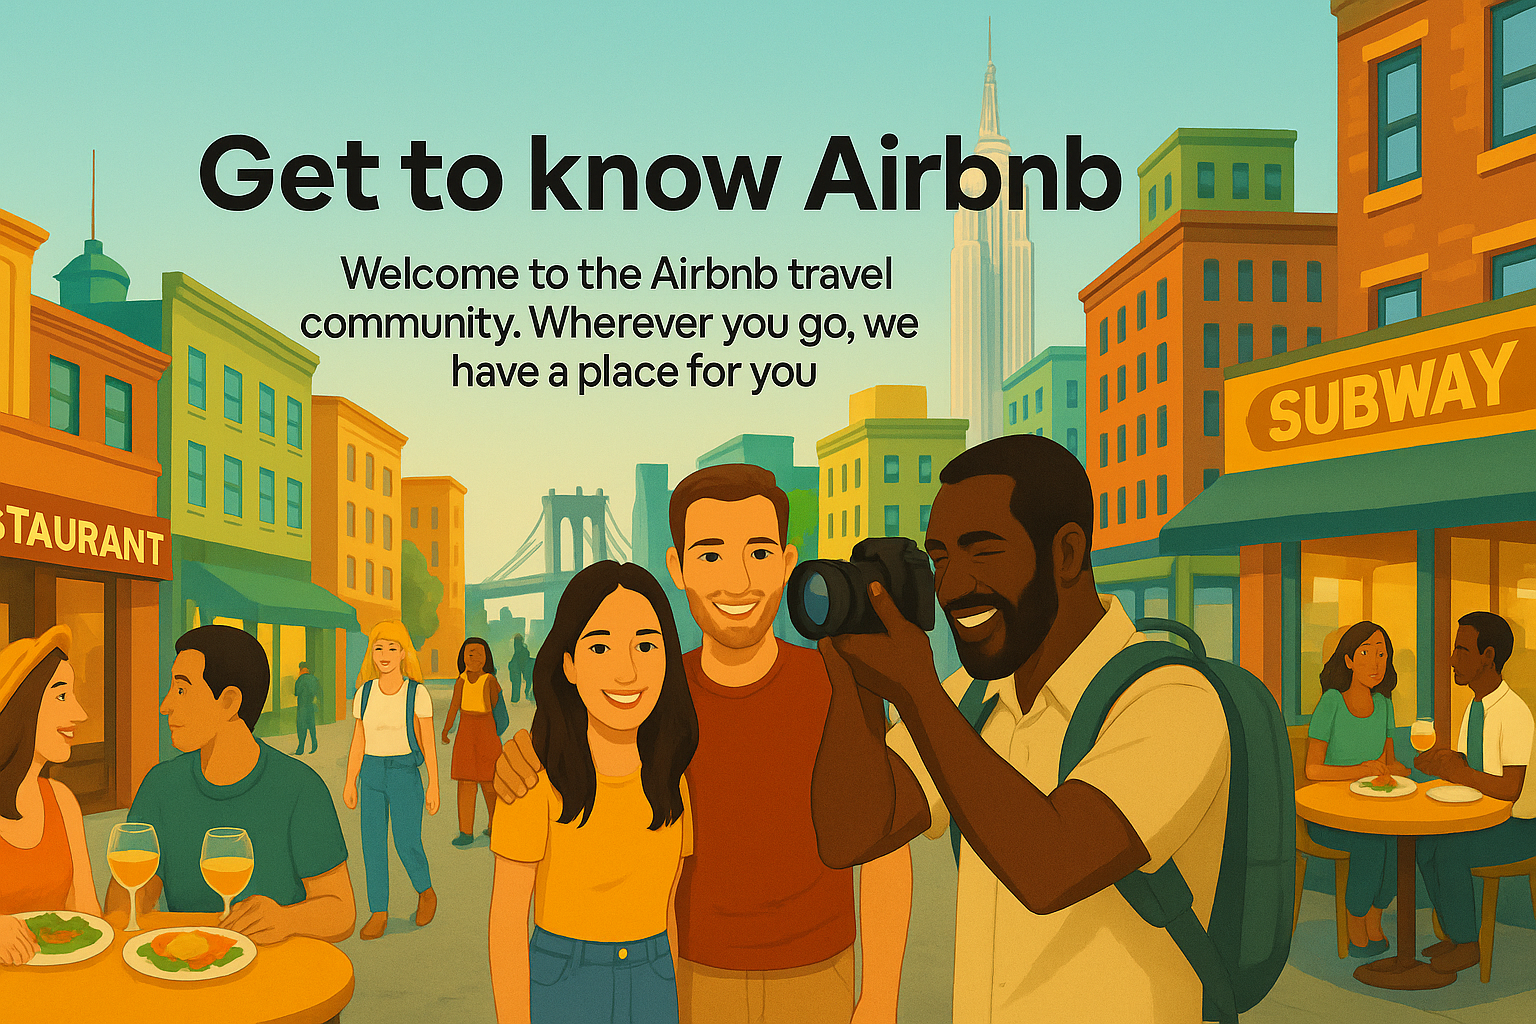

## ***1. Know Your Data***


### **Importing necessary libraries :**

In [ ]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from matplotlib.container import BarContainer
import seaborn as sns
import matplotlib.font_manager as fm

import warnings
warnings.filterwarnings('ignore')

In [ ]:
#-------------------------------
# Importing Required Libraries
# ------------------------------

# NumPy is used for numerical operations on arrays and matrices
import numpy as np

# Pandas is used for data manipulation and analysis (e.g., DataFrames)
import pandas as pd

# Matplotlib is a basic plotting library; pyplot provides a MATLAB-like interface
import matplotlib.pyplot as plt

# Displays matplotlib plots inline within a Jupyter Notebook
%matplotlib inline

# Used to access and manipulate bar containers in bar plots
from matplotlib.container import BarContainer

# Seaborn is a higher-level interface for drawing attractive statistical graphics
import seaborn as sns

# Provides tools to manage and customize fonts in matplotlib plots
import matplotlib.font_manager as fm

# ------------------------------
# Suppress Warning Messages
# ------------------------------

# Disable warning messages to keep the notebook output clean
import warnings
warnings.filterwarnings('ignore')


### **Load Airbnb Dataset**

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

In [ ]:
# Load Dataset
file_path = '/content/drive/MyDrive/Almabetter Full Stack Data Science Course/Module 2/EDA Airbnb Project/Airbnb NYC 2019.csv'
df = pd.read_csv(file_path)


In [ ]:
# copying the data frame and perform EDA on the copied df in order to save the original df as a backup
airbnb_df = df.copy()

### Dataset First View

In [ ]:
# Dataset First Look
airbnb_df.head()   # displays the first 5 rows of the DataFrame

In [ ]:
airbnb_df.tail()  # Displays the last 5 rows of the DataFrame

In [ ]:
# Display the DataFrame as whole
airbnb_df

### Dataset Rows & Columns count

In [ ]:
# Dataset Rows & Columns count
airbnb_df.shape

From the above output we are able to confirm that the airbnb_df DataFrame that we have created using Airbnb NYC 2019.csv file  have       
rows(index) = 48895 and columns(variables) = 16.

### Dataset Information

In [ ]:
# Dataset Info
airbnb_df.info()

### **Referring the above table we have made following observations for DataFrame airbnb_df :**

* There are **7 columns** having named as **id**, **host_id**, **price**, **minimum_nights**, **number_of_reviews**, **calculated_host_listings_count** & **availability_365** are having Data Type as **'int64'**.This Data Type comes under **Numerical Variable Category.**

* Whereas there are **6 columns** having named as **name**, **host_name**, **neighbourhood_group**, **neighbourhood**, **room_type** & **last_review** are having Data Type as **'object'** which also comes under **Categorical Variable Category.**


* Followed by **3 columns** having named as **latitude**, **longitude** & **reviews_per_month** are having Data Type as **'float64'**. This Data Type also comes under **Numerical Variable Category.**






#### Duplicate Values

In [ ]:
# Dataset Duplicate Value Count
duplicate_airbnb_df = airbnb_df.duplicated()

In [ ]:
# Check for duplicate values in airbnb_df dataframe:
airbnb_df[duplicate_airbnb_df]

In [ ]:
# Count for duplicate values in the airbnb_df dataframe:
duplicate_count = airbnb_df.duplicated().sum()
print(f"Number of duplicate rows: {duplicate_count}")


So from the above result we can conclude that the airbnb_df DataFrame made from Airbnb NYC 2019.csv file does not contains any exact duplicate values of rows in them

----------------

### Handling Near-Duplicate Listings


#### Why we handle near-duplicate listings?

While analyzing Airbnb listings, we noticed that some properties are listed multiple times with the same name, host, location, and room type — but have slight differences such as ID, price, or review history. These are likely repeated entries of the same listing posted at different times or with slight adjustments.

For this EDA, where the goal is to understand the **current state of the market**, we want to avoid over-counting these repeated entries. So we will keep only the **most recent version** of each listing by dropping near-duplicates based on key features, while keeping the most updated entry using the `last_review` column as a timestamp.


In [ ]:
# Shape before removing near-duplicate from airbnb dataframe.
airbnb_df.shape

In [ ]:
# Checking datatype of 'last_review' column BEFORE changing the datatype format.
print(airbnb_df['last_review'].dtype)

In [ ]:
# Make a full copy of the original Airbnb dataset to preserve the raw data before making any transformations.
original_df = airbnb_df.copy()

# Convert the 'last_review' column from string/object format to pandas datetime format for time-based operations.
airbnb_df['last_review'] = pd.to_datetime(airbnb_df['last_review'])

# Fill missing 'last_review' values (NaT , i.e " Not a Time") with the latest known review date.
# This avoids issues during sorting when some listings lack review dates.
airbnb_df['last_review'].fillna(airbnb_df['last_review'].max(), inplace=True)

# Sort the dataset in descending order of 'last_review' so that the most recently reviewed listing appears first.
# This helps keep the most updated version when dropping duplicates.
airbnb_df = airbnb_df.sort_values(by='last_review', ascending=False)

# Drop near-duplicate listings based on a subset of features.
# If two or more listings have the same name, host, neighborhood group, neighborhood, and room type,
# only the most recent one is kept.
airbnb_df = airbnb_df.drop_duplicates(
    subset=['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type'],
    keep='first'  # Keep the first occurrence (which is now the most recent due to sorting)
).reset_index(drop=True) # Reset index for clean DataFrame

# Print the shape of the dataset after removing near-duplicates to show how many listings remain.
print("Shape after removing near-duplicates:", airbnb_df.shape)

# Check for any remaining duplicates based on the same subset of columns.
# This should ideally return 0.
print("Remaining near-duplicates:",
      airbnb_df.duplicated(subset=['name', 'host_name', 'neighbourhood_group', 'neighbourhood', 'room_type']).sum())


In [ ]:
# Checking datatype of 'last_review' column AFTER changing the datatype format.
print(airbnb_df['last_review'].dtype)

*   We can observe that the datatype of
'last_review' column is changed from "object" datatype to "datetime64[ns]" datatype.

*   Also we can conclude that shape of airbnb_df DataFrame after eliminating Near-duplicate listings from the dataframe went from (48895, 16) to (48662, 16).


In [ ]:
# ---------------------------- VISUALIZE BEFORE VS AFTER COMPARISON ----------------------------

# Create a bar chart to visualize the number of listings before and after duplicate removal.
plt.figure(figsize=(8, 4)) # Set plot size (width=8 inches, height=4 inches)

# Create a simple barplot using seaborn
ax = sns.barplot(x=['Before', 'After'], # X-axis labels
                 y=[original_df.shape[0], airbnb_df.shape[0]], # Y-axis values based on row counts
                 palette='pastel'  # Use a light pastel color palette for aesthetics
                 )

# Add data labels (actual values) on top of each bar for clarity:
for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=10, color='black')

# Add plot title and Y-axis label
plt.title('Listings Count Before vs After Removing Near-Duplicates')
plt.ylabel('Number of Listings')

# Display the plot
plt.show()


#### Missing Values/Null Values

In [ ]:
# Check for Missing Values/Null Values Count
missing_values = airbnb_df.isnull().sum()
print(missing_values)


### From the above table we are able make following observations :


* The column named as **name** contains **16 Null Values**.

* The column named as **host_name** contains **21 Null Values.**

* The column named as **reviews_per_month** contains **9989 Null Values each**.




In [ ]:
# Creating a series for missing value for visualization:
missing_values_series = pd.Series(missing_values, name='Missing Values')

In [ ]:
# Visualizing the missing values
plt.figure(figsize=(12, 8))
ax = sns.barplot(x=missing_values_series.index, y=missing_values_series.values)
plt.xticks(rotation = 45, ha ='right')  #Rotate x-axis labels for better readability
plt.title('Missing Value Counts', fontweight='bold')
plt.xlabel('Columns Names', fontsize=12)
plt.ylabel('Number of Missing Values', fontsize=12)

# # Adding count label above each bar:
for container in ax.containers:
    ax.bar_label(container, fmt='%d', fontsize=10, color='red')

plt.tight_layout()
plt.show()

**Missing Value Chart: Point-wise Summary**

1.   **Most Columns Are Complete:**

 *   The majority of columns in the dataset (such as id, host_id, neighbourhood_group, neighbourhood, latitude, longitude, room_type, price, minimum_nights, number_of_reviews, last_review, calculated_host_listings_count, and availability_365) have zero missing values.

2.   **Minimal Missing Values in Name Columns:**

 *   The name column has 16 missing values.
 *   The host_name column has 21 missing values.

 *   These numbers are very small compared to the total dataset size and will not significantly impact analysis.


3.   **One Column with Significant Missing Data:**

 *   The reviews_per_month column has 9,989 missing values, which is a substantial proportion of the dataset.



4.   **Reason for Missing Reviews per Month:**

 *   The high number of missing values in reviews_per_month is likely because many listings have never received a review, so there is no data to record for this column.


5.   **Business Insight:**

 *   The large number of listings with no reviews highlights an opportunity for Airbnb to investigate why these properties are not being booked or reviewed.

 *   This could guide strategies for host support or listing improvements.






# What did you know about your dataset?

###**About the Dataset – Airbnb Bookings**


*   The Orignal Airbnb dataset is consist of  48895 observations from New York , with 16 columns of attributes data.

*   This  Dataset includes both categorical and numeric values, providing a diverse range of information about the listings.

*   This Dataset might prove useful for analyzing market trends and patterns for the Airbnb services in New York and also gain insight about the preferences and behavior of Airbnb guests in the particular NEW YORK listings.

*   This dataset contains information about Airbnb bookings data in New York City for the year 2019. By analyzing this data, we are  able to understand the trends and patterns of Airbnb service useage in the NEW YORK CITY.

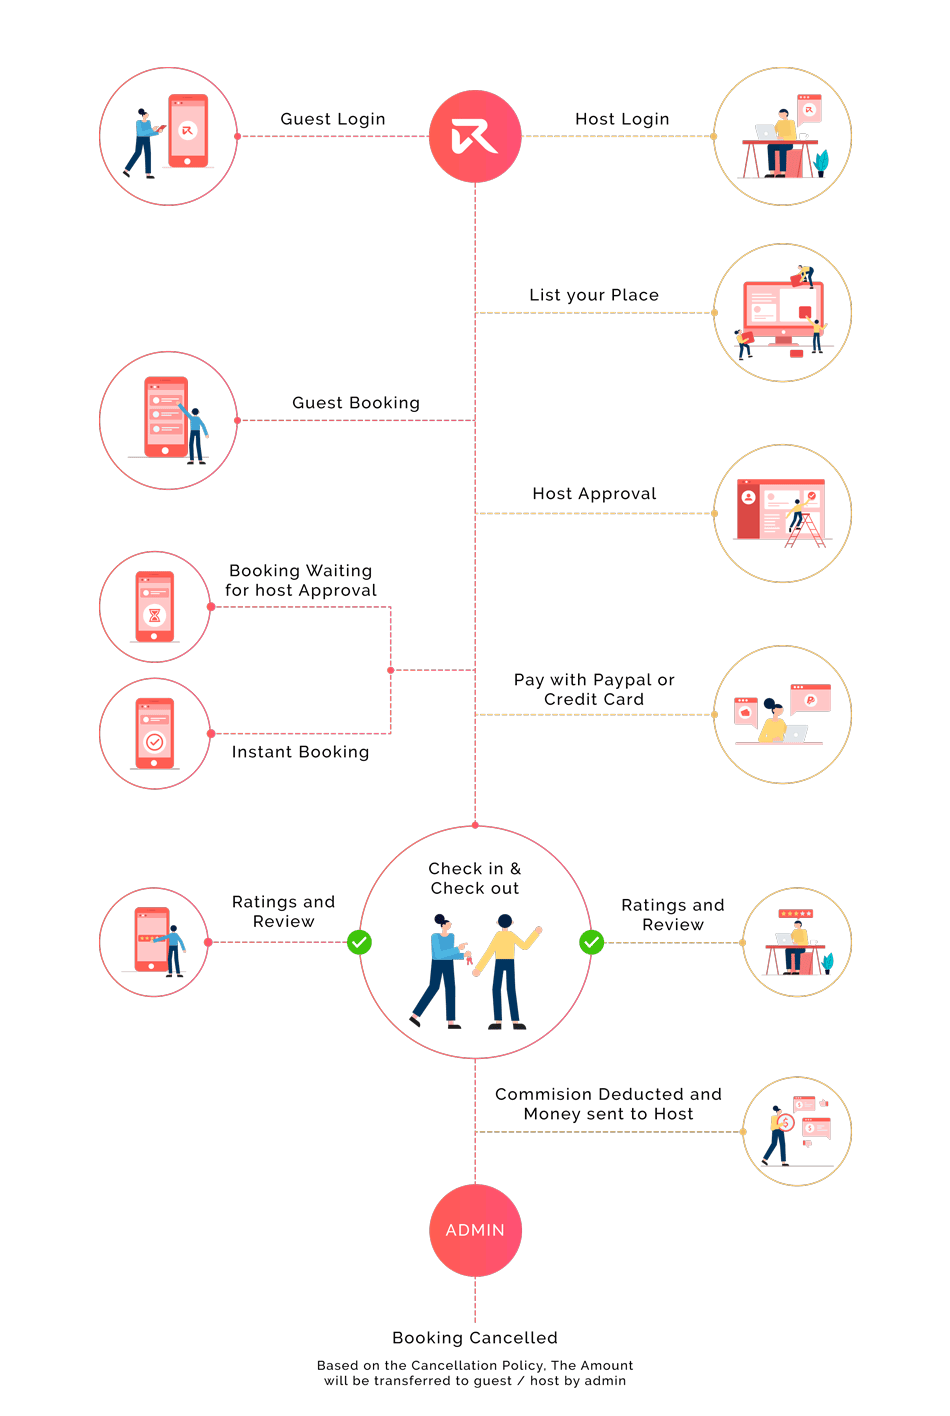

# Data Cleaning and Preprocessing :


*   For analysis purpose, we are going to replace the np.nan / Null values in columns named as **name** and **host_name** by **"Unknown"** & **"No Name"** as they have least null values in them (i.e **name** = 16 Null values and **host_name** = 21 Null values respectively).

*   Furthermore, for preparing DataFrame for our analysis. In the column named reviews_per_month we are replacing the np.nan / Null Values with value = '0' having Datatype as 'float64'.






In [ ]:
# Replace Null values in "name" and "host_name" column by "Unknown" values and "No Name" values respectively:
airbnb_df['name'].fillna('Unknown', inplace=True)     # both are of datatype = 'object'
airbnb_df['host_name'].fillna('No Name', inplace=True)

In [ ]:
# Check for Example for 'Unknown' in 'name' column of 'airbnb' DataFrame :
Unknown_check = airbnb_df[airbnb_df['name'] == 'Unknown']
Unknown_check.head()

In [ ]:
# Example for 'No Name' in 'host_name' column of 'airbnb' DataFrame :
No_Name_check = airbnb_df[airbnb_df['host_name'] == 'No Name']
No_Name_check.head()

In [ ]:
airbnb_df['reviews_per_month'].dtype

In [ ]:
# Replace the "np.nan" values present in the "reviews_per_month" column if Airbnb DataFrame with "0" (Zero) Values:
airbnb_df['reviews_per_month'] = airbnb_df['reviews_per_month'].replace(to_replace = np.nan, value=0).astype('float64')    # assigning reviews_per_month column Datatype as 'int64'

In [ ]:
# Example for '0' value in 'reviews_per_month'column in 'airbnb_df' DataFrame :
reviews_per_month_check = airbnb_df[airbnb_df['reviews_per_month'] == 0]
reviews_per_month_check.head()

In [ ]:
# Checking again for Null Values
airbnb_df[['name','host_name','reviews_per_month']].isnull().sum()

Hence, all missing values from the 'name', 'host_name', and 'reviews_per_month' columns in the airbnb_df DataFrame have been dealt with.

In [ ]:
# Renaming the column names for better understanding

rename_column = {'id':'listing_id', 'name':'listing_name', 'calculated_host_listings_count':'host_listings_count', 'number_of_reviews':'total_reviews'}  # Creating a dictionaty of Selection of column for renaming

# Renaming the columns in the airbnb_df by using rename_column dict.

airbnb_df = airbnb_df.rename(columns = rename_column)

In [ ]:
# Now checking the overall Final airbnb_df DataFrame for our analysis
airbnb_df.sample(10)   # .sample() method display random rows of the DataFrame.

## ***2. Understanding Your Variables***

In [ ]:
# Dataset Columns
airbnb_df.columns.to_list()

In [ ]:
# Shape of final airbnb_df
airbnb_df.shape

So our finalised **airbnb_df** DataFrame contains **48662 rows** and **16 columns** respectively.

In [ ]:
# Obtaining the info for final airbnb_df
airbnb_df.info()

## Finalized Airbnb DataFrame Variables Description



1.   **listing_id** : Unique identifier for each listing. (Datatype: Integer)

2.   **listing_name** : Name of the listing (e.g., "Cozy Studio in Manhattan"). (Data type: String)

3.   **host_id** : Unique identifier for each host. (Data type: Integer)

4.   **host_name** : Name of the host. (Data type: String)

5.   **neighbourhood_group** : Higher-level geographical location (e.g., "Manhattan"). (Data type: String)

6.   **neighbourhood** : Specific neighborhood within the group (e.g., "West Village"). (Data type: String)

7.   **latitude** : Geographical latitude coordinate of the listing. (Data type: Float)

8.   **longitude** : Geographical longitude coordinate of the listing. (Data type: Float)
9.   **room_type** : Type of accommodation (e.g., "Entire home/apt", "Private room", "Shared room"). (Data type: String)


10.   **price** : Price per night for the listing. (Data type: Float)
11.   **minimum_night** : Minimum number of nights required for a booking. (Data type: Integer)

12.   **total_reviews** : Total number of reviews received for the listing. (Data type: Integer)  

13.   **last_review** : The date when the most recent review was left for a listing. (Data type: datetime64[ns])

14.   **reviews_per_month** : Average number of reviews received per month. (Data type: Float)

15.   **host_listings_count** : Total number of listings hosted by the same host. (Data type: Integer)

16.   **availability_365** : Number of days the listing is available for booking in the next year. (Data type: Integer)







### Check Unique Values for each variable.

In [ ]:
# Check Unique Values for each variable :

# Check for number of unique value in 'listing_id' column #

# All the values in the 'listing_id' columns are Unique Identifier for each listing in the Airbnb dataset. therefore all the values in the listing_id are expected to be unique in nature.
airbnb_df['listing_id'].nunique()

In [ ]:
# check number of  Unique value for 'listing_name' column
airbnb_df['listing_name'].nunique()

In [ ]:
# Check number of Unique Value for 'host_id' column :
airbnb_df['host_id'].nunique()

In [ ]:
# check number of  Unique value for 'host_name' column :
airbnb_df['host_name'].nunique()

In [ ]:
# Check for number of unique value for 'neighbourhood_group' column :
airbnb_df['neighbourhood_group'].nunique()

In [ ]:
# Check for number of unique value for 'neighbourhood' column :
airbnb_df['neighbourhood'].nunique()

In [ ]:
# Check for number of unique value for 'latitude' column :
airbnb_df['latitude'].nunique()

In [ ]:
# Check for number of unique value for 'longitude' column :
airbnb_df['longitude'].nunique()

In [ ]:
# Check for number of unique value for 'room_type' column :
airbnb_df['room_type'].nunique()

In [ ]:
# Check for number of unique value for 'price' column :
airbnb_df['price'].nunique()

In [ ]:
# Check for number of unique value for 'minimum_nights' column :
airbnb_df['minimum_nights'].nunique()

In [ ]:
# Check for number of unique value for 'total_reviews' column :
airbnb_df['total_reviews'].nunique()

In [ ]:
# Check for number of unique value for 'last_review' column :
airbnb_df['last_review'].nunique()

In [ ]:
# Check for number of unique value for 'reviews_per_month' column :
airbnb_df['reviews_per_month'].nunique()

In [ ]:
# Check for number of unique value for 'host_listings_count' column :
airbnb_df['host_listings_count'].nunique()

In [ ]:
# Check for number of unique value for 'availability_365' column :
airbnb_df['availability_365'].nunique()

NOTE :
*    On comparing the number of unique number for 'listing_name' column (i.e 47906) and the total count of values in  'listing_id' column  (i.e 48662). Both the values are mismatch with each other.

*   Because of this situation we can assume that the 'listing_name'(Property/ Room/ Villa) column have few repeated names in the same column and the host_name against the same repeated value are different for different neighnourhood of neighnourhood_group.


In [ ]:
# CASE I

# Let us obeserve the reason behind the difference between the number of unique values for listing_id column and listing_name.

# Group by listing_name and aggregate listing_ids and count
repeating_listings = airbnb_df.groupby('listing_name').agg(
    listing_ids=('listing_id', list),  # Aggregate listing_ids into a list
    count=('listing_id', 'nunique')   # Count unique listing_ids
).reset_index()


# Filter for repeating names
repeating_listings = repeating_listings[repeating_listings['count'] > 1]

# Sort the count values in descending order
repeating_listings = repeating_listings.sort_values(by='count', ascending=False)

# Reset the index to get rid of the unnamed column
repeating_listings = repeating_listings.reset_index(drop=True)


# Display the table
repeating_listings.head(10)

In [ ]:
# CASE II
# Observing rows where the values in 'listing_name' column and values in 'host_name' column are same .
airbnb_df[airbnb_df['listing_name'] == airbnb_df['host_name']].sample(10)

In [ ]:
# CASE III

# Observing a subset where same 'host_name' and same 'neighbourhood_group' values have different 'listing_name' values againts them.

airbnb_df.loc[(airbnb_df['neighbourhood_group']=='Manhattan') & (airbnb_df['host_name']=='Jennifer')].head(5)

---------------------

### Removing outlier before Data Wrangling steps:###



In [ ]:
airbnb_df.describe()

In [ ]:
# For EDA analysis purpose the outlier for 'price' column is important to identify.
plt.figure(figsize=(10, 6))
sns.boxplot(x = airbnb_df['price'])  # using box plot to visualise the outliers in  the price column.
plt.title('Outlier Detection in Price Column')

plt.show()

In [ ]:
# Let's observe the Overall Price Distribution of airbnb DataFrame.
# Set the figure size:
plt.figure(figsize=(12, 8))  # Width = 12 inches and Height = 8 inches.

# Set the theme style of the plot:
sns.set_style('darkgrid')

# Create a Histogram with the help of Seaborn Library:
sns.histplot(airbnb_df['price'], # Data Source for plotting histogram,
             bins=200, # Divides the data into 200 bins for the histogram.
             kde=True, # Add  a Kernel Density Estimation (KDE) Curve to the plot, to show the overall distribution.
             color='red', # Add color to the histogram bars.
             edgecolor='black' # Adds colors to the edges of the histogram bars.
             )

# Set the Title of the plot :
plt.title("Overall Price Distibution of Airbnb DataSet", fontweight='bold', fontsize=15) # fontstyle and fontsize editied.

# Set the label on X-axis:
plt.xlabel("Price")

# Set the label on Y-axis:
plt.ylabel("Frequency")

# Adjust the layout of the plot for better visibility:
plt.tight_layout()

# Display the chart below the code cell.
plt.show()

**Summary Insight of Over All Price Distribution of Airbnb Dataset :**


*   **Distribution Shape :** The histogram displays a highly right-skewed (positively skewed) distribution. The vast majority of Airbnb listings are clustered at the lowest end of the price spectrum, and the frequency drops off steeply as price increases.


*   **Peak and Frequency :** The highest frequency occurs in the lowest price bins, with the tallest bar exceeding 16,000 listings. This indicates that most Airbnb accommodations are offered at very low prices.


*   **Price Range and Spread :** As the price increases, the number of listings drops sharply, showing that mid- to high-priced listings are much less common.

*   **Long Tail and Outliers :** There is a pronounced long tail stretching up to 10,000, representing a small number of very expensive listings. These outliers have minimal impact on the overall frequency but significantly extend the price range.


*   **Central Tendency and Implications :** The strong right skew suggests that the mean price would be heavily influenced by a few high-priced outliers, making the median a more representative measure of central tendency for this dataset. Most users will encounter affordable listings, while luxury or premium-priced options are uncommon.



*   **Market Insight :** The distribution highlights a market dominated by budget-friendly accommodations. The small number of high-priced listings may reflect luxury properties or unique offerings, but these are not typical of the broader Airbnb market.



In [ ]:
# Price columns stats BEFORE removing outliers from the 'price' column of Airbnb DataFrame:
max_airbnb_df = airbnb_df[airbnb_df['price'] == airbnb_df['price'].max()]
min_airbnb_df = airbnb_df[airbnb_df['price'] == airbnb_df['price'].min()]
print(f'The maximmum price value of airbnb dataframe is : {max_airbnb_df["price"].max()}')
print(f'The minimum price value of airbnb dataframe is : {min_airbnb_df["price"].min()}')

In [ ]:
# Creating a custom function for removing outlier from a particular Column of particular DataFrame and simultaneously plotting a Boxplot graph.

def remove_outlier_iqr_and_plot(df, column_name):
  """ Removes outliers from a particular column and plot a boxplot.

  Args:
    df: input Pandas DataFrame.
    column_name : Name of column to process.

  Returns:
    DataFrame without upper outliers.

  """
  # Calculate Outlier Q1 :

  Q1 = df[column_name].quantile(0.25) # 25th percentile

  # Calculate Outlier Q3 :
  Q3 = df[column_name].quantile(0.75) # 75th percentile

  # Calculate Inter Quartile Range (IQR)

  IQR = Q3 - Q1

  # Calculate Upper bound (luxury threshold) :
  upper_bound = Q3 + 1.5 * IQR                   # Upper threshold for the outliers.

  # Calculate Lower bound (affordable threshold) :
  lower_bound = Q1 - 1.5 * IQR                   # Lower threshold for the outliers.

  # Filtering out the Upper Outliers but keeping the prices <= upper bound.
  no_outlier_df = df[df[column_name] <= upper_bound]


  # Here we are not considering to remove lower bound outliers because
  # In Airbnb pricing, extremely low values may still be valid.
  # Removing them could eliminate budget-friendly listings, which is essential for customer analysis.

  # Creating Boxplot for visualisation
  plt.figure(figsize=(8 , 6))
  sns.boxplot(x=no_outlier_df[column_name],showfliers=False, palette='Set2') # showfliers = False hides outliers in the plot. # palette = sets the color of the boxplot.
  plt.title(f'Boxplot of {column_name} (Outliers Removed)')
  plt.xlabel(column_name) # label for the vertical axis
  plt.show()

  return no_outlier_df



In [ ]:
# Finding outlier for 'price' column in 'airbnb_df' and plotting a boxplot simultaneously by applying the function 'find_and_plot_outliers' :

## Create a new DataFrame named as Filtered Airbnb DataFrame:
filtered_airbnb_df = remove_outlier_iqr_and_plot(airbnb_df, 'price')

In [ ]:
# Price columns stats AFTER removing outliers from the 'price' column of Airbnb DataFrame:

max_filtered_airbnb_df = filtered_airbnb_df[filtered_airbnb_df['price'] == filtered_airbnb_df['price'].max()]
min_filtered_airbnb_df = filtered_airbnb_df[filtered_airbnb_df['price'] == filtered_airbnb_df['price'].min()]
print(f'The maximmum price value of filtered airbnb dataframe is : {max_filtered_airbnb_df["price"].max()}')
print(f'The minimum price value of filtered airbnb dataframe is : {min_filtered_airbnb_df["price"].min()}')

In [ ]:
# Removing Zero-Priced Listings from 'filtered_airbnb_df' #

# Check for zero values in the filtered_airbnb_df :
zero_check_price_filtered_airbnb_df = filtered_airbnb_df[filtered_airbnb_df['price'] == 0]['price'].count()
print(f'The number of zero values present in the Airbnb DataFrame is:{zero_check_price_filtered_airbnb_df}')

As there are total 11 number of row where the value of the price column is zero(0) in Airbnb DataFrame.

Because of this followings issues might occur in future:

*   Zero is an Unrealistic Price for an Airbnb Stay.
*   No Airbnb listing is genuinely available for free. A price of 0 is likely a data entry error or an incomplete listing

*   Including 0 lowers the mean and median price, misrepresenting affordability.As It skews data visualizations like histograms and box plots, making price trends unclear.

*   zero priced listings do not help customers or business stakeholders understand real pricing trends.
*   Filtering out errors enhances the reliability of findings in availability, demand, and pricing strategy.


In [ ]:
# Remove listings with price == 0
filtered_airbnb_df = filtered_airbnb_df[filtered_airbnb_df['price'] > 0]

In [ ]:
### Creating The Final DataFrames ###

# AFFORDABLE LISTINGS ( Price <= 334 , with zero removed)
affordable_airbnb_df = filtered_airbnb_df[filtered_airbnb_df['price'] <= 334]

# LUXURY LISTINGS (Price > 334)
luxury_airbnb_df = airbnb_df[airbnb_df['price'] > 334]


print(f'Final Affordable Listings Count: {len(affordable_airbnb_df)}')
print(f'Final Luxury Listings Count: {len(luxury_airbnb_df)}')


In [ ]:
# Check for Zero price listings in Luxury Segments:
zero_check_luxury_airbnb_df = luxury_airbnb_df[luxury_airbnb_df['price'] == 0]['price'].count()
print(f'The number of zero values present in price column of  the Luxury Airbnb DataFrame is:{zero_check_luxury_airbnb_df}')

## 3. ***Data Wrangling & Data Visualization***

### Data Wrangling Code

In [ ]:
# Check max price and min price for both DataFrame:

## Affordable Airbnb Listings Price Range ##
max_affordable_price = affordable_airbnb_df['price'].max()
min_affordable_price = affordable_airbnb_df['price'].min()
dtype_affordable_price = affordable_airbnb_df['price'].dtype

print(f"Maximum Affordable Airbnb price: {max_affordable_price}")
print(f"Minimum Affordable Airbnb price: {min_affordable_price}")
print(f"Datatype  Affordable Airbnb price: {dtype_affordable_price}")

## Luxury Airbnb Listings Price Range ##
max_luxury_price = luxury_airbnb_df['price'].max()
min_luxury_price = luxury_airbnb_df['price'].min()
dtype_luxury_price = luxury_airbnb_df['price'].dtype

print(f'Maximum Luxury Airbnb price: {max_luxury_price}')
print(f'Minimum Luxury Airbnb price: {min_luxury_price}')
print(f'Datatype  Luxury Airbnb price: {dtype_luxury_price}')


In [ ]:
# Columns names of affordable_airbnb_df DataFrame:
affordable_airbnb_df.columns

In [ ]:
# Columns names of affordable_airbnb_df DataFrame:
luxury_airbnb_df.columns

In [ ]:
# Let's rename the 'price' and 'price_range' cloumns for better clarity:
affordable_airbnb_df.rename(columns={'price': 'affordable_price', 'price_range': 'affordable_price_range'}, inplace=True)
luxury_airbnb_df.rename(columns={'price': 'luxury_price', 'price_range': 'luxury_price_range'}, inplace=True)

In [ ]:
# Sample Affordable segment DataFrame :
affordable_airbnb_df.sample(5)

In [ ]:
# Sample Luxuey Segment DataFrame :
luxury_airbnb_df.sample(5)

# Univariate Questions :

----
***(U01) Question 1 : What is the distribution of Airbnb listings across different price ranges for both affordable and luxury segments, and what are the key price brackets that maximize occupancy and revenue?***

----

In [ ]:
# Create a custom function for creating price_range column with proper bins:
def price_range_creator(amt, start=0, end=10000, step=25, luxury=False):
    """
    Function to categorize price into ranges.
    If `luxury=True`, use larger bins to improve readability.

    Args:
        amt (int or float): The price amount to categorize.
        start (int): The starting value for the price range. Defaults to 0.
        end (int): The ending value for the price range. Defaults to 10000.
        step (int): The increment for the price range bins. Defaults to 25.
        luxury (bool): If True, use a larger bin size for luxury listings. Defaults to False.

    Returns:
        str: The price range category for the given price amount.
             Returns "unknown" if the amount is outside the specified range.
    """

    if luxury:
        step = 50  # Larger bin size for luxury listings.

    bins = np.arange(start, end + step, step)  # This line ensures that the last bin is included.
    labels = [f"{bins[i]:04d} - {bins[i+1]-1:04d}" for i in range(len(bins)-1)] # Correction made in labels (0000-0024,0025-0050,...etc)

    for i in range(len(bins) - 1):
        if bins[i] <= amt <= bins[i + 1]:   # Ensures 24 is in "0000 - 0024" an NOT in "0025 - 0050"
            return labels[i]
    return "unknown"



In [ ]:
# let's apply the function to create price range categories:
affordable_airbnb_df['affordable_price_range'] = affordable_airbnb_df['affordable_price'].apply(lambda x: price_range_creator(x))
luxury_airbnb_df['luxury_price_range'] = luxury_airbnb_df['luxury_price'].apply(lambda x: price_range_creator(x, luxury=True))

In [ ]:
# Count the occurance and calculate the percentages for affordable listings:
affordable_price_counts = affordable_airbnb_df['affordable_price_range'].value_counts().sort_index()
affordable_price_count_percentages = (affordable_price_counts / len(affordable_airbnb_df)) * 100
affordable_disrtibution = affordable_price_count_percentages.reset_index()
affordable_disrtibution.columns = ['affordable_price_range', 'affordable_price_percentage']

In [ ]:
# Count the occurance and calculate the percentages for luxury listings:
luxury_price_counts = luxury_airbnb_df['luxury_price_range'].value_counts().sort_index()
luxury_price_count_percentages = (luxury_price_counts / len(luxury_airbnb_df)) * 100
luxury_distribution = luxury_price_count_percentages.reset_index()
luxury_distribution.columns =['luxury_price_range', 'luxury_price_percentage']

In [ ]:
affordable_airbnb_df.head()

In [ ]:
luxury_airbnb_df.head(5)

In [ ]:
# ----------- Plot for Affordable Listings -------------------#

# Set the figure size:
plt.figure(figsize=(12,8)) # Width = 12 inches and height = 8 inches.

# Create a Barplot using Seaborn as Library:
ax1 = sns.barplot(
    x='affordable_price_range', # Plots 'affordable_price-range' column values on x-axis.
    y='affordable_price_percentage', # Plots 'affordable_price_percentage' column values on the y-axis.
    data=affordable_disrtibution, # Dataframe source for data
    palette = 'rocket' # Set the colors to 'rocket' for the bars present in the barplot.
)

# Set the labels for the x-axis and y-axis:
plt.xlabel('Affordable Price Range', fontsize=12) # for x-axis.
plt.ylabel('Percentage of Listings', fontsize=12) # for y-axis.

# Set the title for the Plot:
plt.title('Distribution of Affordable Airbnb Listings Across Price Ranges',
          fontsize=14, # Adjust the fontsize to 14
          fontweight='bold' # Sets the fontstyle as bold
          )

# Set the ticks on the respective axis:
plt.xticks(rotation=90, # ticks arranged on the x-axis are roatated on 90 degrees.
           ha='center', # horizontal alignment = center
           fontsize=10 # the fontsize is set to 10 on x-axis.
           )
plt.yticks(fontsize=10) # The fontsize on the y-axis is set to 10.

# Add grid to the plots:
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Adding percentage labels using `ax.containers`
for container in ax1.containers:
    ax1.bar_label(container, fmt='%.2f%%', label_type='edge', fontsize=10, padding=3, color='black')

# Adjust the layout of the plot:
plt.tight_layout()

# Display the plot below the code:
plt.show()

***Affordable Segment Chart : Distribution of Affordable Airbnb Listings Across Price Ranges***

1.   **Why did you pick the specific chart?**
      *   This bar chart clearly visualizes the percentage distribution of affordable Airbnb listings across defined price ranges. It allows for quick identification of the most common price brackets within the affordable segment, helping stakeholders understand market concentration and guest price sensitivity.

2.   **What is/are the insight(s) found from the chart?**
      *   Most listings (over 51%) are priced between $25 and $99 per night—specifically, the $50–$74 and $75–$99 ranges each account for nearly 19% of listings.
      *   The $100–$149 range is also significant, holding about 22% of listings.
      *   Listings priced below $25 or above $200 are rare, each representing less than 5% of the market
      
3.   **Will the gained insights help create a positive business impact?**
      *   **Yes.**
          *   **Pricing Strategy:** Hosts and Airbnb can focus on optimizing pricing and promotions in the $50–$149 range, where demand and supply are highest, to maximize occupancy and revenue.
          *   **Product Positioning:** New or repositioned listings should target these brackets to quickly attract bookings.
          *   **Inventory Planning:** Airbnb can encourage more listings in these popular price brackets to meet guest demand and improve platform competitiveness.




4.   **Are there any insights that lead to negative growth? Justify with specific reason.**
      *   **Yes, if ignored:**
          *   **Overpricing or Underpricing:** Listings priced below $25 or above $200 are in low demand, which can lead to low occupancy and revenue for hosts in those brackets.
          *   **Market Saturation Risk:** Excessive competition in the $50–$99 range may drive down prices or reduce margins if not managed with value-added services or differentiation.


In [ ]:
# ----------- Plot for Luxury Listings -------------------#

# Set the figure size:
plt.figure(figsize=(15,8)) # Width = 12 inches and height = 8 inches.

# Create a Barplot using Seaborn as Library:
ax2 = sns.barplot(
    x='luxury_price_range', # Plots 'luxury_price_range' column values on x-axis.
    y='luxury_price_percentage', # Plots 'luxury_price_percentage' column values on the y-axis.
    data = luxury_distribution, # Dataframe source for data
    palette = 'viridis' # Set the colors to 'viridis' for the bars present in the barplot.
)

# Set the labels for the x-axis and y-axis:
plt.xlabel('Luxury Price Range', fontsize=12) # for x-axis.
plt.ylabel('Percentage of Listings', fontsize=12) # for y-axis.

# Set the title for the Plot:
plt.title('Distribution of Luxury Airbnb Listings Across Price Ranges',
          fontsize=14, # Adjust the fontsize to 14
          fontweight='bold' # Sets the fontstyle as bold
          )

# Set the ticks on the respective axis:
plt.xticks(rotation=90, # ticks arranged on the x-axis are roatated on 90 degrees.
           ha='center', # horizontal alignment = center
           fontsize=10 # the fontsize is set to 10 on x-axis.
           )
plt.yticks(fontsize=9) # The fontsize on the y-axis is set to 10.

# Add grid to the plots:
plt.grid(axis='y', linestyle='--', alpha=0.5)

# Adding percentage labels using `ax.containers`
for container in ax2.containers:
    ax2.bar_label(container, fmt='%.2f%%', label_type='edge', fontsize=7, padding=2, color='black', rotation=90)

# Adjust the layout of the plot:
plt.tight_layout()

# Display the plot below the code:
plt.show()

***Luxury Segment Chart : Distribution of Luxury Airbnb Listings Across Price Ranges***



1.   **Why did you pick the specific chart?**
      *   This bar chart visualizes the distribution of luxury Airbnb listings across higher price ranges, making it easy to spot the most active price bands and the rapid drop-off in listing share as prices rise.

2.   **What is/are the insight(s) found from the chart?**
      *   Majority of luxury listings (over 65%) are priced between $300 and $499 per night, with the $350–$399 range alone accounting for 23.36%.
      *   There is a sharp decline in listings above $500, and ultra-luxury listings ($1,000+) are extremely rare.
      *   The luxury market is highly concentrated in the lower luxury price bands.

3.   **Will the gained insights help create a positive business impact?**
      *   **Yes.**
          *   **Targeted Marketing:** Focus marketing and guest targeting in the $300–$499 range to maximize both occupancy and revenue.
          *   **Host Guidance:** Advise luxury hosts to price within this range unless they offer exceptional, differentiated value.
          *   **Revenue Optimization:** Airbnb can design premium services or experiences for this core luxury segment to increase booking value and guest satisfaction.


4.   **Are there any insights that lead to negative growth? Justify with specific reason.**
      *   **Yes, if misapplied:**
          *   **Overpricing:** Hosts who price well above $500 without unique offerings will likely face very low occupancy, resulting in lost revenue and potential churn from the platform.
          *   **Niche Overextension:** Expanding inventory in ultra-luxury brackets ($1000+) without sufficient demand can lead to underutilized assets and negative ROI.


***Summary Table :***

| Segment | Key Insight	 | Positive Impact | Negative Growth Risk |
    |----------|:----------:|----------:|:----------:|
    | Affordable | $50–$149 is the most active price range| Maximizes occupancy and revenue if targeted | Over/underpricing leads to low occupancy |
    | Luxury | $300–$499 is the luxury sweet spot | Focused marketing and host guidance increases profitability | Overpricing above $500 reduces bookings |

--------------

---


***(U02) Question 2 : How are Airbnb listings distributed across different neighbourhood groups, and what insights can we derive from location trends?***

-----

In [ ]:
# Let's calculate the Number of Listings in Neighbourhood Groups:
affordable_neighbourhood_counts = affordable_airbnb_df.groupby('neighbourhood_group')['listing_id'].count().reset_index(name='affordable_listings_count')
luxury_neighbourhood_counts = luxury_airbnb_df.groupby('neighbourhood_group')['listing_id'].count().reset_index(name='luxury_listings_count')

In [ ]:
affordable_neighbourhood_counts.head()

In [ ]:
luxury_neighbourhood_counts

In [ ]:
# Calculate the percentage Distribution:
affordable_neighbourhood_counts['affordable_percentage_counts'] = (affordable_neighbourhood_counts['affordable_listings_count'] / len(affordable_airbnb_df['neighbourhood_group'])) * 100
luxury_neighbourhood_counts['luxury_percentage_counts'] = (luxury_neighbourhood_counts['luxury_listings_count'] / len(luxury_airbnb_df['neighbourhood_group'])) * 100

In [ ]:
affordable_neighbourhood_counts

In [ ]:
# Merge both datasets for side by side comparison:
neighbourhood_group_comparison = affordable_neighbourhood_counts.merge(luxury_neighbourhood_counts, on="neighbourhood_group", how="outer").fillna(0)

In [ ]:
# Sort values by Affordablle Listings for better readability:
neighbourhood_group_comparison = neighbourhood_group_comparison.sort_values(by="affordable_percentage_counts", ascending=False)

In [ ]:
# Combined datafame
neighbourhood_group_comparison

In [ ]:
# Define color (same for both pie chart):
common_pie_colors = sns.color_palette("mako", len(neighbourhood_group_comparison))

# create a function to alternate label distance for better readability:
def alternate_pct_distance(pct, index):
    """
    Moves every other label outward to avoid overlapping.

    Parameters:
    pct (float)  : The percentage value.
    index (int)  : The index of the slice in the pie chart.

    Returns:
    str : Formatted string with percentage value, with alternating line breaks to adjust the distance.
    """
    return f'{pct:.1f}%' if index % 2 == 0 else f'\n{pct:.1f}%'

# Define explode values for both pie charts to highlight small slices.
# Exploding slices means pulling them out slightly for better visibility.


# In affordable segment, explode slices where the percentage is less than 5%
explode_affordable = [0.05 if pct < 5 else 0 for pct in neighbourhood_group_comparison['affordable_percentage_counts']]

# In the luxury segment, explode slices where the percentage is less than 5 % ( with silghtly larger gap)
explode_luxury =[0.1 if pct < 5 else 0 for pct in neighbourhood_group_comparison['luxury_percentage_counts']]

# Create a figure with two side-by-side pie charts:
fig, axes = plt.subplots(1, 2, figsize=(12, 8))

# Affordable Segment Pie Charts:
wedges_1, _, autotexts1 = axes[0].pie(
    neighbourhood_group_comparison['affordable_percentage_counts'], # Data Value source.
    labels=None, # Remove direct labels for a cleaner look.
    autopct=lambda pct: alternate_pct_distance(
        pct,
        list(neighbourhood_group_comparison['affordable_percentage_counts']).index(
            min(neighbourhood_group_comparison['affordable_percentage_counts'], key=lambda x: abs(x - pct))
        )

    ) if pct > 0 else "", # Apply alternate label distance.
    startangle=30, # Rotate chart for better alignment.
    textprops={'fontsize': 12}, # Font size for percentage labels
    colors=common_pie_colors, # Use predefned colors.
    explode=explode_affordable, # Explode small slices
    pctdistance=1.12 # Adjust the radial label position.
)
axes[0].set_title('Affordable Airbnb Listings Distribution', fontweight='bold') # Set the title

# Luxury Segment Pie Chart
wedges2, _, autotext2 = axes[1].pie(
    neighbourhood_group_comparison['luxury_percentage_counts'], # Data value source.
    labels=None, # Remove direct labels for a cleaner look
    autopct=lambda pct: alternate_pct_distance(
        pct,
        list(neighbourhood_group_comparison['luxury_percentage_counts']).index(
            min(neighbourhood_group_comparison['luxury_percentage_counts'], key=lambda x:abs(x - pct))

        )
    ) if pct > 0 else "", # Apply alternate label distances.
    startangle=30, # Rotate chart for better alignment.
    textprops={'fontsize': 12}, # Font size for percentage labels
    colors=common_pie_colors, # Use perdefined colors.
    explode=explode_luxury, # Explode small slices.
    pctdistance=1.14 # Adjust the distance of percentage labels slightly further than affordable.
)
axes[1].set_title('Luxury Airbnb Listings Distribution', fontweight='bold') # Set the title.

# Add a shared legend in the center below both the pie charts.
handles = [
    plt.Line2D([0], [0], # [0], [0] defines an invisible point (since the legend doesn't need a line).
               marker='o', # This creates a small circular marker (marker='o') for the legend.
               color='w', # color='w' (white) ensures there is no visible line.
               markerfacecolor=c, #markerfacecolor=c sets the marker’s fill color to match each neighborhood's color in the pie chart.
               markersize=10
               ) # This creates a list of legend markers (colored circles) that correspond to the colors used in the pie charts.
    for c in common_pie_colors # Iterate over each color used in the pie charts
]

# Define bold font properties for the legend title
bold_font = fm.FontProperties(weight='bold')

# Add a shared legend in the center below both pie charts
fig.legend(
    handles, # The legend will use the handles (colored markers).
    neighbourhood_group_comparison['neighbourhood_group'], # The labels for the legend (neighbourhood_groups).
    title='Neighbourhood Groups', # Title displayed above the legend.
    loc="center", # Position legend in the center of the figure.
    bbox_to_anchor=(0.5, 0.05), # Adusts placement of legend (x=0.5 for centering , y=0.05 for positioning below charts)
    fontsize=10, # Font size of the labels in the legend.
    ncol=3, # Number of columns in the legend (prevent it from being too tall)
    title_fontproperties=bold_font,  # This makes the title bold.
)

# Adjust the layout to prevent overlapping of the elements:
plt.tight_layout()

# Display the pie charts:
plt.show()



1.   Why did you pick the specific chart?
      *   Side-by-side pie charts are used because they clearly show the proportion of Airbnb listings in each neighbourhood group for both affordable and luxury segments. This makes it easy to visually compare how each segment is distributed geographically and to spot any significant concentration or gaps.

2.   What is/are the insight(s) found from the chart?
      *   **Affordable Segment (Left Pie Chart) :**
          *   Manhattan (42.5%) and Brooklyn (42.3%) have almost equal shares of affordable listings, together making up nearly 85% of the affordable market.
          *   Queens holds a moderate share at 12.1%.
          *   Bronx (2.3%) and Staten Island (0.8%) have very few affordable listings.

      *   **Luxury Segment (Right Pie Chart) :**
          *   Manhattan overwhelmingly dominates the luxury segment with 72.4% of all luxury listings.
          *   Brooklyn is the next largest, but much smaller at 23.2%.
          *   Queens drops to just 3.3%, and both Bronx (0.7%) and Staten Island (0.3%) are almost negligible in the luxury segment.

      *   **Location Trends :**
          *   Affordable listings are almost equally split between Manhattan and Brooklyn, with a moderate presence in Queens.
          *   Luxury listings are highly concentrated in Manhattan, with Brooklyn as a distant second.
          *   Queens, Bronx, and Staten Island are minor players in both segments, but even less so in luxury.



3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
          *   **Targeted Growth :**
          For affordable listings, both Manhattan and Brooklyn are strong markets; efforts to expand affordable inventory in Queens could capture unmet demand.
          *   **Luxury Focus :**
          For luxury, Manhattan is the clear leader. Investing in premium experiences, partnerships, and marketing here will likely yield the best returns.
          *   **Opportunity in Underrepresented Areas :**
          Queens, Bronx, and Staten Island have very low shares, especially in luxury. This signals potential for growth if demand exists or can be stimulated (e.g., through local events, improved amenities, or unique stays).


4.   Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes, if not managed :**
          *   **Market Saturation:**
           The dominance of Manhattan in luxury and both Manhattan/Brooklyn in affordable segments could lead to oversupply, increased competition, and downward price pressure for hosts.
          *   **Neglected Neighbourhood Groups :**
          Persistently low listing shares in Bronx and Staten Island may indicate challenges such as lower demand, lack of amenities, or regulatory barriers. Ignoring these areas means missing out on growth opportunities.
          *   **Risk of Overdependence :**
          Heavy reliance on Manhattan (especially for luxury) exposes Airbnb to risks from local regulations, market shocks, or changes in tourism patterns.


***Summary Table :***

| Segment | Top Neighbourhoods	 | % Share (Top) | Business Action | Risk/Negative Growth |
    |----------|:----------:|----------:|:----------:|----------:|
    | Affordable | Manhattan, Brooklyn| 42.5%, 42.3% |  42.3%	Focus on both; expand affordable in Queens | Oversupply in top boroughs |
    | Luxury | Manhattan, Brooklyn | 72.4%, 23.2% | Luxury focus in Manhattan, explore Brooklyn | Overdependence on Manhattan |
    | Both | Queens, Bronx, Staten Island| <13% (all) | Explore growth in underrepresented Neighbourhood Groups | Missed opportunity if ignored |

-----

------
***(U03) Question 3 : How do the distributions of room types differ between affordable and luxury Airbnb listings?***

------

In [ ]:
# Let's count the Room Type for Affordable and Luxury Segments separately:
affordable_room_types = affordable_airbnb_df['room_type'].value_counts(normalize=True) * 100
luxury_room_types = luxury_airbnb_df['room_type'].value_counts(normalize=True) * 100

# Convert to DataFrame:
affordable_room_types_df = affordable_room_types.reset_index()
luxury_room_types_df = luxury_room_types.reset_index()

# Rename the columns:
affordable_room_types_df.columns = ['affordable_room_type', 'affordable_room_type_percentage']
luxury_room_types_df.columns = ['luxury_room_type', 'luxury_room_type_percentage']

In [ ]:
affordable_room_types_df

In [ ]:
luxury_room_types_df

In [ ]:
# Let's visualize the above results for Affordable and Luxury segments for Room Types:

# Choose a seaborn color palette to maintain consistency in both charts.
donut_palette = sns.color_palette("viridis", n_colors=len(affordable_room_types_df))

# Create a figure with two subplots (1 row and 2 columns) for side-by-side comparison.
fig, axes = plt.subplots(1, 2, figsize=(12,8)) # 1 row , 2 columns and width=14 inches , height= 8 inches.

# Define explode values to slightly separate smaller slices for better readability.
explode = (0.05, 0.05, 0.1) # Adjust the values for highlighting the small slices.

#--------Affordable Segment Donut Chart --------
wedges1, _, autotexts1 = axes[0].pie(
    affordable_room_types_df['affordable_room_type_percentage'], # Data for pie chart.
    labels=None, # Lables removed to avoid clutter; legend will be used instead.
    autopct='%1.2f%%', # Display percentage values with two decimal places.
    pctdistance=1.12, # Adjust diistance of percentage labels from center.
    startangle=30, # Rotate the chart by 30 degree for better alignment.
    colors=donut_palette, # Use the predefined color palette.
    explode=explode # Apply explosion effect for better visibility of smaller slices.
)

# Create a white circle in the center to transform pie chart into a donut chart.
center_circle1 = plt.Circle((0, 0), 0.70, fc='white')  # (x, y) = (0, 0) and radius=0.70
axes[0].add_artist(center_circle1) # Add the white circle to the first subplot.

# Set the title for the Affordable segment.
axes[0].set_title('Affordable Airbnb Listings - Room Type Distribution', fontweight='bold')


# -------- Luxury Segment Donut Chart ---------
wedges2, _, autotexts2 = axes[1].pie(
    luxury_room_types_df['luxury_room_type_percentage'], # Data for pie chart
    labels=None, # Lables removed to avoid clutter; legend will be used instead.
    autopct='%1.2f%%', # Display percentage values with two decimal places.
    pctdistance=1.15, # Adjust distance of percentage labels from center.
    startangle=30, # rotate the chart by 30 degree.
    colors=donut_palette, # Use the predefined color palette.
    explode=explode # Apply explosion effect for better visibility of smaller slices.
)

# Create a white circle in the center to make the second pie chart to a donut chart.
center_circle2 = plt.Circle((0, 0), 0.70, fc='white') # (x, y) = (0, 0) and radius = 0.70
axes[1].add_artist(center_circle2) # Add white circle to the second subplot.

# Set the title for the Luxury segment
axes[1].set_title('Luxury Airbnb Listings - Room Type Distribution', fontweight='bold')

# Define bold font properties for the legend title
bold_font = fm.FontProperties(weight='bold')

# -----------Shared Legend Below The Charts ---------
fig.legend(
    wedges1, # Use the first chart's wedges (same color used in second chart)
    affordable_room_types_df['affordable_room_type'], # Use room type as labels.
    title='Room Type', # Set the title of the legend.
    loc='center', # Place legend in the center below the charts.
    bbox_to_anchor=(0.5, 0.02), # Fine-tune legend position.
    ncol=3, # Display legend in 3 columns for better readability.
    title_fontproperties=bold_font,  # This makes the title bold.
)

# Adjust the layout of the chart for better visualization.
plt.tight_layout()

# Displays the chart:
plt.show()



1.   Why did you pick the specific chart?
      *   The side-by-side donut charts provide a clear, immediate visual comparison of room type preferences between affordable and luxury Airbnb segments, making it easy to identify dominant and niche offerings in each.

2.   What is/are the insight(s) found from the chart?

      *   **Affordable Segment :**
      Nearly equal split between Entire home/apt (49.68%) and Private room (47.84%),with very few Shared room listings (2.47%).
      *   **Luxury Segment :**
      Dominated by Entire home/apt (88.30%), with Private room (10.95%) and Shared room (0.74%) being rare.
      *   **Key Difference :**
      Luxury guests overwhelmingly prefer entire homes/apartments, while affordable guests are comfortable with both entire homes and private rooms.

3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *   **For Luxury Hosts :** Focus on offering entire homes/apartments to meet guest expectations and maximize bookings.
            *   **For Affordable Hosts :** Both entire homes and private rooms are viable; offering private rooms can increase occupancy and appeal to budget travelers.
            *   **For Airbnb :** Tailor marketing, search filters, and recommendations to match these preferences, enhancing guest satisfaction and conversion rates.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes, if ignored :**
          *   Listing private or shared rooms as luxury may result in low bookings and poor reviews, as luxury guests expect privacy and exclusivity.
          *   Overemphasizing shared rooms in the affordable segment could reduce appeal, as demand is low for this type.
          *   Not leveraging the strong demand for private rooms in the affordable segment could mean missed revenue opportunities.



***Summary Table :***

| Segment | Room Type Dominance | Business Action | Risk if Ignored |
    |----------|:----------:|----------:|:----------:|
    | Affordable | 	Entire home ≈ Private room | Offer both; emphasize flexibility and affordability|  Too many shared rooms may hurt demand |
    | Luxury | Entire home/apt | Focus on entire homes/apartments for luxury | Private/shared rooms as luxury will underperform |
    

------------------

----
***(U04) Question 4 : What are the top 25 Listings Count by 'Neighbourhood' in both Affordable and Luxury Segments ?***

-----

In [ ]:
# ---------------------- AFFORDABLE SEGMENT -------------------

# Calculate the Top 25 Neighbourhood with the heighest number of listings in the affordable segment.
affordable_neighbourhood_counts = (affordable_airbnb_df['neighbourhood'].  # Select the 'neighourhood' column.
                                   value_counts(). # Count how many listings exist per neighourhood.
                                   nlargest(25). # Take only the top 25 neighbourhood with the most listings
                                   reset_index() # Reset the index to convert Series to DataFrame
                                   )

# Rename the columns for the better readability.
affordable_neighbourhood_counts.columns = ['affordable_neighbourhood', 'affordable_neighbourhood_listings_count']

# Calculate the percentage share of listings for each neighbourhood in the affordable dataset.
affordable_neighbourhood_counts['percentage_affordable_neighbourhood_counts'] = (affordable_neighbourhood_counts['affordable_neighbourhood_listings_count'] / len(affordable_airbnb_df)) * 100

In [ ]:
affordable_neighbourhood_counts.head()

In [ ]:
# ---------------------- LUXURY SEGMENT -------------------

# Calculate the Top 25 Neighbourhood with the heighest number of listings in the luxury segment.
luxury_neighbourhood_counts = (luxury_airbnb_df['neighbourhood'].  # Select the 'neighbourhood' column.
                                   value_counts(). # Count the frequency of listings by neighbourhood.
                                   nlargest(25). # Extract the top 25 neighbourhoods
                                   reset_index() # Reset the index to convert it into a DataFrame.
                                   )

# Rename the columns for the better readability.
luxury_neighbourhood_counts.columns = ['luxury_neighbourhood', 'luxury_neighbourhood_listings_count']

# Calculate the percentage share of listings for each neighbourhood in the luxury dataset.
luxury_neighbourhood_counts['percentage_luxury_neighbourhood_counts'] = (luxury_neighbourhood_counts['luxury_neighbourhood_listings_count'] / len(luxury_airbnb_df)) * 100


In [ ]:
luxury_neighbourhood_counts.head()

In [ ]:
# Let's visualize the result of the affordable segment for neighbourhood column.

# Set the figure size for Affordable Segment:
plt.figure(figsize=(12,6)) # Width x Height in inches.

# Draw horizaontal lines ("sticks" of the lollipop) from 0 to each percentage value.
plt.hlines(
    y=affordable_neighbourhood_counts['affordable_neighbourhood'],  # Y-axis : Neighbourhood names
    xmin=0,  # Line starts from 0.
    xmax=affordable_neighbourhood_counts['percentage_affordable_neighbourhood_counts'], # Line ends at the corresponding percentage value.
    color='green',  # Line color for Affordable
    alpha=0.7,  # Adjust the Transparency.
    linewidth=2  # Thickness of the line.
)

# Draw circle ("heads" of the lollipop) at the end of each sticks
plt.scatter(
    affordable_neighbourhood_counts['percentage_affordable_neighbourhood_counts'],  # X-axis : Percentage values
    affordable_neighbourhood_counts['affordable_neighbourhood'], # Y-axis : Same neighbourhood names.
    color='green', # Circle color
    s=80, # Circle size
    alpha=0.9  # Adjust the transparency
)

# Add percentage labels next to each lollipop head
for i, v in enumerate(affordable_neighbourhood_counts['percentage_affordable_neighbourhood_counts']):
    plt.text(
        v + 0.09,         # Slightly offset to the right of the dot
        i,               # Y-position.
        f"{v:.2f}%",     # Format value with 2 decimal places
        va='center',     # Vertical alignment.
        fontsize=8       # Text size
    )

# Set the title and axes labels
plt.title('Top 25 Neighbourhoods - Affordable Airbnb Listings', fontsize=16, fontweight='bold')
plt.xlabel('Percentage of Listings', fontsize=13)
plt.ylabel('Affordable Neighbourhood', fontsize=13)
plt.yticks(fontsize=10) # The fontsize on the y-axis is set to 10.


# Adjust the layout to prevent overlap.
plt.tight_layout()

# Display the chart:
plt.show()

***Affordable Segment Chart : Top 25 Neighbourhoods – Affordable Airbnb Listings***



1.   Why did you pick the specific chart?
      *   A horizontal lollipop chart is ideal for ranking and comparing the top 25 neighborhoods by their share of affordable Airbnb listings. It clearly shows which neighborhoods have the highest concentration, and the percentage labels make the data actionable.

2.   What is/are the insight(s) found from the chart?

      *   **Williamsburg (8.16%)** and **Bedford-Stuyvesant (7.92%)** are the leading neighborhoods for affordable listings, together accounting for over 16% of the affordable market.
      *   **Harlem (5.65%), Bushwick (5.32%)**, and **Upper West Side (3.90%)** are also significant contributors.
      *   The top 5 neighborhoods account for over 30% of all affordable listings, showing a moderate concentration.
      *   There is a long tail, with several neighborhoods contributing between 1–3% each, indicating a relatively diverse spread of affordable listings.

3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *   **Targeted Marketing :** Airbnb and hosts can focus promotions and pricing strategies in Williamsburg and Bedford-Stuyvesant to maximize occupancy and revenue.
            *   **Expansion Opportunities :** Neighborhoods just below the top 5 (e.g., Upper West Side, Bushwick, Harlem) offer strong potential for new affordable listings.
            *   **Risk Mitigation :** The spread across many neighborhoods helps reduce overdependence on any single area, providing resilience against local disruptions.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Potentially, if not managed:**
          *   **Oversupply Risk :** Overconcentration in the very top neighborhoods could eventually lead to price competition and lower margins for hosts.
          *   **Missed Growth :** Ignoring neighborhoods in the 1–3% range could mean missing out on emerging demand and less competitive markets.
          

In [ ]:
# Let's visualize the result of the Luxury segment for neighbourhood column.

# Set the figure size for Luxury Segment:
plt.figure(figsize=(15,8)) # Width x Height in inches.

# Draw horizaontal lines ("sticks" of the lollipop) from 0 to each percentage value.
plt.hlines(
    y=luxury_neighbourhood_counts['luxury_neighbourhood'],  # Y-axis : Neighbourhood names
    xmin=0,  # Line starts from 0.
    xmax=luxury_neighbourhood_counts['percentage_luxury_neighbourhood_counts'], # Line ends at the corresponding percentage value.
    color='purple',  # Line color for Affordable
    alpha=0.7,  # Adjust the Transparency.
    linewidth=2  # Thickness of the line.
)

# Draw circle ("heads" of the lollipop) at the end of each sticks
plt.scatter(
    luxury_neighbourhood_counts['percentage_luxury_neighbourhood_counts'],  # X-axis : Percentage values
    luxury_neighbourhood_counts['luxury_neighbourhood'], # Y-axis : Same neighbourhood names.
    color='purple', # Circle color
    s=80, # Circle size
    alpha=0.9  # Adjust the transparency
)

# Add percentage labels next to each lollipop head
for i, v in enumerate(luxury_neighbourhood_counts['percentage_luxury_neighbourhood_counts']):
    plt.text(
        v + 0.2,         # Slightly offset to the right of the dot
        i,               # Y-position.
        f"{v:.2f}%",     # Format value with 2 decimal places
        va='center',     # Vertical alignment.
        fontsize=8       # Text size
    )

# Set the title and axes labels
plt.title('Top 25 Neighbourhoods - Luxury Airbnb Listings', fontsize=16, fontweight='bold')
plt.xlabel('Percentage of Listings', fontsize=13)
plt.ylabel('Luxury Neighbourhood', fontsize=13)

# Adjust the layout to prevent overlap.
plt.tight_layout()

# Display the chart:
plt.show()

***Luxury Segment Chart : Top 25 Neighbourhoods – Luxury Airbnb Listings***



1.   Why did you pick the specific chart?
      *   This horizontal lollipop chart is perfect for visualizing and comparing the top 25 neighborhoods by their share of luxury Airbnb listings. It highlights where luxury inventory is most concentrated and how steep the drop-off is after the top few neighborhoods.

2.   What is/are the insight(s) found from the chart?

      *   **Midtown (13.35%)** is the clear leader, with nearly double the share of the next neighborhood **(Hell’s Kitchen, 7.67%)**.
      *   **Williamsburg (6.36%), Upper West Side (6.19%)**, and **Chelsea (5.48%)** are also luxury hotspots.
      *   The top 5 neighborhoods account for nearly 40% of all luxury listings, indicating a high concentration.
      *   Beyond the top 5, the share drops off quickly, with most neighborhoods in the 1–4% range.

3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *   **Luxury Focus :**
            Investing in luxury properties or partnerships in Midtown, Hell’s Kitchen, and Williamsburg is likely to yield the highest returns.
            *   **Strategic Differentiation :**
            Hosts can command premium pricing in these top neighborhoods, leveraging their desirability.
            *   **Market Intelligence :** Airbnb can use this data to guide new luxury hosts on where to invest for maximum impact.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Potentially, if not managed:**
          *   **Oversaturation :** The high concentration of luxury listings in Midtown and a few other neighborhoods could lead to intense competition, price undercutting, and regulatory scrutiny.
          *   **Neglected Potential :** Lower-ranked neighborhoods may have untapped luxury demand, and ignoring them could mean missing out on new growth opportunities.
          

**Summary Table :**

| Segment | Top Neighborhoods (by % share) | Business Action | Risk/Negative Growth |
    |----------|:----------:|----------:|:----------:|
    | Affordable | 	Williamsburg, Bedford-Stuyvesant, Harlem, Bushwick, Upper West Side | Focus marketing/expansion here; watch for oversupply|  Oversupply at the very top |
    | Luxury | Midtown, Hell’s Kitchen, Williamsburg, Upper West Side, Chelsea | Invest in/luxury focus here; explore emerging areas | Oversupply & missed new markets |
    

-----
***(U05) Question 5 : How many listings does each host typically manage in the Affordable and Luxury segments?***

----

In [ ]:
# AFFORDABLE SEGMENT : Basic statistics for Host Listings in Affordable Airbnb DataFrame.

# Calculate the average number of listings per host in the affordable segment
mean_aff = affordable_airbnb_df['host_listings_count'].mean()

# Calculate the median number of listings per host
# (This gives the middle value, useful when data is skewed)
median_aff = affordable_airbnb_df['host_listings_count'].median()

# Calculate the 90th percentile to define a "professional host" threshold
# (Hosts above this value manage more listings than 90% of all hosts)
threshold_aff = np.percentile(affordable_airbnb_df['host_listings_count'], 90)

# Display the calculated statistics
print(f"Affordable Segment - Mean Host Listings Count: {mean_aff:.2f}")
print(f"Affordable Segment - Median Host Listings Count: {median_aff}")
print(f"Affordable Segment - 90th Percentile (Professional Host Threshold): {threshold_aff}")


In [ ]:
# Frequency of listings per host

# Count how many hosts manage the same number of listings.
aff_host_listings = affordable_airbnb_df['host_listings_count'].value_counts().reset_index()

# Rename the columns for clarity:
aff_host_listings.columns = ['listings_per_host', 'host_count']

# Sort the dataframe by number of listings per host in ascending order
aff_host_listings = aff_host_listings.sort_values(by='listings_per_host').reset_index(drop=True)

# Calculate the percentage of hosts for each 'listings_per_host' value
aff_host_listings['percentage'] = (aff_host_listings['host_count'] / aff_host_listings['host_count'].sum()) * 100

# Display the first few rows of the resulting dataframe
aff_host_listings.head()


**Affordable Segment**

In [ ]:
# Let's visualize the result for host listing count for afforadble airbnb DataFrame:

# Set the figure size
plt.figure(figsize=(12, 8))

# Create a histogram to show frequency of host listing counts
ax = sns.histplot(
    affordable_airbnb_df['host_listings_count'],  # Data: number of listings per host
    bins=30,                                      # Divide into 30 intervals (bins)
    kde=False,                                    # Don't show KDE curve (density line)
    color='skyblue'                               # Bar color
)

# Title and axis labels
plt.title('Affordable Segment - Host Listings Count Distribution', fontweight='bold')
plt.xlabel('Number of Listings Managed by Host')
plt.ylabel('Number of Hosts')

# Add vertical lines to mark key statistical thresholds
plt.axvline(median_aff, color='red', linestyle='--', label=f'Median: {median_aff}')
plt.axvline(mean_aff, color='green', linestyle='--', label=f'Mean: {mean_aff:.2f}')
plt.axvline(threshold_aff, color='blue', linestyle='--', label=f'90th Percentile: {threshold_aff}')

# Annotate bars with value labels positioned at the right edge of each bar
for bar in ax.containers[0]:               # Loop through each bar in the histogram
    height = bar.get_height()              # Height = number of hosts in that bin
    x = bar.get_x() + bar.get_width()      # x-coordinate = right edge of the bar
    y = height                             # y-coordinate = top of the bar
    ax.text(x + 0.1, y, f'{int(height)}',  # Add label slightly to the right
            ha='left', va='bottom', fontsize=9, rotation=90)

# Show legend with labels for mean, median, and 90th percentile
plt.legend()

# Adjust layout to prevent overlap
plt.tight_layout()

# Display the plot
plt.show()


***Affordable Segment - Host Listings Count Distribution (Histogram)***



1.   Why did you pick the specific chart?
      *   A histogram effectively displays the distribution of host listing counts in the affordable segment, highlighting skewness, central tendency, and the presence of outliers or clusters. The superimposed lines indicating the mean, median, and 90th percentile provide additional context for understanding the data's characteristics.

2.   What is/are the insight(s) found from the chart?

      *   The mode (highest peak) is at 1 listing, showing that the vast majority of hosts manage only one property.
      *   The distribution is highly skewed to the right.
      *   The mean (6.5) is considerably larger than the median (1), indicating a presence of a small number of hosts managing a larger number of properties.


3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *   Understanding the distribution can aid in designing customized support programs and resources for hosts based on the scale of their operations.
            *   Understanding that the median is 1 and the mean is 6.5, it is key to support single-listing hosts as that may be their first time.


4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   A negative business impact can be caused by assuming that most hosts have a large portfolio. Tailoring programs for large portfolios will lead to neglecting the small hosts, and may lead to churn.
          
          

In [ ]:
# Create a new figure with a defined size (10 inches wide by 6 inches tall)
plt.figure(figsize=(10,6))

# Set seaborn theme to 'darkgrid' for better readability with a grid background
sns.set_theme(style='darkgrid')

# Create a bar plot:
ax = sns.barplot(
    data=aff_host_listings, # DataFrame for data source.
    x='listings_per_host', # - x-axis: number of listings a host manages
    y='percentage', # - y-axis: percentage of hosts that manage that many listings
    palette='viridis'  # - color palette: viridis (green to yellow gradient)
)

# Add a bold title to the plot
plt.title('Affordable Segment - Distribution of Host Listings Count', fontweight='bold')

# Set axis labels
plt.xlabel('Number of Listings Managed by Host')
plt.ylabel('Percentage of Hosts')

# Rotate x-axis tick labels for better visibility
plt.xticks(rotation=90)

# Add value labels to the top of each bar using the container method
# This loop goes through each bar container and labels the height as a percentage
for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', fontsize=9, padding=2 , rotation=90)

# Adjust spacing so labels and elements fit nicely
plt.tight_layout()

# Show the plot
plt.show()


***Affordable Segment - Distribution of Host Listings Count (Bar Plot)***



1.   Why did you pick the specific chart?
      *   A bar plot provides a clear visualization of the percentage distribution of host listing counts, making it easy to identify the most common number of listings managed by hosts in the affordable segment and the relative frequency of other portfolio sizes.

2.   What is/are the insight(s) found from the chart?

      *   66.31% of hosts manage only one listing.
      *   The percentage of hosts drops off sharply after one listing.
      *   There's a long tail, with a small percentage of hosts managing a larger portfolio of listings.


3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *   Customized support and training can be offered to the majority of single-listing hosts.
            *   Knowing that 66.31% of hosts manage only one listing, we can create a system to scale their business or have them host more often.


4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   Ignoring the needs of single-listing hosts or focusing solely on larger portfolio managers could lead to missed opportunities for growth, as these hosts constitute the majority.
          
          

**Reason for Providing Two Charts per Segment**

To give a complete and actionable understanding of host behavior, each chart answers a distinct but complementary question :

  *   The histogram (with mean, median, and 90th percentile lines) shows the overall shape and spread of how many listings hosts manage, highlighting skewness and the presence of large-scale "professional" hosts.
  *   The bar plot shows the exact percentage of hosts for each listing count, making it easy to see how dominant single-listing hosts are and how quickly the frequency drops for larger portfolios.

Together, these charts allow both strategic (big-picture) and tactical (actionable detail) decisions, ensuring no important host segment is overlooked.

**Luxury Segment**


In [ ]:
# LUXURY SEGMENT: Basic statistics for Host Listings in Luxury Airbnb DataFrame.

# Calculate the average number of listings per host in the luxury segment
mean_lux = luxury_airbnb_df['host_listings_count'].mean()

# Get the median number of listings per host
median_lux = luxury_airbnb_df['host_listings_count'].median()

# Compute the 90th percentile to define a "professional host" threshold
# Hosts who manage more listings than 90% of all luxury hosts
threshold_lux = np.percentile(luxury_airbnb_df['host_listings_count'], 90)

# Print the calculated statistics with formatting
print(f"Luxury Segment - Mean Host Listings Count: {mean_lux:.2f}")
print(f"Luxury Segment - Median Host Listings Count: {median_lux}")
print(f"Luxury Segment - 90th Percentile (Professional Host Threshold): {threshold_lux}")


In [ ]:
# Count how many luxury hosts manage each number of listings
lux_host_listings = luxury_airbnb_df['host_listings_count'].value_counts().reset_index()

# Rename columns for better clarity:
lux_host_listings.columns = ['listings_per_host', 'host_count']

# Sort the DataFrame by the number of listings per host (ascending)
lux_host_listings = lux_host_listings.sort_values(by='listings_per_host').reset_index(drop=True)

# Calculate percentage distribution of hosts
lux_host_listings['lux_host_count_percentage'] = (lux_host_listings['host_count'] / lux_host_listings['host_count'].sum()) * 100

# Preview the first few rows
lux_host_listings.head()


In [ ]:
# Create a figure with specified dimension.
plt.figure(figsize=(12, 8))  # width=12, height=8 inches

# Plot a histogram of host listing counts for the luxury segment
ax = sns.histplot(
    luxury_airbnb_df['host_listings_count'],  # Uses DataFrame for data source
    bins=30,                                  # Divide data into 30 intervals.
    kde=False,                                # Does not displays the  Kernel Density Estimate curve
    color='salmon'                            # Use a salmon color for bars
)

# Add a title to the histogram
plt.title('Luxury Segment - Host Listings Count Distribution', fontweight='bold')

# Label the X-axis and Y - axis.
plt.xlabel('Number of Listings Managed by Host')
plt.ylabel('Number of Hosts')

# Add vertical dashed lines to highlight statistical insights:

# Line for the median number of listings per host
plt.axvline(
    median_lux,                   # Position of median value
    color='red',                  # Line color
    linestyle='--',               # Dashed style
    label=f'Median: {median_lux}'  # Label to show in legend
)

# Line for the mean number of listings per host
plt.axvline(
    mean_lux,
    color='green',
    linestyle='--',
    label=f'Mean: {mean_lux:.2f}'  # Format mean to 2 decimal places
)

# Line for the 90th percentile (threshold for professional hosts)
plt.axvline(
    threshold_lux,
    color='blue',
    linestyle='--',
    label=f'90th Percentile: {threshold_lux}'
)

# Add value labels on top of each bar in the histogram

# Generate bar labels for the first set of containers (bars)
labels = ax.bar_label(
    ax.containers[0],           # Container holding the histogram bars
    fmt='%.0f',                 # Format as integer (no decimals)
    label_type='edge',          # Place label at the top edge of the bar
    rotation='vertical',        # Rotate labels vertically
    padding=8                   # Add padding above the bar
)

# Adjust each label slightly to move it to the right of the bar top (helps avoid overlap)
for label in labels:
    x, y = label.get_position()           # Get the current position of the label
    label.set_position((x + 1, y))        # Move it slightly to the right (+1 on x-axis)

# Show the legend that explains the vertical lines (mean, median, 90th percentile)
plt.legend()

# Automatically adjust spacing to prevent overlap
plt.tight_layout()

# Show the completed plot
plt.show()


***Luxury Segment - Host Listings Count Distribution (Histogram)***



1.   Why did you pick the specific chart?
      *   Similar to the affordable segment, the histogram helps to visualize the distribution of host listing counts in the luxury segment, allowing for identification of common listing counts, skewness, and outliers.

2.   What is/are the insight(s) found from the chart?

      *   Mode is also at 1 listing, but the distribution is less skewed compared to the affordable segment.
      *   The mean (14.63) is significantly higher than the median (12), indicating that while many hosts manage only a few listings, there's a long tail of professional hosts with large portfolios.
      


3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *   Segmenting hosts based on listing count and tailoring services to their needs can optimize engagement and retention.
            *   Create better relationships with hosts that manage a lot of listings.


4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   Concentrating solely on professional hosts could lead to neglecting the needs of smaller-scale hosts, reducing the diversity of offerings and possibly affecting guest experiences.
          
          

In [ ]:
# Set the size of the overall plot (width=10, height=6 inches)
plt.figure(figsize=(10, 6))   # width = 10 inches and height = 6 inches.

# Apply a seaborn theme with a clean white background and gridlines
sns.set_theme(style='whitegrid')

# Create the bar plot using seaborn
ax = sns.barplot(
    data=lux_host_listings,                      # Select DataFrame for data source.
    x='listings_per_host',                       # X-axis: Number of listings managed by each host
    y='lux_host_count_percentage',               # Y-axis: Corresponding percentage of such hosts
    palette='viridis'                            # Use the 'viridis' color palette for better visual appeal
)

# Add a title to the chart
plt.title('Luxury Segment - Distribution of Host Listings Count', fontweight='bold')

# Label the x-axis
plt.xlabel('Number of Listings Managed by Host')

# Label the y-axis
plt.ylabel('Percentage of Hosts')

# Rotate the x-axis labels vertically for readability (especially helpful if there are many bars)
plt.xticks(rotation=90)

# Add percentage labels above each bar
for p in ax.patches:
    height = p.get_height()  # Get the height of each bar, which corresponds to the percentage
    ax.text(
        p.get_x() + p.get_width()/2.,  # X-position: center of each bar
        height + 0.6,                  # Y-position: just above the top of the bar
        f'{height:.2f}%',              # Text label: formatted percentage with 2 decimals
        ha='center',                   # Horizontal alignment: center of the bar
        fontsize=8,                    # Font size of the label
        rotation=90                    # Rotate label vertically to fit narrow bars
    )

# Remove the top and right borders (spines) for a cleaner visual look
sns.despine()

# Automatically adjust spacing to prevent label/title overlap
plt.tight_layout()

# Display the final chart
plt.show()


***Luxury Segment - Distribution of Host Listings Count (Bar Plot)***



1.   Why did you pick the specific chart?
      *   The bar plot clearly presents the percentage distribution of host listing counts, making it easy to see the frequency of hosts managing different numbers of luxury properties.

2.   What is/are the insight(s) found from the chart?

      *   67.31% of luxury hosts manage only one listing, comparable to the affordable segment..
      *   The percentage distribution is less skewed than in the affordable segment, with a more significant proportion of hosts managing a larger portfolio of listings.
      


3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *   Support and incentives can be tailored to professionalize single-listing luxury hosts, encouraging them to expand their offerings.
            


4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   Overemphasizing the needs of large portfolio managers may alienate single-listing hosts, potentially decreasing inventory and affecting the authenticity of the luxury segment.
          
          

**Summary Table :**

| Chart | Key Insight | Business Action | Potential Negative Growth Risk |
    |----------|:----------:|----------:|:----------:|
    | Affordable Mean,Median Histogram | 	Distribution highly skewed to right | Tailor Support based on Listing Count|  Neglecting smaller scale host |
    | Affordable Percentage Distribuition Bar | 66.31% hosts only have 1 listing | Scale smaller hosts business | Neglecting smallerscale host |
    | Luxury Mean,Median Histogram | Professional hosts manage many listings | Create relationship for pro and small | Overemphasizing the needs of large portfolio may cause problems with smallerscale hosts |
    | Luxury Percentage Distribuition Bar | More professional hosts | New smallerscale to try hosting | Not enough Luxury options or alienating them|  
    

-------------

----
***(U06) Question 6 : What is the distribution of minimum nights required for bookings in affordable vs luxury listings?***

----

In [ ]:
# Let's calcluate and visualize the results for "Distribution of Minimum Nights in Affordable and Luxury Segmengts of Airbnb".

# Set style for both Afforable and Luxury Segments:
sns.set_style('darkgrid')

# Let's define  a custom function to calculate and plot each Segment separately:
def plot_min_nights_distribution(df,title,color):
  """Calculates and plots the distribution of minimum nights for
  different Airbnb segments (i.e for affordable, luxury segments respectively).

  This function groups the input DataFrame by 'minimum_nights', calculates
  the percentage of listings for each minimum night value, and then creates
  a bar plot to visualize the distribution.

  Args:
    df (pandas.DataFrame): The input DataFrame containing Airbnb listing data.
    title (str): The title of the plot.
    color (str): The color of the bars in the plot.

  Returns:
    None (Displays the plot)
  """
  # Group by 'minimum_nights' and count number of listings for each value
  dist_min_nights = df.groupby('minimum_nights')['listing_id'].count().reset_index()
  # Rename columns for clarity
  dist_min_nights.columns = ['Minimum Night', 'Total Count']

  # Sort by 'Minimum Night' to ensure x-axis is in ascending order
  dist_min_nights = dist_min_nights.sort_values('Minimum Night')

  # Calculate total listings for percentage computation
  total = dist_min_nights['Total Count'].sum()

  # Create a new column showing percentage of listings for each minimum night value
  dist_min_nights['Percentage_dist_min_nights'] = (dist_min_nights['Total Count'] / total) * 100

  # Code for plotting Barplot for segments:
  plt.figure(figsize=(14, 6))

  # Plot the barplot using seaborn
  ax = sns.barplot(
      x='Minimum Night',  # x-axis: number of minimum nights
      y='Percentage_dist_min_nights',   # y-axis: percentage of listings
      data=dist_min_nights,  # the data to be plotted
      color=color  # color of the bars
  )

  # Set the chart title and axis labels
  plt.title(title, fontsize=16, fontweight='bold')
  plt.xlabel('Minimum Nights', fontsize=12)
  plt.ylabel('Percentage of Listings', fontsize=12)

  # Rotate x-axis labels for better readability
  plt.xticks(rotation=90, fontsize=10)

  # Show value labels above each bars in percentage:
  for container in ax.containers:
    ax.bar_label(container, fmt='%.3f%%', fontsize=9, rotation=90, padding=2)

  # Adjuts the layout for better visualziation.
  plt.tight_layout()

  # Display the chart:
  plt.show()


In [ ]:
# Plot for Distribution of Minimum Nights in Affordable Airbnb Segment:
plot_min_nights_distribution(affordable_airbnb_df, "Distribution of Minimum Nights - Affordable Listings", color='teal')

***Affordable Segment Chart : Distribution of Minimum Nights - Affordable Listings***



1.   Why did you pick the specific chart?
      *   The bar plot provides a clear, detailed view of how minimum night requirements are distributed across affordable listings. It highlights both the dominant short-stay policies and the presence of longer minimums, allowing for nuanced business insights.

2.   What is/are the insight(s) found from the chart?

      *   **Short stays dominate :**
            *   *1 night : 26.28%*
            *   *2 nights : 24.21%*
            *   *3 nights : 16.08%*
            *   *Combined, 1–3 nights make up 66.6%* of all affordable listings.

      *   **Weekly stays :**
            *   7 nights: 4.25% (a moderate spike, likely for weekly rentals)

      *   **Monthly stays and beyond :**
            *   *30 nights: 7.48%* (significant niche for monthly/medium-term rentals)
            *   *60 nights: 0.04%* (very rare)
            *   *90 nights: 0.07%* (very rare)
            *   *120 nights: 0.01%* (almost non-existent)
            *   *180 nights: 0.02%* (almost non-existent)
            *   *365 nights: 0.02%* (almost non-existent)

      *   **All other minimums** are below 2%, showing that the vast majority of hosts prefer short, flexible minimums.

          
      


3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *   **Maximize occupancy :** Hosts can attract the largest pool of guests by setting minimums at 1–3 nights.
            *   **Targeted marketing :** Airbnb can promote short-stay flexibility as a key value proposition for affordable listings.
            *   **Monthly rental opportunity :** The 7.48% share for 30-night minimums shows a notable market for digital nomads, temporary workers, or those seeking medium-term stays.
            


4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes.**
            *   **Ultra-long minimums (60, 90, 120, 180, 365 nights) are nearly unused (<0.1% each)**, indicating extremely limited demand.
                  *   Hosts setting these minimums risk very low occupancy and revenue, as they exclude themselves from the vast majority of potential guests.
                  *   If the share of long-minimum listings increases, Airbnb risks losing its appeal to short-stay travelers, reducing overall bookings and competitiveness in the affordable segment.
          

In [ ]:
# Plot for Distribution of Minimum Nights in Luxury Airbnb Segment:
plot_min_nights_distribution(luxury_airbnb_df, "Distribution of Minimum Nights - Luxury Listings", color='crimson')

***Luxury Segment Chart : Distribution of Minimum Nights - Luxury Listings***



1.   Why did you pick the specific chart?
      *   The bar plot for luxury listings allows a direct comparison to the affordable segment, showing how minimum night requirements are distributed and highlighting where luxury hosts may pursue different strategies, especially for longer stays.

2.   What is/are the insight(s) found from the chart?

      *   **Short stays remain important :**
            *   **1 night :** 21.81%
            *   **2 nights :** 20.83%
            *   **3 nights :** 20.99%
            *   **Combined, 1–3 nights account for 63.6%** of luxury listings.

      *   **Mid-length stays are more common than in affordable :**
            *   **4 nights :** 8.01%
            *   **5 nights :** 7.20%
            *   **7 nights :** 3.62%
            *   These collectively represent a significant portion, showing luxury hosts often require guests to stay nearly a week.
      *   **30 nights is a major spike :**
            *   **30 nights :** 9.03% of luxury listings require at least a month-long stay, a higher proportion than in the affordable segment.

      *   **Extended stay minimums (60+ nights) are rare but slightly more common than in affordable :**
            *   **60 nights :** 0.27%
            *   **90 nights :** 0.30%
            *   **120 nights :** 0.101%
            *   **180 nights :** 0.27%
            *   **365 nights :** 0.203%
            *   **Insight :** While these are slightly more frequent than in affordable, they are still extremely rare (all under 0.3%), confirming limited demand for ultra-long luxury stays.

      *   **Distribution Pattern**
          *   The luxury segment offers more variety in minimum night requirements, with a larger share for 4–7 nights and 30 nights.
          *   The “long tail” of 60+ night minimums is present but remains a tiny fraction of the market.

          
      


3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *  **For Hosts :** Offering both short (1–3 nights) and mid-length (4–7, 30 nights) minimums can capture a broader luxury guest pool.
            *   **For Airbnb :** There is a clear opportunity to market luxury listings for both short-term getaways and premium monthly stays.
            *   **For Extended Stays :** While 30-night minimums are viable, 60+ night minimums should be used with caution and only for highly specialized markets.
            


4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes.**
            *   **Ultra-long minimums (60, 90, 120, 180, 365 nights) remain extremely rare (<0.3% each)**, showing that even in luxury, there is very limited demand for such extended stays.
                *   *Listings with these minimums risk prolonged vacancies and lost revenue*, as they appeal to a very narrow segment.
                *   *Overuse of long minimums could reduce platform appeal to luxury travelers seeking flexibility*, pushing them to hotels or competitors.


          

***Summary Table :***

| Segment | 1–3 Nights | 30 Nights | 60 Nights | 90 Nights | 120 Nights | 180 Nights | 365 Nights | Key Insights & Risks |
|---|---|---|---|---|---|---|---|---|
| Affordable| 66.57% | 	7.48% | 0.04% | 0.07% | 	0.01% | 0.02% | 0.02% | Short stays dominate; 30-night niche; 60+ nights nearly unused and risky |
| Luxury | 63.63%| 9.03% | 0.27% | 0.30% | 0.101% | 0.27% | 0.203% | 	Short/mid/30-night stays viable; 60+ nights rare and risky |

***Conclusion :***

*   **Short minimum stays (1–3 nights) are the foundation of both segments.**
*   **30-night minimums represent a real market opportunity, especially in luxury.**
*   **Minimums of 60 nights or more are extremely rare and not recommended for most hosts**—they drastically reduce occupancy and guest pool.
*   **Hosts should align minimum night policies with actual demand to maximize bookings, revenue, and guest satisfaction.**






--------------------

------
***(U07) Question 7 : How does the distribution of total reviews differ between affordable and luxury listings, and what does it reveal about customer engagement in each segment?***

-----

In [ ]:
# Let's calculate and visualize the "Distribution of Total Reviews as per Airbnb Segments":

# Define a custom function that calculate and plots the Distribution of reviews for each Airbnb segments:
def plot_review_distribution_by_segment(df, segment_name, color_palette):
    """
    Plots the distribution of total reviews for a given Airbnb segment.

    Parameters:
    - df (DataFrame): The Airbnb DataFrame (i.e affordable_airbnb_df or luxury_airbnb_df)
    - segment_name (str): Name of the segment (e.g., "Affordable", "Luxury")
    - color_palette (str): Seaborn color palette name (e.g., 'inferno', 'viridis')
    """
    # Define bin edges and labels to categorize total reviews into ranges:
    bins = [0, 1, 6, 11, 21, 31, 41, 51, 61, 71, 81, 91, 101, 151, 201, 301, 501, np.inf]
    labels = [
        '0 Reviews', '1-5 Reviews', '6-10 Reviews', '11-20 Reviews', '21-30 Reviews', '31-40 Reviews',
              '41-50 Reviews', '51-60 Reviews', '61-70 Reviews', '71-80 Reviews', '81-90 Reviews', '91-100 Reviews',
              '101-150 Reviews', '151-200 Reviews', '201-300 Reviews', '301-500 Reviews', '501+ Reviews'
              ]

    # Create a new column with review categories
    df['review_category'] = pd.cut(
        df['total_reviews'], bins=bins, labels=labels, include_lowest=True, right=False
    ) # Use pd.cut() to create a new column that classifies listings based on total review count
      # include_lowest=True: includes 0 in the first bin
      # right=False: left-inclusive intervals like [0, 1), [1, 6), etc.

    #  Count the number of listings in each review category
    review_counts = df['review_category'].value_counts().sort_index().reset_index()
                    # value_counts(): counts category frequencies
                    # sort_index(): ensures order matches bin sequence

    review_counts.columns = ['review_category', 'count']  # Rename for clarity

    # Plotting with the help of Seaborn Libbrary:
    plt.figure(figsize=(12, 8))   # Set figure size
    sns.set_theme(style='darkgrid')  # Use Seaborn theme for better visuals

    # Create a bar plot to show distribution of listings across review categories
    ax = sns.barplot(data=review_counts, x='review_category', y='count', palette=color_palette)


    # Add labels and titles to the chart:
    plt.title(f'Review Distribution - {segment_name} Listings', fontsize=14, fontweight='bold')
    plt.xlabel('Review Category')
    plt.ylabel('Number of Listings')

    # Rotate x-axis labels for better readability
    plt.xticks(rotation=45, ha='right', fontsize=9)

    # Add value labels above each bars for better understanding:
    for container in ax.containers:
        ax.bar_label(container, padding=3, fontsize=8)

    # Clean up chart by removing unnecessary spines
    ax.spines['top'].set_visible(False)
    ax.spines['right'].set_visible(False)

    # Improve layout to avoid overlap
    plt.tight_layout()

    # Display the plot
    plt.show()


In [ ]:
# Plot for Distribution of Total Reviews in Affordable Airbnb Segment:
plot_review_distribution_by_segment(affordable_airbnb_df, "Affordable", "inferno")


***Affordable Segment Chart : Review Distribution – Affordable Listings***



1.   Why did you pick the specific chart?
      *   This bar plot provides a clear, category-by-category breakdown of how many reviews each affordable listing has. It enables us to quickly identify the maturity of listings, guest engagement trends, and the proportion of new versus established hosts.

2.   What is/are the insight(s) found from the chart?

      ***Key Trends :***
      *   **High Proportion of New or Lightly-Engaged Listings :**
            *   **0 reviews :** 8,956 listings
            *   **1–5 reviews :** 13,886 listings
            *   **Combined :** 22,842 out of the total, indicating that a large portion of affordable listings are either brand new or have had very few guests.

      *   **Gradual Decline with a Long Engagement Tail :**
            *   There is a steady drop as review count increases:
                  *   **6–10 reviews :** 5,127
                  *   **11–20 reviews :** 5,028
                  *   **21–30 reviews :** 2,764
                  *   **31–40 reviews :** 1,846
                  *   **41–50 reviews :** 1,346
                  *   **51–60 reviews :** 1,112
                  *   **61–70 reviews :** 895
                  *   **71–80 reviews :** 736
                  *   **81–90 reviews :** 580
                  *   **91–100 reviews :** 495
      *   **Significant Number of Highly-Reviewed Listings :**
            *   **101–150 reviews :** 1,596
            *   **151–200 reviews :** 698
            *   **201–300 reviews :** 498
            *   **301–500 reviews :** 122
            *   **501+ reviews :** 8

      *   **Interpretation :**
            *   The affordable segment is a mix of new hosts and a robust set of established, highly-reviewed properties. There’s a healthy “long tail” of mature listings, which is a positive sign for guest trust and platform reputation.

3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *  **Onboarding and Growth :** The large base of new/low-review listings shows that the platform is attracting new hosts, which is vital for growth.
            *   **Trust and Reliability :** The presence of thousands of listings with 30+ reviews, and hundreds with over 100 reviews, provides strong social proof for guests.
            *   **Host Development :** Airbnb can target new/low-review hosts with training, marketing, or incentives to help them gain traction and improve their performance.
            


4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes.**
            *   **Risk of Churn Among New Hosts :** If new or low-engagement hosts (0–5 reviews) do not see bookings, they may leave the platform, reducing inventory and diversity.
            *   **Quality Perception :** If guests see too many low-reviewed listings, it may reduce trust unless the platform highlights its mature, highly-reviewed options.


          

In [ ]:
# Plot for Distribution of Total Reviews in Luxury Airbnb Segment:
plot_review_distribution_by_segment(luxury_airbnb_df, "Luxury", "viridis")

***Luxury Segment Chart : Review Distribution – Luxury Listings***

1.   Why did you pick the specific chart?
      *   This bar plot allows for a direct comparison with the affordable segment, highlighting the unique guest engagement and listing maturity patterns in the luxury market.

2.   What is/are the insight(s) found from the chart?

      ***Key Trends :***
      *   **Overwhelming Majority Have Few or No Reviews :**
            *   **0 reviews :** 1,032 listings
            *   **1–5 reviews :** 852 listings
            *   **Combined :** 1,884 listings, which is the vast majority of the luxury segment.

      *   **Sharp Drop-Off After 5 Reviews:**
            *   **6–10 reviews :** 290
            *   **11–20 reviews :** 276
            *   **21–30 reviews :** 133
            *   **31–40 reviews :** 96
            *   **41–50 reviews :** 74
            *   The decline is much steeper than in the affordable segment.
      *   **Very Few Highly-Reviewed Listings :**
            *   **101–150 reviews :** 18
            *   **151–200 reviews :** 53
            *   **201–300 reviews :** 12
            *   **301–500 reviews :** 5
            *   **501+ reviews :** 2
      *   **Interpretation :**
            *   The luxury segment is dominated by new or rarely booked listings, with very few properties accumulating even moderate review counts. The “long tail” of mature, highly-reviewed properties is almost absent.
3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *  **Growth Potential :** The dominance of low-review listings suggests a young or less frequently booked luxury inventory, indicating room for growth in guest engagement and review accumulation.
            *   **Strategic Focus :** Airbnb should prioritize helping luxury hosts secure more bookings and reviews, and market the exclusivity and quality of luxury stays rather than volume of reviews.
            *   **Review Solicitation :** Encouraging guests to leave reviews after luxury stays could help build social proof and trust.
            


4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes.**
            *   **Low Social Proof :** The scarcity of highly-reviewed luxury listings may deter guests who seek reassurance, potentially slowing bookings and growth.
            *   **Host Dissatisfaction :** Many luxury hosts may be underperforming, risking churn if they do not see sufficient engagement or bookings.


          

***Summary Table :***

| Segment | 0–5 Reviews | 6–30 Reviews | 31–100 Reviews | 101+ Reviews | Notable Trends & Risks |
    |---|---|---|---|---|---|
    | Affordable | 22,842 | 12,919 | 6,010 | 2,919 | 	Healthy long tail, many mature/highly-reviewed listings; risk if low-review hosts churn |
    | Luxury | 1,884 | 789 | 266 | 90 | Vast majority new/low-engagement; almost no mature listings; trust-building needed |

--------------

-------
***(U08) Question 8  : How does the yearly availability of listings differ between the affordable and luxury segments, and what share of listings have zero availability?***

 -----

In [ ]:
# ---------- Count listings with Zero Availability ----------

# Count how many listings have 0 availability days in the Affordable Segments:
affordable_zero = (affordable_airbnb_df['availability_365'] == 0).sum()

# Count how many listings have 0 availability days in the Luxury Segments:
luxury_zero = (luxury_airbnb_df['availability_365'] == 0).sum()

#---------- Count total listings in each category ( for calculating percentage ) ----------

# Total number of listings in affordable segment:
affordable_total_availability = len(affordable_airbnb_df)

# Total number of listings in luxury segment:
luxury_total_availability = len(luxury_airbnb_df)


# ----------- Prepare data for plotting ----------

# Labels for each bar in the plot
labels = ['Affordable Segment', 'Luxury Segment']

# Corresponding zero availability counts
zero_counts = [affordable_zero, luxury_zero]

# ---------- Create a Barplot ----------

# Set the figure size of the chart:
plt.figure(figsize=(10,6))

# Create a Barplot using Seaborn Library:

sns.barplot(x = labels, # X-axis : Category Labels
            y = zero_counts, # Y - axis: Number of listings with zero availability
            palette=['red', 'green'] # Color palette : Custom colors for each bar.
            )

# ---------- Annotate the bars with count and percentage ----------

# Add a text label on top of each bar to show the raw count and percentage:
for i, count in enumerate(zero_counts):
  percentage = (count / [affordable_total_availability, luxury_total_availability][i]) * 100  # Calculate %
  plt.text(i, count + 5,    # Position text slightly above the bar
           f'{count} ({percentage:.1f}%)', # show the count and percentage
           ha = 'center', fontsize=12 # Align to center and set fontsize to 10.
           )

# ----------- Final Plot formatting ---------

plt.title('Listings with Zero Availability (365 Days)', fontsize=14, fontweight='bold') #Set the title of the plot.
plt.ylabel('Number of Listings', fontsize=12) # Set the label of the Y-axis.
plt.xlabel('Listing Category', fontsize=12)  # Set the label of the X-axis.
plt.tight_layout() # Adjust the layout of the chart for better readablility.

# Display the plot:
plt.show()


***Comparison Chart : Listings with Zero Availability (365 Days)***

1.   Why did you pick the specific chart?
      *  This bar chart provides a clear, direct comparison of the number and percentage of listings in each segment that have zero availability throughout the year. This visualization immediately highlights the proportion of inactive or blocked inventory, which is crucial for understanding true supply availability.
2.   What is/are the insight(s) found from the chart?

      *   **Affordable Segment :**
            *   6,808 listings (36.8%) have zero availability for the entire year.
      *   **Luxury Segment :**
            *   686 listings (23.2%) have zero availability for the entire year.

      *   **Key Insight :**
            *   The affordable segment has a significantly higher proportion of completely unavailable listings compared to the luxury segment (36.8% vs. 23.2%).
            *   This represents a substantial amount of "hidden" inventory that appears on the platform but cannot be booked.
      
3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *  This highlights a large pool of inactive inventory, especially in the affordable segment, that could potentially be reactivated.
            *   Airbnb can develop targeted outreach programs to understand why these hosts are blocking their calendars (e.g., using properties personally, listing on multiple platforms, seasonal use) and potentially incentivize them to open more dates.
            *   Even converting a small percentage of these zero-availability listings to active inventory could significantly increase supply and revenue.


4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes.**
            *   The high percentage of zero-availability listings (especially in the affordable segment) creates a misleading impression of available supply.
            *   Guests may see these listings in search results but be unable to book them, leading to frustration and potentially abandoning the platform.
            *   These "ghost listings" can distort market metrics and make it harder for Airbnb to accurately forecast true inventory availability.


          

In [ ]:
# After observing the zero availability listings for Affordable and Luxury Segment.
# Let's see the rest of the listings availability for Affordable and Luxury Segment (i.e excluding 0 value Listings in both segments).

# Define a custom function to plot availability distribution( excluding 0 value listings) for a given DataFrame
def plot_availability_distribution(df, title, color):
    # -----  Filter out listings with zero availability -----
    # We are interested in analyzing only the listings that are available at least 1 day a year
    filtered = df[df['availability_365'] > 0]['availability_365']

    # -----  Calculate key statistics -----
    # These values will help us understand central tendency and spread of availability
    mean_val = filtered.mean()  # Average number of available days
    median_val = filtered.median()  # Middle value of availability
    percentile_90 = np.percentile(filtered, 90)  # 90th percentile value

    # ----- Create the histogram plot -----
    plt.figure(figsize=(10, 5))  # Set the size of the figure

    # Plot a histogram using seaborn:
    sns.histplot(filtered, # filtered : source of data which is used for plotting
                 bins=30, # bins=30: Divide data into 30 intervals
                 kde=True, # kde=True: Overlay a smooth KDE curve for better visual representation of distribution
                 color=color # color: Use the specified color for each category
                 )

    # ----- Plot vertical lines for statistics -----
    # These lines help compare mean, median, and 90th percentile visually
    plt.axvline(mean_val, color='blue', linestyle='--', label=f'Mean: {mean_val:.0f}')
    plt.axvline(median_val, color='green', linestyle='--', label=f'Median: {median_val:.0f}')
    plt.axvline(percentile_90, color='red', linestyle='--', label=f'90th %ile: {percentile_90:.0f}')

    # ----- Add titles and labels -----
    plt.title(f'Availability Distribution (Excluding 0 days)\n{title}', fontsize=13)
    plt.xlabel('Availability in 365 Days', fontsize=11)
    plt.ylabel('Count of Listings', fontsize=11)
    plt.legend(loc='upper left', frameon = True, bbox_to_anchor=(1, 1)) # Show the legend for mean/median/percentile lines
    plt.tight_layout()  # Adjust layout to prevent cutoff
    plt.show()  # Display the plot


In [ ]:
# ----- Call the function for both affordable and luxury listings -----

# Plot availability distribution for Affordable Airbnb listings
plot_availability_distribution(affordable_airbnb_df, 'Affordable Listings', 'red')


***Affordable Segment Chart : Availability Distribution (Excluding 0 days) – Affordable Listings***

1.   Why did you pick the specific chart?
      *  This histogram with KDE and statistical markers (mean, median, 90th percentile) provides a nuanced view of how many days affordable listings are available, revealing both central tendencies and the diversity of host strategies.
2.   What is/are the insight(s) found from the chart?

      *   **Bimodal Distribution :**
            *   **Large spike at low availability (0–30 days) :** Over 3,000 listings are available for less than a month per year, suggesting many are used as seasonal or special-event rentals.
            *   **Significant spike at high availability (350+ days) :** Nearly as many listings are available almost all year, indicating a substantial professional or full-time rental presence.

      *   **Central Tendency :**
            *   **Mean :** 172 days
            *   **Median :** 161 days
            *   **90th percentile :** 350 days
      *   **Spread :**
            *   The mean and median are close, but the right tail (high availability) pulls the mean up.
            *   There’s a relatively even spread of listings with moderate availability, but the two peaks dominate.
3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *  **Targeted Host Programs :**
                  *   Airbnb can segment affordable hosts into “part-time/seasonal” and “full-time” and offer tailored support:
                        *    For part-time hosts: Seasonal pricing tools, calendar optimization, and reminders to open more dates.
                        *   For full-time hosts: Tools to maximize occupancy and revenue, such as dynamic pricing or long-stay discounts.
            *  **Inventory Planning :**
                  *   Understanding the split helps Airbnb forecast true available supply and plan marketing or promotional efforts accordingly.


4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes.**
            *   **Guest Frustration :** The high number of listings with very limited availability can frustrate guests searching for dates, potentially leading them to competitors.
            *   **Underutilized Inventory :** Listings open for only a few days per year contribute little to revenue but still appear in search, reducing platform efficiency.


          

In [ ]:
# Plot availability distribution for Luxury Airbnb listings
plot_availability_distribution(luxury_airbnb_df, 'Luxury Listings', 'green')

***Luxury Segment Chart : Availability Distribution (Excluding 0 days) – Luxury Listings***

1.   Why did you pick the specific chart?
      *  This histogram mirrors the affordable chart, enabling direct comparison and revealing unique patterns in luxury host behavior and inventory accessibility.
2.   What is/are the insight(s) found from the chart?

      *   **Strong Right Skew :**
            *   Most luxury listings are available for a large portion of the year, with a dramatic spike at 365 days (over 400 listings).
            *   Very few luxury listings are available for less than a month, and there’s no pronounced peak at low availability.

      *   **Central Tendency :**
            *   **Mean :** 215 days
            *   **Median :** 236 days
            *   **90th percentile :** 364 days
      *   **Interpretation :**
            *   Luxury hosts overwhelmingly prefer to keep their properties available year-round, maximizing booking opportunities.
            *   The higher median than mean suggests that most luxury listings are highly available, with only a small number dragging the average down.
3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *  **Marketing Strength :**
                  *   Airbnb can promote luxury listings as reliably available, appealing to guests who value flexibility and planning certainty.
            *    **Premium Features :**
                  *   The full-year availability of most luxury listings supports features like long-stay offers, last-minute deals, or exclusive packages.
4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Minimal.**
            *   **Missed Opportunities :** The small number of luxury listings with low availability may be missing out on potential revenue, but the overall pattern is healthy for the segment.
            

          

***Business Summary Table :***

| Segment | Zero Avail. % | Mean Avail. | Median Avail. | 90th %ile | Notable Trends & Risks |
    |---|---|---|---|---|---|
    | Affordable | 	36.8% | 172 days | 161 days | 350 days | Many inactive/blocked listings; mix of seasonal and full-time hosts; risk of hidden supply and guest frustration |
    | Luxury | 23.2% | 215 days | 236 days | 364 days | Most listings available year-round; reliable inventory; minimal risk from low-availability |

***Conclusion & Strategic Recommendations :***

1.   **Affordable segment :**
      *   Has a large pool of inactive or highly seasonal listings, as well as a robust set of full-time rentals.
      *   Airbnb should focus on activating blocked inventory and helping part-time hosts open more dates.
      *   Improving the visibility of highly available listings can enhance guest satisfaction and platform efficiency.

2.   **Luxury segment :**
      *   Most luxury listings are open year-round, offering reliable supply and a strong foundation for premium guest experiences.
      *   Airbnb can leverage this in marketing and develop features for long-term or flexible luxury stays.



-----------

------
**(U09) Question 9 : What are the top 30 most frequent host names and their proportion of total listings in both affordable and luxury Airbnb segments?**

-----

In [ ]:
# Let's calculate the 30 most frequent host names and their proportion in airbnb listings:

# ----- Step 1 : Identify the host_name duplicates for awareness. ------

# Their is a possibility that some host might have same host name but different host IDs.
# This step checks how many host names are linked to multiple host_ids, which might indicate non - uniqueness.
duplicates_in_host_name = airbnb_df.groupby('host_name')['host_id'].nunique()
duplicates_host_check = duplicates_in_host_name[duplicates_in_host_name > 1]  # Displays host name that map to more than one host ID.

# Check the result
duplicates_host_check = duplicates_host_check.sort_values(ascending=False)
duplicates_host_check.head()

From this we can conclude that there are values in the 'host_name' column which share same repeated values can have different values in the 'host_id' column corresponding to the same repeated value of the 'host_name' column  in the  dataframe.

In [ ]:
# ------ Step 2 : Define a custom function to calculate top host name and plot their listing counts ------

def plot_top_hosts_by_listing(df, segment_name, base_palette):
  """
  This function :
  1. Identifies top 30 host_name - host_id pairs by unique listing count.
  2. Calculates their relative percentage out of the top 30 total.
  3. Plots a horizontal bar chart showing percentage share per host.

  Parameters:
  1. df (DataFrame) : Filtered Airbnb DataFrame. (i.e affordable_airbnb_df or luxury_airbnb_df)
  2. segment_name (str) : Label used in the chart title to indicate which segment is being analyzed.'
  3. palette_name (str) : Name of the color palette to use for the chart.
  """

  # Group by both the host_name and host_id to ensure unqiueness:
  # Some host name might be reused by the different people; using both columns to avoid overcounting.
  top_hosts = df.groupby(['host_name', 'host_id'])['listing_id'].nunique().reset_index()
  top_hosts.columns = ['host_name', 'host_id', 'Total Listings count']

  # Sort the listings count in descending order while keeping top 30 only.
  top_hosts = top_hosts.sort_values(by='Total Listings count', ascending=False).reset_index(drop=True).head(30)

  # Calculate the percentage share of each host's listings relative to the total listingso of the top 30
  top_hosts['Percentage_host_name_count'] =(top_hosts['Total Listings count'] / top_hosts['Total Listings count'].sum()) * 100

  # Build custom color palette: highlight top 3 in standout colors, rest from seaborn palette
  base_colors = sns.color_palette(base_palette, 27)  # 27 remaining bars after top 3
  highlight_colors = ['red', 'green', 'blue']  # Top 3 distinct colors
  final_colors = highlight_colors + base_colors

  # Display the datafame to get the result:
  print(top_hosts.head())

  # Plot using Seaborn barplot
  plt.figure(figsize=(15, 10))  # Set figure size (width, height)

  # Creates a Horizontal Barplot:
  ax = sns.barplot(
      x = 'Percentage_host_name_count', # Plots value on X-axis from the "Percentage_host_name_count" column.
      y = 'host_name', # Plots value on Y-axis from the "host_name" column.
      data = top_hosts,  # DataFrame source for data
      palette = final_colors # Add colors to the bars in the barplot.
  )


  # Customize the plot titles and labels
  plt.title(f'Top 30 Host Names Based on Listings in {segment_name} Airbnb Segment',
            fontsize=16, fontweight='bold')   # Set the title of the chart .
  plt.xlabel('Percentage of Total Listings', fontsize=13)  # Set the label of the X-axis.
  plt.ylabel('Host Name', fontsize=13)  # Set the label of the Y-axis.
  plt.xticks(rotation=90, ha='center', fontsize=11) # Set the Ticks options of the  X-axis.
  plt.yticks(fontsize=11) # Set the ticks option of the Y-axis.

  sns.despine() # Clean up the borders for better appearance

  # Add percentage value labels to the end of each bar
  for container in ax.containers:
    ax.bar_label(container, fmt='%.2f%%', fontsize=10, padding=3)


  plt.tight_layout() # Adjust layout to prevent overlap

  # Display the chart.
  plt.show()



In [ ]:
# ------- Setp 3 : Call the function for both affordable and Luxury Airbnb Segments:

# Let's Observe Top 30 Host Names Based on Listings in Affordable Airbnb Segment:
plot_top_hosts_by_listing(affordable_airbnb_df, 'Affordable', 'crest')


***Affordable Segment Chart : Top 30 Host Names – Affordable Airbnb Segment***

1.   **Why did you pick the specific chart?**
      *  This horizontal bar chart clearly displays the dominance and distribution of top host names in the affordable segment. It visually highlights host concentration, showing which hosts (or host entities) control the largest share of listings, which is crucial for understanding market dynamics and potential professionalization.
2.   **What is/are the insight(s) found from the chart?**

    **Key Insights and Trends :**
      *   **High Concentration at the Top :**
            *   **Sonder (NYC)** alone accounts for **14.78%** of the top 30 listings.
            *   **Blueground** follows with **10.18%**.
            *   The top 3 hosts (Sonder (NYC), Blueground, Kazuya) together control nearly 31% of the top 30 host listings.

      *   **Professional Operators Dominate :**
            *   Many top host names (e.g., Sonder, Blueground, Corporate Housing) are professional property management companies or corporate operators, not individuals.
      *   **Long Tail of Smaller Hosts :**
            *   After the top few, the share per host drops quickly, with most hosts in the 5.8%-1.4% range.
      *   **Host Name Reuse :**
            *   There are duplicate or similar host names (e.g., "Sonder (NYC)" and "Sonder")—this may indicate multiple host accounts under one brand or different branches/entities.

    **Market Structure :**
      *   The affordable segment has a mix of large-scale, professional operators and a long tail of smaller or individual hosts.
      *   The presence of many professional hosts suggests increasing institutionalization in the affordable market.


3.   **Will the gained insights help create a positive business impact?**
      *   **Yes.**
            *  **Strategic Partnerships :**
                  Airbnb can target top professional operators for partnerships, quality programs, or exclusive promotions.
            *    **Host Support :**
            The long tail of smaller hosts may benefit from targeted education, onboarding, and support to improve listing performance.
            *    **Market Monitoring :**
            High concentration may require monitoring to ensure a healthy, competitive ecosystem and prevent over-reliance on a few large players.
4.    **Are there any insights that lead to negative growth? Justify with specific reason.**
      *   **Potentially.**
            *   **Market Risk :** Over-concentration among a few hosts could reduce competition, limit diversity, or create risk if large operators leave the platform.
            *   **Guest Perception :** If guests perceive the platform as dominated by corporate entities, it may impact the “local, unique” Airbnb brand appeal.
            

          

In [ ]:
# Let's Observe Top 30 Host Names Based on Listings in Luxury Airbnb Segment:
plot_top_hosts_by_listing(luxury_airbnb_df, 'Luxury', 'flare')

***Luxury Segment Chart : Top 30 Host Names – Luxury Airbnb Segment***

1.   **Why did you pick the specific chart?**
      *  This chart uses the same format as the affordable segment, enabling direct comparison of host concentration and the nature of operators in the luxury market.
2.   **What is/are the insight(s) found from the chart?**

    **Key Insights and Trends :**
      *   **Even Higher Top-End Concentration :**
            *   **Blueground** and **Sonder (NYC)** each account for **13.65%** of the top 30 luxury listings.
            *   **Red Awning** is close behind at **12.60%**.
            *   The top 3 hosts together control nearly **40%** of the top 30 luxury listings.

      *   **Professional/Corporate Dominance :**
            *   The top luxury hosts are all large-scale, professional operators or hospitality brands.
            *   There are fewer individual or small-scale hosts among the top 30 compared to the affordable segment.
      *   **Steeper Drop-Off After Top 3 :**
            *   The share per host drops quickly after the top 3, with most hosts in the 6%–1% range.
      *   **Branding and Entity Variation :**
            *   The presence of similar or related names (e.g., ResortShare, ResortShare5) suggests multiple branches or entities under one brand.

    **Market Structure :**
      *   The luxury segment is even more concentrated among professional operators than the affordable segment.
      *   The dominance of a few brands suggests the luxury market is highly institutionalized.


3.   **Will the gained insights help create a positive business impact?**
      *   **Yes.**
            *  **Premium Partnerships :**
              Airbnb can leverage relationships with top luxury operators for exclusive offerings, loyalty programs, or marketing campaigns.
            *  **Quality Control :**
             Working closely with key players can help maintain high standards and guest satisfaction in the luxury segment.
            *  **Brand Differentiation :** Highlighting unique luxury experiences from smaller hosts can help differentiate Airbnb from traditional hotel chains.
4.    **Are there any insights that lead to negative growth? Justify with specific reason.**
      *   **Potentially.**
            *   **Homogenization Risk :** Over-concentration among a few brands may reduce the diversity and uniqueness of luxury stays, making Airbnb less distinct from hotel chains.
            *   **Platform Vulnerability :** Heavy reliance on a few operators increases risk if these hosts change strategy or leave the platform.
            

          

***Conclusion & Business Insights :***

*   **Both segments show strong concentration among a few professional hosts, but the luxury segment is even more dominated by large operators.**

*   **Affordable :**
      *   Mix of professional and individual hosts, but top brands still control a large share.
      *   Opportunity for Airbnb to nurture the long tail of smaller hosts and maintain a diverse, competitive market.

*   **Luxury :**
      *   Highly institutionalized, with top brands controlling almost half the listings among the top 30.
      *   Opportunity to build premium partnerships and maintain high standards, but also a need to guard against loss of uniqueness and over-reliance on a few players.

**Strategic Recommendations :**
  *   Foster relationships with top professional hosts for both segments, but also invest in supporting and promoting smaller, unique hosts to maintain Airbnb’s brand appeal and market resilience.
  *   Monitor host concentration trends to ensure a healthy, competitive ecosystem.



***Comparative Summary Table :***

| Segment | Top 1 Host (%) | Top 3 Hosts (%) | Nature of Top Hosts | Market Structure & Risks |
    |---|---|---|---|---|
    | Affordable | 14.78% | ~31% | Mix of pro & individual | Professionalization, but more diversity |
    | Luxury| 	13.65% | ~40% | Mostly professional/corporate | High concentration, less diversity |

-------

---
**(U10) Question 10 : How are affordable and luxury Airbnb listings geographically distributed ?**

---

In [ ]:
# --------------------------------- FUNCTION TO PLOT NEIGHBOURHOOD GROUPS DISTRIBUTION -------------------------------------------------------------

def plot_geographical_distribution_neighbourhood_groups(df, title):
    """
    This function visualizes the geographical distribution of Airbnb Listings based on
    Neighbourhood Groups.

    Parameters:
    1. df (DataFrame) : Filtered Airbnb DataFrame (i.e affordable_airbnb_df or luxury_airbnb_df).
    2. title (str) : Title to be displayed on the scatter plot for respective segment.
    """

    # Step 1 : Define the figure size of the scatter plot.
    plt.figure(figsize=(12,6)) # Set width = 12 and height = 8 inches.

    # Setp 2 : Set a Dark grid background theme for better readability.
    sns.set_style('darkgrid')

    # Step 3 : Create a Scatter plot using Longitude and Latitude to map location:
    ax = sns.scatterplot(
        x = 'longitude', # Longitude plotted on X-axis.
        y = 'latitude', # Latitude plotted on Y-axis.
        hue = 'neighbourhood_group', # Use color to differentiate neighbourhood groups.
        data = df, # DataFrame useed as data source.
        palette = 'Set1', # Add distinct and clear colors to variable data plots.
        edgecolor = 'black', # Adds black border around each scatter ploint for better vsisbility.
        alpha=0.8 # Controls the transparency for better visibility of overlapping points.
    )

    # Setp 4 : Set the title of the plot with bold formatting and appropriate size.
    plt.title(title, fontweight='bold', fontsize=15)

    # Setp 5 : Set the axis labels.
    plt.xlabel('Longitude') # Set the label for X-axis.
    plt.ylabel('Latitude') # Set the label for Y-axis.

    # Step 6 : Set the title of the legend to clarify what colors represent.
    ax.legend().set_title('Neighbourhood Groups')

    # Step 7 : Adjust the layout of the chart.
    plt.tight_layout()

    # Step 8 : Display the final plot.
    plt.show()



----

**Map of New York for reference :**

----

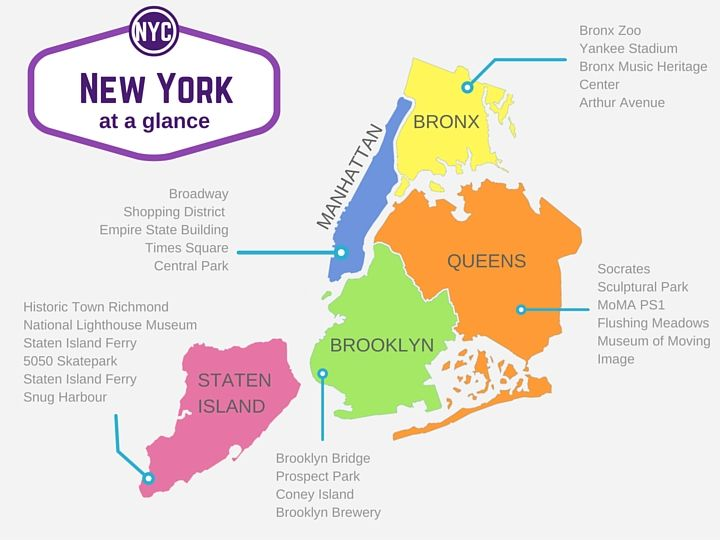

In [ ]:
# ---------------------------- PLOT FOR GEOGRAPHICAL DISTRIBUTION AS PER NEIGHBOURHOOD GROUPS FOR  AFFORDABLE LISTINGS ---------------------------------

# Call the function to display neighbourhood group distribution for affordable segment.
plot_geographical_distribution_neighbourhood_groups(
    affordable_airbnb_df,
    'Affordable Listings: Distribution by Neighbourhood Group and Location'
)


***Chart 1 : Affordable Listings – Distribution by Neighbourhood Group***

1.   **Why did you pick the specific chart?**
      *  A scatter plot of latitude/longitude points, color-coded by neighborhood group, provides a spatial overview of where affordable listings cluster, helping identify high-demand zones and underserved areas.
2.   **What is/are the insight(s) found from the chart?**

    **Key Insights and Trends :**
      *   **Centralized Clustering :**
             Most affordable listings are densely packed in central neighborhood groups (e.g., Manhattan, Brooklyn), with much sparser presence in outer groups (e.g., Staten Island).
      *   **Tourist and Transit Proximity :**  Affordable listings cluster near transit lines and tourist attractions, indicating hosts are targeting travelers seeking both convenience and value.

3.   **Will the gained insights help create a positive business impact?**
      *   **Yes.**
            *  Airbnb can identify under-served neighborhood groups and incentivize affordable listings there, balancing supply and improving guest options.
            *  Marketing can highlight affordable options in less saturated areas to attract more diverse travelers.
4.    **Are there any insights that lead to negative growth? Justify with specific reason.**
      *   **Yes.**
            *   Overconcentration in central areas can lead to oversupply, price competition, and local regulatory scrutiny, potentially harming host profitability and platform reputation.
            

          

In [ ]:
# ---------------------------- PLOT FOR GEOGRAPHICAL DISTRIBUTION AS PER NEIGHBOURHOOD GROUPS FOR  LUXURY LISTINGS ---------------------------------

# Call the function to display neighbourhood group distribution for luxury segment.
plot_geographical_distribution_neighbourhood_groups(
    luxury_airbnb_df,
    'Luxury Listings: Distribution by Neighbourhood Group and Location'
)

***Chart 2 : Luxury Listings – Distribution by Neighbour hood Group***

1.   **Why did you pick the specific chart?**
      *  This chart highlights where luxury inventory is focused, showing which neighborhood groups attract premium listings.
2.   **What is/are the insight(s) found from the chart?**
      *   **Selective, High-Value Clusters :**
             Luxury listings are highly concentrated in  wealthy area, central, or scenic neighborhood groups (e.g., central Manhattan, waterfronts).
      *   **Limited Outer Spread :**  Very few luxury listings are found in outer or less prestigious neighborhood groups.

3.   **Will the gained insights help create a positive business impact?**
      *   **Yes.**
            *  Airbnb can form strategic partnerships with luxury property managers in these high-value zones.
            *  The platform can market these neighborhoods as premium destinations to attract high-spending guests.
4.    **Are there any insights that lead to negative growth? Justify with specific reason.**
      *   **Yes.**
            *   Dependence on a few neighborhoods for luxury supply increases vulnerability to local market shifts or regulations.
            

          

In [ ]:
# ------------------------- FUNCTION TO PLOT GEOGRAPHICAL DISTRIBUTION AS PER ROOM TYPE ---------------------------

def plot_geographical_distribution_roomtype(df, title):
  """
  This function visualizes the geographical distribution of Airbnb Listings based on
  Room Type categories.

  Parameters :
  1. df (DataFrame) : Filtered Airbnb DataFrame (i.e affordable_airbnb_df or luxury_airbnb_df).
  2. title (str) : Title to be displayed on the scatter plot for respective segments.
  """

  # Step 1 : Set the figure size of the plot.
  plt.figure(figsize=(12,6)) # width = 12 inches and height = 8 inches.

  # Step 2 : Set the theme style to dark grid for improve redability.
  sns.set_style('darkgrid')

  # Step 3 : Create a Scatter plot to display the room types spatially.
  ax = sns.scatterplot(
      x = 'longitude', # Plot longitude values on the x-axis.
      y = 'latitude', # Plot latitude values on the y-axis.
      hue = 'room_type', # Use different colors for each room type.
      hue_order=['Entire home/apt', 'Private room', 'Shared room'], # Arrange the hue values in proper order.
      data = df, # DataFrame to use for plotting (affordable/ luxury)
      palette = 'icefire', # Color palette for differentiation.
      edgecolor = 'black', # Add black color border around the points.
      alpha = 0.8 # Control point transparency for overlap clarity.
  )


  # Step 4 : Set the title of the scatter plot with bold fint and increased size.
  plt.title(title, fontweight='bold', fontsize=15)

  # Step 5 : Set the axis labels for geographical orientation.
  plt.xlabel('Longitude') # Set the label for X-axis.
  plt.ylabel('Latitude') # Set the label for Y-axis.

  # Step 6 : Add and format the legend to explain colors by room type.
  ax.legend().set_title('Room Types')

  # Step 7 : Adjust the layout to prevent overlap and improve spacing.
  plt.tight_layout()

  # Step 8 : Display the scatter plot .
  plt.show()



In [ ]:
# -------------------- PLOT FOR GEOGRAPHICAL DISTRIBUTION AS PER ROOM TYPE FOR AFFORDABLE AIRBNB LISTINGS -------------------------

# Call the function to visualize room type distribution in the affordable segment.
plot_geographical_distribution_roomtype(
    affordable_airbnb_df,
    'Geographical Distribution of Room Types in Affordable Airbnb Listings'
)


***Chart 3 : Affordable Listings – Distribution by Room Type***

1.   **Why did you pick the specific chart?**
      *  This scatter plot shows how different room types are geographically distributed, revealing whether certain areas cater more to entire homes, private rooms, or shared rooms for affordable listings.
2.   **What is/are the insight(s) found from the chart?**
      *   **Entire Homes in Tourist Hubs :**
             Entire home/apt listings dominate central, high-traffic areas.
      *   **Private/Shared Rooms in Residential Zones :**
        These are more common in outer or residential neighborhoods, catering to budget travelers or longer stays.

3.   **Will the gained insights help create a positive business impact?**
      *   **Yes.**
            *  Airbnb can tailor marketing to promote private/shared rooms to students or remote workers in residential areas.
            *  Hosts can be guided to list more entire homes in high-demand locations for better returns.
4.    **Are there any insights that lead to negative growth? Justify with specific reason.**
      *   **Yes.**
            *   Oversupply of shared rooms in certain neighborhoods may limit revenue potential and dilute guest experience.
            

          

In [ ]:

# -------------------- PLOT FOR GEOGRAPHICAL DISTRIBUTION AS PER ROOM TYPE FOR LUXURY AIRBNB LISTINGS -------------------------

# Call the function to visualize room type distribution in the luxury segment.
plot_geographical_distribution_roomtype(
    luxury_airbnb_df,
    'Geographical Distribution of Room Types in Luxury Airbnb Listings'
)

***Chart 4 : Luxury Listings – Distribution by Room Type***

1.   **Why did you pick the specific chart?**
      *  This scatter plot shows how different room types are geographically distributed, reveals the room type mix for luxury listings and their spatial distribution.
2.   **What is/are the insight(s) found from the chart?**
      *   **Dominance of Entire Homes :**
             Nearly all luxury listings are entire homes/apartments, reinforcing exclusivity.
      *   **Rare Private/Shared Rooms :**
        These are almost absent in luxury zones, underlining the segment’s premium positioning.

3.   **Will the gained insights help create a positive business impact?**
      *   **Yes.**
            *  Airbnb can maintain strict quality standards for luxury entire homes to ensure guest satisfaction.
            *  The platform can confidently market luxury stays as exclusive, private experiences.
4.    **Are there any insights that lead to negative growth? Justify with specific reason.**
      *   **Yes.**
            *   Lack of diverse room types in luxury neighborhoods may exclude some traveler segments and reduce occupancy during off-peak periods.
            

          

In [ ]:
# -------------------------- FUNCTION TO PLOT GEOGRAPHICAL DISTRIBUTION AS PER NEIGHBOURHOOD ---------------------------

def plot_geographical_distribution_neighbourhood(df, title):
    """
    This function visualizes the geographical distribution of Airbnb Listings based on
    Neighbourhooods.

    Parameters :
    1. df (DataFrame) : Filtered Airbnb DataFrame (i.e affordable_airbnb_df or luxury_airbnb_df).
    2. title (str) : Title to be displayed on the scatter plot for respective segments.
    """

    # Step 1 : Set the figure size for better visibility.
    plt.figure(figsize=(12, 8)) # Width = 12 inches and Height = 8 inches

    # Step 2 : Set the plot's visual theme style to dark grid.
    sns.set_style('darkgrid')

    # Setp 3 : Create a Scatter plot using seaborn library:
    ax = sns.scatterplot(
        x = 'longitude', # Plot longitude values on the x-axis.
        y = 'latitude', # Plot latitude values on the y-axis.
        hue = 'neighbourhood', # Use color to differentiate neighbourhoods.
        data = df, # DataFrame to use for plotting
        palette = 'icefire', # Use 'icefire' color palette for differentiation.
        alpha = 0.8, # Set the transparency to 80% for better layering.
        edgecolor = None, # No border around the scatter points.
        legend = 'full' # Show a complete legend with all neighbourhood names.
    )

    # Step 4 : Set the title of the scatter plot.
    plt.title(title, fontweight='bold', fontsize=15)

    # Step 5 : Set the axis labels:
    plt.xlabel('Longitude') # Set the label for X-axis.
    plt.ylabel('Latitude') # Set the label for X-axis.

    # Step 6 : Customize the legend placement for the better visibility.
    legend = ax.legend(
        bbox_to_anchor = (0.5, -0.2), # Position it below the plot center.
        loc = 'upper center', # Align it to the upper center of bounding box.
        ncol = 6, # Spread legend items across 6 columns.
        fontsize = 'small', # Reduce legend text size.
        frameon = False # Remove the box frame around the legend.
    )

    # Step 7 : Adjust the layout spacing automatically.
    plt.tight_layout()

    # Step 8 : Display the final scatter plot.
    plt.show()




In [ ]:
# -------------------- PLOT FOR GEOGRAPHICAL DISTRIBUTION AS PER NEIGHBOURHOOD FOR AFFORDABLE AIRBNB LISTINGS -------------------------

# Call the function to visualize neighbourhood distribution in affordable listings.
plot_geographical_distribution_neighbourhood(
    affordable_airbnb_df,
    'Geographical Distribution of Neighbourhoods in Affordable Airbnb Listings'
)


***Chart 5 : Affordable Listings –Geographical Distribution by Neighbourhood.***

1.   **Why did you pick the specific chart?**
      *  This neighborhood-level scatter plot provides a granular view, identifying micro-clusters and gaps in affordable listings supply.
2.   **What is/are the insight(s) found from the chart?**
      *   **Micro-Clusters in Popular Areas :**
          High density in neighborhoods like Williamsburg, Harlem, and the Lower East Side.
      *   **Supply Gaps :**
        Some residential or industrial neighborhoods have few or no affordable listings.

3.   **Will the gained insights help create a positive business impact?**
      *   **Yes.**
            *  Airbnb can run hyperlocal campaigns to attract hosts in underrepresented neighborhoods, increasing platform coverage and guest options.
4.    **Are there any insights that lead to negative growth? Justify with specific reason.**
      *   **Yes.**
            *   Overconcentration in certain neighborhoods may lead to negative community sentiment or stricter local regulations.
            

          

In [ ]:
# -------------------- PLOT FOR GEOGRAPHICAL DISTRIBUTION AS PER NEIGHBOURHOOD FOR LUXURY AIRBNB LISTINGS -------------------------

# Call the function to visualize neighbourhood distribution in luxury listings.
plot_geographical_distribution_neighbourhood(
    luxury_airbnb_df,
    'Geographical Distribution of Neighbourhoods in Luxury Airbnb Listings'
)

***Chart 6 : Luxury Listings – Geographical Distribution by Neighbourhood.***

1.   **Why did you pick the specific chart?**
      *  This chart shows the most exclusive, high-value neighborhoods for luxury listings with the help of locations using scatter plot.
2.   **What is/are the insight(s) found from the chart?**
      *   **Ultra-Selective Clusters :**
          Luxury listings are concentrated in neighborhoods like Tribeca, Soho, and Central Park-adjacent areas.
      *   **Absence in Many Areas :**
        Many neighborhoods have no luxury listings at all.

3.   **Will the gained insights help create a positive business impact?**
      *   **Yes.**
            *  Airbnb can curate premium experiences and partnerships in these neighborhoods, enhancing the luxury brand.
            *  The platform can identify new neighborhoods with potential for luxury expansion.
4.    **Are there any insights that lead to negative growth? Justify with specific reason.**
      *   **Yes.**
            *   High exclusivity may create barriers for new luxury hosts and limit guest choice.

          

***Conclusion & Combined Business insights :***

Analysis of Airbnb’s geographic distribution reveals distinct patterns and opportunities for both affordable and luxury segments:


  *   **Affordable listings** are densely clustered in central, transit-accessible, and tourist-heavy neighborhoods, but show notable gaps in outer and residential zones. This reflects hosts’ focus on demand hotspots but also highlights untapped potential in less saturated areas.
  *   **Luxury listings** are even more tightly concentrated in wealthy area, scenic, and iconic neighborhoods, almost exclusively as entire homes/apartments. This strategy reinforces Airbnb’s premium positioning but increases risk from over-reliance on a limited set of locations and guest profiles.

**Research confirms these findings :**
Studies across global cities show that Airbnb supply is most dense in city centers and near attractions, with neighborhood environment (e.g., access to transport, universities, nightlife, and amenities) strongly influencing listing patterns(chart 1, chart 2, chart 5 and chart 6).
The spatial distribution is also heterogeneous—different factors matter in different regions, so strategies should be tailored at the neighborhood level.




**Combined Business Insights :**

*   **Expansion and Diversification :**
Airbnb should incentivize affordable listings in less saturated neighborhoods to balance supply, reach new guest segments, and reduce regulatory risk.
*   **Premium Positioning and Resilience :**
For luxury, deepen partnerships and curated experiences in high-value zones, but also explore select expansion to emerging premium areas to reduce concentration risk.
*   **Neighborhood-Level Strategy :**
Use granular data to tailor marketing, host recruitment, and pricing strategies for each segment and neighborhood.
*   **Risk Management :**
Monitor listing density in central areas to avoid oversupply, price competition, and regulatory scrutiny, and maintain high quality and exclusivity standards in luxury hotspots.



***Summary Table : Geographic Distribution and Business Implications.***

| Aspect | Affordable Segment | Luxury Segment |
    |---|---|---|
    | Clustering Pattern | Dense in central/tourist/transit areas; sparse in periphery | Highly concentrated in affluent, scenic, exclusive neighborhoods |
    | Room Type Mix | Diverse (entire, private, shared rooms) | Predominantly entire homes/apartments |
    | Market Opportunities | Expand in under-served neighborhoods; attract new guest segments | Deepen partnerships in prime areas; explore new luxury zones |
    | Key Business Risks | Oversupply, price competition, regulatory scrutiny in hotspots | Over-reliance on limited locations; lack of room type diversity |
    | Strategic Actions | Incentivize hosts in periphery; tailor marketing by neighborhood | Maintain exclusivity/quality; cautiously diversify offerings |
    | Guest Experience | Broad accessibility, variety of options | Premium, exclusive experiences |
    | Regulatory Focus | Manage density to avoid community pushback | Monitor concentration to mitigate regulatory risks |
   

----


# ***Bivariate questions:***

----
***(B01) Question 11 : Is there a connection between room type and the average availability throughout the year (availability_365) for affordable and luxury Airbnb listings?***

----


In [ ]:
# Let's do the calculation for Average Availability of Listings as per Room Type :

# ---------------------------------- FUNCTION 1 : COUNT ZERO AVAILABILITY LISTINGS ----------------------------------

def count_zero_availability(df, segment_name):
    """
    This function counts and prints the number of listings with zero availability in the given dataset.

    Parameters:
    1. df (DataFrame)        : Filtered Airbnb DataFrame (affordable or luxury).
    2. segment_name (str)    : Name of the segment for labeling the result (i.e 'Affordable', 'Luxury').

    Returns:
    - Integer count of zero availability listings.
    """

    # Step 1 : Count the number of listings where availability_365 is equal to 0.
    zero_availability_count = (df['availability_365'] == 0).sum()

    # Step 2 : Print the result in a clear format for the user to understand.
    print(f"🔍 Number of listings with ZERO availability ({segment_name}): {zero_availability_count}")

    return zero_availability_count

In [ ]:
# Check Total Zero Availability of Listings thoughout the Year for Affordable Segments:
zero_check_affordable_availability = count_zero_availability(affordable_airbnb_df, 'Affordable')

In [ ]:
# Check Total Zero Availability of Listings thoughout the Year for Luxury Segments:
zero_check_luxury_availability = count_zero_availability(luxury_airbnb_df, 'Luxury')

In [ ]:
# ---------------------------- FUNCTION 2 : ANALYZE & PLOT AVAILABILITY BY ROOM TYPE ----------------------------

def analyze_availability_by_room_type(df, segment_name, color_palette):
    """
    This function excludes zero availability listings, calculates the average and standard deviation
    of availability grouped by room type, and visualizes the results using a barplot.

    Parameters:
    1. df (DataFrame)         : Filtered Airbnb DataFrame (affordable or luxury).
    2. segment_name (str)     : Segment name to include in the plot title (i.e. 'Affordable' or 'Luxury').
    3. color_palette (str)    : A seaborn-supported color palette name.

    Returns:
    - A barplot showing average availability and variability (std) by room type.
    - A DataFrame with calculated mean and std of availability.
    """

    # ---------------- STEP 1: FILTER OUT ZERO AVAILABILITY ----------------

    # Remove listings with 0 availability to focus only on bookable listings.
    available_listings = df[df['availability_365'] != 0]


    # ---------------- STEP 2: GROUP BY ROOM TYPE AND CALCULATE METRICS ----------------

    # Calculate mean and standard deviation of availability for each room type.
    availability_stats = available_listings.groupby('room_type')['availability_365'].agg(['mean', 'std']).reset_index()

    # Rename columns for clarity.
    availability_stats.columns = ['room_type', 'avg_availability', 'std_availability']

    # Display the dataframe to observe the result:
    #display(availability_stats)


    # ---------------- STEP 3: CREATE THE BARPLOT ----------------

    # Set the figure size for the plot.
    plt.figure(figsize=(10, 6))

    # Create the main barplot using seaborn
    ax = sns.barplot(
        x='room_type', # Plots values of  Room types on x-axis
        y='avg_availability', # Average availability on y-axis
        data=availability_stats,  # Data source for plotting.
        palette=color_palette # Custom color palette for the bars
    )


    # ---------------- STEP 4: ADD ERROR BARS FOR STANDARD DEVIATION ----------------

    # Get numerical positions for each room type for plotting error bars
    x_positions = range(len(availability_stats))

    # Add error bars to show standard deviation for each room type
    ax.errorbar(
        x=x_positions,   # X-axis positions for each bar representing different room types.
        y=availability_stats['avg_availability'],  # Y-axis values (average availability) where error bars will be centered.
        yerr=availability_stats['std_availability'],  # Length of the error bars based on standard deviation (variability in availability).
        fmt='none',  # No markers on error bar points
        color='black',  # Set error bar color
        capsize=10, # Add caps to error bars for readability
        alpha=0.4 # Set transparency of error bars
    )


    # ---------------- STEP 5: ADD LABELS, TITLES, AND VALUES ON BARS ----------------

    # Set the main title of the chart
    plt.title(f'Average Yearly Availability by Room Type ({segment_name} Listings)', fontweight='bold', fontsize=16)

    # Label the axes
    plt.xlabel('Room Type', fontsize=12)
    plt.ylabel('Average Availability (Days)', fontsize=12)

    # Ensure that everything fits well within the plot area
    plt.tight_layout()

    # Annotate average availability values above the bars
    for i, value in enumerate(availability_stats['avg_availability']):
        ax.text(i, value + 10, f'{value:.1f}', ha='right', fontweight='bold', fontsize=10, rotation=90)


    # ---------------- STEP 6: DISPLAY THE FINAL PLOT ----------------
    plt.show()

    # Return the summary stats dataframe in case it's needed later
    return availability_stats


In [ ]:
# ---------------------- AFFORDABLE SEGMENT ANALYSIS ----------------------

# Count zero availability listings
count_zero_availability(affordable_airbnb_df, segment_name='Affordable')

# Visualize average availability by room type
analyze_availability_by_room_type(
    affordable_airbnb_df,
    'Affordable',
    'viridis'  # Use a blue theme for affordable segment
)


***Affordable Segment Chart : Average Yearly Availability by Room Type (Affordable Listings)***

1.   Why did you pick the specific chart?
      *  **Bar chart with error bars** is ideal for comparing average availability across room types and visualizing variability (standard deviation).
      *  It provides a clear, direct comparison for business stakeholders to identify which room types are under- or over-utilized in the affordable segment.
2.   What is/are the insight(s) found from the chart?
      *   **Shared rooms** have the highest average availability (217.7 days), indicating they are available for booking most of the year.
      *   **Private rooms** (176.0 days) and entire homes/apts (166.2 days) have lower average availability, suggesting higher demand or more frequent bookings.
      *   **High standard deviation** across all types points to significant variability in how often listings are available.
      *   **Key insight :** Shared rooms in the affordable segment are available for a much larger portion of the year, suggesting lower demand or oversupply compared to other room types.


3.   Will the gained insights help create a positive business impact?
      *   **Yes.**This insight helps Airbnb and hosts:
            *  Identify underutilized inventory (shared rooms).
            *  Adjust marketing strategies to boost occupancy for shared rooms (e.g., promotions, targeting budget travelers).
            *  Encourage hosts to consider converting underperforming shared rooms to private rooms or entire homes, if feasible.
            *  Implement dynamic pricing to increase bookings for high-availability room types.
4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes.**
            *   **Potential negative growth :** The high availability of shared rooms likely means low demand, leading to reduced revenue and possible host dissatisfaction.
                *   If this trend continues, hosts may leave the platform or convert their properties to other uses, reducing affordable inventory.
                *   Oversupply without demand can trigger price wars, lowering overall profitability in the affordable segment.


          

In [ ]:
# ---------------------- LUXURY SEGMENT ANALYSIS ----------------------

# Count zero availability listings
count_zero_availability(luxury_airbnb_df, segment_name='Luxury')

# Visualize average availability by room type
luxury_stats = analyze_availability_by_room_type(
    luxury_airbnb_df,
    segment_name='Luxury',
    color_palette='plasma'  # Use an plasma theme for luxury segment
)


***Luxury Segment Chart : Average Yearly Availability by Room Type (Luxury Listings)***

1.   Why did you pick the specific chart?
      *  **Bar chart with error bars** is again appropriate for comparing luxury room types, showing both mean and spread of availability.
      *  The use of a distinct color palette helps differentiate luxury from affordable, making the insights segment-specific.
2.   What is/are the insight(s) found from the chart?
      *   **Private rooms** in the luxury segment have the highest average availability (approx 251 days), followed by entire homes/apts (approx 210 days), and shared rooms (~169 days).
      *   The standard deviations remain high, indicating variability in booking patterns.
      *   **Key insight :** Luxury private rooms are under-booked compared to other luxury room types, which is the opposite of the affordable segment.


3.   Will the gained insights help create a positive business impact?
      *   **Yes.** These insights allow Airbnb and hosts to :
            *  Rethink the luxury private room offering—perhaps luxury travelers prefer entire homes/apts for privacy, and private rooms are less attractive at a premium price point.
            *  Encourage luxury hosts to enhance private room offerings (add amenities, improve marketing, or reposition as boutique experiences).
            *  Consider reducing the number of luxury private room listings if demand does not improve, focusing instead on entire homes/apts.
4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes.**
            *   **Potential negative growth :** High availability for luxury private rooms signals weak demand, risking revenue stagnation or decline in that segment.
                *   If luxury private rooms remain unbooked, hosts may leave or downgrade their offerings, shrinking the luxury inventory and reducing platform appeal for high-end travelers.
                *   Misalignment between supply and guest preferences can damage Airbnb’s reputation in the luxury market.


          

**Business insights & Recommendation :**

1.   **Demand-Supply Mismatch**
  *   **Affordable shared rooms** are under-booked, likely due to oversupply or low guest interest. This could be a sign to reduce inventory or reposition these listings.
  *   **Luxury private rooms** are also underutilized, possibly because luxury travelers prefer more privacy or entire homes.


2.   **Pricing & Marketing Strategies**
  *   **Dynamic pricing :** Lower prices or offer discounts for high-availability categories (affordable shared rooms, luxury private rooms) to boost occupancy.
  *   **Targeted promotions :** Market affordable shared rooms to budget travelers, students, or long-term guests. For luxury private rooms, consider targeting business travelers or offering premium amenities to justify the price.

3.   **Host Guidance**
  *   **Conversion opportunities :** Encourage hosts with underperforming shared rooms (in affordable segment) or private rooms (in luxury segment) to consider converting their spaces to more in-demand types, if feasible.
  *   **Quality improvement :** Invest in improving the quality and appeal of high-availability listings to increase their attractiveness.

4.   **Inventory Management**
  *   **Monitor and adjust supply :** If certain room types consistently show high availability and low bookings, consider limiting new listings in those categories or providing incentives for hosts to switch to higher-demand types.

5.   **Risk of Negative Growth**
  *   **Oversupply in affordable shared rooms and luxury private rooms** can lead to price wars, reduced host satisfaction, and potential churn if not addressed.
  *   **High variability** suggests some listings are either permanently available (possibly unpopular) or only seasonally booked. This can impact revenue predictability for both hosts and Airbnb.


| Segment | Room Type | Avg. Availability (Days) | Std. Deviation (Days) | Demand Insight | Business Recommendation |
|---|---|---|---|---|---|
| Affordable | Entire home/apt | 166.2 | High | Lower availability, steady demand | Maintain pricing, encourage more supply |
| Affordable | Private room | 176.0 | High | Moderate availability, moderate demand | Optimize pricing, promote to solo/budget travelers |
| Affordable | Shared room | 217.7 | High | Highest availability, likely oversupply | Reposition, improve amenities, or reduce inventory |
| Luxury | Entire home/apt | 210.3 | High | High availability, but still in demand | Target premium guests, highlight unique features |
| Luxury | Private room | 251.3 | High | Highest availability, weakest demand | Enhance offering, target business/long-term travelers |
| Luxury | Shared room | 169.0 | High | Lowest availability, possible niche demand | Explore reasons for demand, maintain exclusivity |

-------------

----
**(B02) Question 12 : How does the distribution of reviews per month vary across different neighborhood groups in the affordable and luxury segments?**

----

In [ ]:
# Let's visualize the distribution of reviews per month across different neighbourhood groups for the affordable and luxury segments :

def plot_reviews_by_neighbourhood(df, segment_name, palette_name):
    """
    Plots the distribution of reviews per month across neighbourhood groups for a given Airbnb segment.

    Parameters:
    1. df(DataFrame) : Filtered Airbnb DataFrame (i.e affordable_airbnb_df or luxury_airbnb_df).
    2. segment_name (str) : A Label for identifying the dataset segment in plot titles.
    3. palette_name (str) : Name of the seaborn color palette to use for the stripplot.
    """

    # Set the size of the plot figure
    plt.figure(figsize=(12, 6))  # Width = 12 inches and Height = 6 inches.


    # Create a stripplot to visualize the distribution of 'reviewa_per_month' across 'neighbourhood_group'.
    sns.stripplot(
        x = 'neighbourhood_group', # Neighbourhood groups on the X-axis.
        y = 'reviews_per_month', # Reviews per month on the Y-axis.
        data = df, # Data source for plotting.
        palette = palette_name, # Set the color palette for the stripplot as per user input.
        hue_order=['Entire home/apt', 'Private room', 'Shared room'], # Arranges the hue value in proper order.
        order=['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island'], # Arranges the neighbourhood groups in proper order.
        jitter = 0.3, # Adds horizontal jitter (spread) to avoid overlapping.
        size = 4, # Size of the individual dots.
        alpha = 0.8, # Adjuts the transparency for better visual clarity.
        edgecolor='black',              # Black border around each dot
        linewidth=0.3                   # Thickness of the border
    )

    # Set the title of the plot dynamically using the segment name :
    plt.title(f'{segment_name} Segment: Reviews Per Month by Neighbourhood Group',
              fontsize=14, fontweight='bold')

    # Label for X-axis:
    plt.xlabel('Neighbourhood Group', fontsize=12)

    # Label for Y-axis:
    plt.ylabel('Reviews Per Month', fontsize=12)

    # Remove the top and right border (spines) for a cleaner look:
    plt.tight_layout()

    # Show the final plot:
    plt.show()




In [ ]:
# ---------------------- AFFORDABLE SEGMENT ANALYSIS -----------------------------------------------
plot_reviews_by_neighbourhood(affordable_airbnb_df, 'Affordable', 'viridis') # palette = rocket_r.

***Affordable Segment Chart :  Reviews Per Month by Neighbourhood Group***

1.   Why did you pick the specific chart?
      *  The **strip plot** is ideal for visualizing the distribution and density of reviews per month across categorical variables (neighbourhood groups). It allows for easy identification of both the range and concentration of review activity, as well as outliers, within each neighbourhood groups.
2.   What is/are the insight(s) found from the chart?
      *   **Manhattan and Queens** have the highest density and spread of reviews per month, with Manhattan showing extreme outliers (up to nearly 60 reviews/month), indicating some highly popular affordable listings.
      *   **Brooklyn** maintains a healthy middle ground with a wide, steady spread of review counts.
      *   **Bronx and Staten Island** consistently lag behind, with most listings receiving fewer than 10 reviews per month and a visibly lower density of active listings.
      *   The distribution in all neighbourhood group is right-skewed, with most listings clustered at lower review counts and a few high-performing outliers.


3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *  These insights highlight where affordable listings are most successful (Manhattan, Queens, Brooklyn), guiding Airbnb to focus marketing and host support in these neighborhoods.
            *  Identifying underperforming areas (Bronx, Staten Island) can help target improvement efforts or tailored promotions to boost guest engagement and host activity.
            *  Understanding borough-specific demand allows for more effective resource allocation and dynamic pricing strategies.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes.**
            *   The consistently low review activity in the Bronx and Staten Island suggests weak guest demand, which may discourage hosts and reduce inventory in these areas.
            *   Over-reliance on a few high-performing listings (outliers) in Manhattan and Queens could make the affordable segment vulnerable if those listings leave the platform or face regulatory issues.
            *   If the supply in low-demand areas is not adjusted or improved, it could result in wasted resources and host dissatisfaction.


          

In [ ]:
# ---------------------- LUXURY SEGMENT ANALYSIS --------------------------------
plot_reviews_by_neighbourhood(luxury_airbnb_df, 'Luxury', 'plasma') # Use palette 'plasma' .

***Luxury Segment Chart : Reviews Per Month by Neighbourhood Group***

1.   Why did you pick the specific chart?
      *  The **strip plot** is well-suited for visualizing the sparse and varied nature of luxury listings’ review activity across neighborhoods, making it easy to compare the spread and concentration of reviews in each borough.
2.   What is/are the insight(s) found from the chart?
      *   **Manhattan** is the clear epicenter of luxury activity, with the highest number and spread of reviews per month, though the maximum is much lower than in the affordable segment (peaking around 14 reviews/month).
      *   **Brooklyn** shows moderate luxury activity, with most listings getting 1–6 reviews per month.

      *   **Queens, Bronx, and Staten Island** have very few luxury listings and extremely low review activity, indicating minimal demand or supply in these segments.
      *   The overall review frequency for luxury listings is significantly lower than for affordable listings, suggesting longer stays or lower booking turnover.


3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *  These findings can guide Airbnb to focus luxury marketing and host recruitment in Manhattan and Brooklyn, where the demand is proven.
            *  The data suggests opportunities for cautious expansion of luxury offerings in underrepresented but potentially high-value neighborhoods.
            *  Understanding the lower review turnover in luxury can inform expectations for hosts and platform revenue planning.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes.**
            *   Heavy concentration of luxury activity in Manhattan creates risk if local regulations change or market conditions shift.
            *   The lack of luxury demand in outer boroughs suggests that expanding supply there without clear demand could lead to unbooked inventory and host churn.
            *   Lower review frequency in luxury could indicate longer booking cycles, but also means less frequent guest feedback, which may slow improvement and responsiveness to market trends.


          

**Conclusion :**


*  There is a strong geographic concentration of both affordable and luxury Airbnb demand in Manhattan, with Queens and Brooklyn also showing potential, especially in the affordable segment.
*   Bronx and Staten Island are underperforming across both segments, suggesting either low demand, fewer attractions, or less appealing inventory.
*   The affordable segment has heigher review speed and more outlier , while the luxury segment is more execlusive and less frequently booked.



***Recommendation :***

1.   **Focus Marketing and Investment on High-Performing Areas :**
    *   Prioritize Manhattan, Queens, and Brooklyn for promotional efforts, host support, and platform investment, as these areas show the strongest guest engagement and listing performance.
    

2.   **Address Underperformance in Bronx and Staten Island :**
    *   Investigate barriers to demand in these neighbourhood groups (e.g., accessibility, amenities, safety, local attractions).
    *   Consider targeted incentives or quality improvement programs for hosts in these areas to boost guest interest and satisfaction.

3.   **Segment-Specific Strategies :**
    *   **Affordable Segment :**
        *   Leverage the high review speed in Manhattan and Queens to attract new hosts and guests.
        *   Use dynamic pricing and targeted promotions to maximize occupancy for outlier listings.
    *   **Luxury Segment :**
        *   Expand luxury offerings cautiously in Brooklyn and Queens, focusing on unique experiences or premium amenities.
        *   Maintain exclusivity and high service standards in Manhattan, but explore ways to increase guest turnover or diversify the luxury inventory.

4.   **Monitor for Market Saturation and Negative Growth :**
    *   Watch for signs of oversupply or excessive competition in Manhattan, which could lead to price wars or declining host satisfaction.
    *   Avoid expanding supply in low-demand areas without clear evidence of increasing guest interest.

5.   **Encourage Quality and Experience Improvements :**
    *   Support hosts in all segments to enhance property appeal, guest experience, and review quality, which are key drivers of booking intention and repeat business.

| Segment | Neighborhood Group| Review Activity (Reviews/Month) | Key Insight | Business Action |
|---|---|---|---|---|
|Affordable | Manhattan | Highest, with extreme outliers | Strongest demand, some listings very popular | Focus marketing, attract new hosts, dynamic pricing |
| Affordable | Queens | High, wide spread | High guest engagement, good growth potential | Invest in host support, targeted promotions |
| Affordable | Brooklyn | Moderate, steady | Healthy market, opportunity for growth | Maintain support, optimize pricing |
| Affordable | Bronx | 	Low | Weak demand, few active listings | Investigate barriers, consider incentives |
| Affordable | Staten Island | Very low | Minimal activity, underperforming | Quality improvement, targeted support |
| Luxury | Manhattan | Highest, but lower than affordable | Epicenter of luxury demand, but less frequent | Maintain exclusivity, explore guest turnover |
| Luxury | Brooklyn | 	Moderate | Some demand, room for expansion | Cautious expansion, unique experiences |
| Luxury | Queens | Low | 	Limited luxury market | Explore niche opportunities |
| Luxury | Bronx | 	Very low | 	Negligible demand | Avoid expansion, monitor for changes |
| Luxury | Staten Island | 	Very low | Negligible demand | Avoid expansion, monitor for changes |

-------------------------------------------------------------------

-----

***(B03) Question 13 : How does the host's listing count influence the average listing price in the affordable and luxury Airbnb segments?***

----

In [ ]:
# Let's calculate and visualize the relationship between the host's Listings count and the average Listings price for both affordable and luxury Airbnb segments :

# Create a custome function to visualize the impact of host's listings count on avg price using a barplot :
def plot_host_listings_vs_avg_price(df, segment_name):
    """
    Plots the relationship between the host's Listings count and the average Listings price
    for either affordable or luxury Airbnb segments using a barplot.

    Parameters :
    1. df (DataFrame) : Filtered Airbnb DataFrame. (i.e affordable_airbnb_df or luxury_airbnb_df).
    2. segment_name (str) : Discriptive labels of the dataframe segment (i.e 'Affordable' or 'Luxury')
    """

    # Determine the correct price column based on the segment ( affordable or luxury):
    price_column = 'affordable_price' if segment_name == 'Affordable' else 'luxury_price'  # using list comprehension for price_column allotment as per segment_name inpuyt from user.

    # Group the dataset by host listing count and calculate the mean price for each group:
    avg_price_by_host_listings = df.groupby('host_listings_count')[price_column].mean().reset_index()
    display(avg_price_by_host_listings)
    # Set the figure size for better visibility:
    plt.figure(figsize=(15, 8))

    # Apply the dark grid background style to the plot:
    sns.set_style('darkgrid')

    # Create a barplot using Seaborn as library:
    ax = sns.barplot(
        x = 'host_listings_count', # Plots value from 'host_listings_count' column on x-axis.
        y = price_column, # Plots form price_column on y-axis.
        data = avg_price_by_host_listings, # Selects dataframe for data source.
        palette = 'viridis' if segment_name == 'Affordable' else 'plasma' # using list comprehension to assign the plate for respective segment.
    )

    # Set the plot title and axis labels:
    plt.title(
        f"{segment_name} Segment : Host's Listings Count vs Average Price",
        fontweight = 'bold', # Set the font style to bold.
        fontsize = 16, # Adjust the fontsize.
        loc = 'left' if 'Affordable' in segment_name else 'right' # Align title based on segment type
    )

    # Set the labels on the axes.
    plt.xlabel("Host Listings Count") # X-axis.
    plt.ylabel("Average Listing Price") # Y-axis.

    # Rotate the x-axis labels to prevent overlap
    plt.xticks(rotation=90)

    # Add a horizontal grid only for the y-axis to improve redability.
    plt.grid(True, axis='y')

    # Remove the top and right spines for cleaner look:
    sns.despine()

    # Add bar labels showing the average price on the top of each bar:
    for container in ax.containers:
        ax.bar_label(container, fmt = '${:.2f}', padding = 3, fontsize = 10, rotation = 90)

    # Display the plot :
    plt.show()


In [ ]:
# ---------------------------- Affordable Listings Visualization -----------------------------------------------------------#

# Barplot for ' Host's Listing count vs Average Price" for Affordable Segment:
plot_host_listings_vs_avg_price(affordable_airbnb_df, 'Affordable')

***Affordable Segment Chart : Host's Listings Count vs Average Price***

1.   Why did you pick the specific chart?
      *  **Bar plot** is ideal for comparing average prices across discrete, categorical variables (host listing counts).
      *  It visually highlights trends, fluctuations, and outliers in average price as the number of listings per host increases.
      *  The use of color gradients and value labels enhances interpretability for business stakeholders.
2.   What is/are the insight(s) found from the chart?
      *   **General trend :** For hosts with 1–10 listings, the average price tends to decrease, suggesting that hosts with a few listings may price more competitively.
      *   **High variability :** Beyond 10 listings, average prices fluctuate significantly, with some hosts commanding much higher prices (e.g., at 232 listings: $280.30, at 65 listings: $223.53).
      *   **Outliers :** Hosts with very high listing counts (e.g., 232, 327) achieve the highest average prices, likely due to owning premium or unique properties.
      *   **No linear pattern :** There is no consistent upward or downward trend; instead, the relationship is non-linear and influenced by outliers.

3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *  **Host Segmentation :** Airbnb can identify and support high-performing multi-property hosts who maintain premium pricing.
            *  **Revenue Strategy :** Insights can guide dynamic pricing, encouraging smaller hosts to optimize their prices and larger hosts to maintain quality.
            *  **Host Onboarding :** Targeting hosts with potential to scale (add more listings) could be beneficial, especially if they maintain quality and higher prices..

4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes.**
            *   **Volatility Risk :** The lack of a clear trend and presence of sharp price spikes for high listing counts indicate market volatility. If these outlier hosts leave the platform, average prices could drop sharply.
            *   **Price Wars :** For hosts with few listings, the trend toward lower prices may lead to price wars, reducing profitability.
            *   **Quality Concerns :** If hosts with many listings are not maintaining quality, it could impact guest satisfaction and reviews, ultimately harming the platform’s reputation.


          

In [ ]:
# ---------------------------- Luxury Listings Visualization -----------------------------------------------------------#

# Barplot for ' Host's Listing count vs Average Price" for Luxury Segment:
plot_host_listings_vs_avg_price(luxury_airbnb_df, 'Luxury')

***Luxury Segment Chart : Host's Listings Count vs Average Price***


1.   Why did you pick the specific chart?
      *  **Bar plot** is ideal for comparing average prices across discrete categories (host listing counts).
      *  It visually highlights trends, fluctuations, and outliers in average price as the number of listings per host increases.
      *  The use of a color gradient and value labels enhances interpretability, making it easy to spot spikes or anomalies—like the one at counts 5 and 6.
2.   What is/are the insight(s) found from the chart?
      *   **Spike at 5 and 6 listings:**
            *   At **5 listings**, the average luxury price is **$663.14**, which is high but not extreme.
            *   At **6 listings**, the average luxury price jumps to **1,094.94**, representing a significant spike compared to neighboring counts.
      *   **Extreme outliers :**
            *   Even more dramatic, at **11 and 12 listings**, the average price reaches **$1,530.48** and **$1,301.02** respectively.
      *   **General trend :**
            *   For hosts with 1–4 listings, average price decreases gradually.
            *   After the spike at 6 listings, average prices generally decrease or fluctuate, with additional spikes at certain higher counts (e.g., 30, 49).
      *   **Volatility :**
            *   The relationship between host listing count and average price is highly volatile, with no clear upward or downward trend.
      *   **Interpretation of the spike :**
            *   The spike at 6 listings suggests that a small number of hosts with exactly 6 luxury listings are able to command much higher prices—possibly due to owning a portfolio of ultra-premium or uniquely desirable properties.
            

3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *  **Host Segmentation :**
                 *  Airbnb can identify and support these high-performing multi-property luxury hosts, as they significantly impact the platform’s premium offering.
            *  **Marketing and partnerships :**
                 *  The presence of hosts with multiple high-value listings can be leveraged for marketing, partnerships, and platform credibility in the luxury market.
            *  **Revenue strategy :**
                 *  Insights can guide dynamic pricing and inventory management, ensuring that luxury hosts are encouraged to maintain quality and premium pricing.
            *  **Host development :**
                 *  Airbnb could develop targeted programs to help other luxury hosts scale their portfolios with a focus on quality, learning from the strategies of these high-performing hosts.


4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes.**
            *   **Market instability :**
                  *   The luxury segment’s reliance on a few hosts with multiple high-priced listings introduces risk. If these hosts leave the platform or lower their quality, the average price and perceived value of the luxury segment could drop sharply.
            *   **Accessibility :**
                  *   If luxury prices are set too high by multi-listing hosts, it may deter guests, leading to lower occupancy and potential negative reviews.
            *   **Quality dilution :**
                  *   If hosts with many listings cannot maintain consistent quality, it could damage Airbnb’s luxury brand reputation.


          

***Summary Table :***

| Segment | Host Listing Count | Avg. Price Trend/Pattern | Notable Spikes/Outliers | Key Insights & Implications | Potential Risks/Negative Impact |
    |---|---|---|---|---|---|
    | Affordable | 	1–10 | Gradual decrease in avg. price | None | Small-scale hosts tend to price more competitively; market is price sensitive in lower listing counts | Risk of price wars, reduced profitability |
    | Affordable | 11–25 | 	Fluctuations and moderate increases | Spikes at 11, 13, 20, 21, 23, 25 | Some multi-listing hosts achieve higher prices, possibly due to better property management or unique assets | Volatility, possible over-reliance on outliers |
    | Affordable | 26–50+ | High volatility, sharp increases at higher counts | Major spikes at 30, 33, 39, 49, 65, 87, 121, 232, 327 | High-volume hosts can command premium prices, likely due to specialized or premium listings | Market instability if these hosts exit |
    | Luxury | 1–4 | Gradual decrease in avg. price | None | Most luxury hosts with few listings price moderately; entry-level luxury | None |
    | Luxury | 5–6 | Significant spike in avg. price | Spike at 6 ($1,094.94) | Small group of hosts with 5–6 listings command much higher prices, likely ultra-premium portfolios | Over-reliance on few hosts, data skew |
    | Luxury | 7–10 | Drop after spike, moderate prices | None| More accessible luxury options, but less premium than spike group | None |
    | Luxury | 	11–12 | Extreme outlier, very high avg. price | Spikes at 11 ($1,530.48), 12 ($1,301.02) | Ultra-premium hosts have strong influence on average price in this segment | Market instability, accessibility issues |
    | Luxury | 13–50+ | Volatile, several additional spikes | Spikes at 30, 49 | Some high-volume hosts maintain premium pricing; portfolio diversification | Quality control, guest experience risk |

-----------------------

----
**(B04) Question 14 : Is there a relationship between the price of a listing and its minimum nights requirement in the affordable and luxury segments?**

----

In [ ]:
# -------------------------------------------------- SCATTER AND CONTOUR PLOTS FOR PRICE VS MINIMUM NIGHTS -------------------------------------------------- #

# Define a custom function to create scatter and contour plot for any given segment:
def plot_scatter_price_vs_minimum_nights(df, segment_name, price_col, scatter_color):
    """
    This function generates visualizations to explore the relationship between listing price and minimum nights required.

    Parameters :
    1. df (DataFrame) : Filtered Airbnb DataFrame. (i.e affordable_airbnb_df or luxury_airbnb_df)
    2. segment_name (str) : A string label used for the chart titles ('Affordable' or 'Luxury')
    3. price_col (str) : The name of the price column in the DataFrame ('affordable_price' or 'luxury_price')
    4. scatter_color (str) : Color used for scatter plot points.
    """

    # ---------------------------- SCATTER PLOT (INITIAL OVERVIEW) -----------------------------------------------------------#

    # Set the figure size:
    plt.figure(figsize=(10, 6)) # Width = 10 inches and Height = 6 inches.

    # Set theme style of the plot:
    sns.set_style('darkgrid')

    # # Create a Scatter plot for the full dataset:
    sns.scatterplot(x = 'minimum_nights', # Plots values of 'minimum_night' column on x-axis.
                    y = price_col, # Plots dynamic price column on y-axis.
                    data = df,  # DataFrame for data source.
                    color = scatter_color, # Custom color per segment.
                    alpha = 0.6, # Adjust the transparency for overlap clarity.
                    label='Listings'     # Label for legend
                    )

    # Draw a LOWESS-smoothed regression line to show the trend between minimum nights and price

    sns.regplot(
        x='minimum_nights',         # Plots values from minimum_night column on the x-axis.
        y=price_col,                # Plots value of price column form the selected dataframe column on the y-axis.
        data=df,                    # The DataFrame that contains your data (e.g., affordable_airbnb_df).
        scatter=False,              # Don't show the individual data points (dots), just draw the trend line.
        lowess=True,                # Use LOWESS smoothing to draw a curved line that follows the shape of the data.

        line_kws={                  # Style the line with the following settings:
            'color': 'black',       # Make the line black
            'lw': 1,                # Line width = 1 (thin line)
            'alpha': 0.7,            # Slightly transparent line (0 is invisible, 1 is fully solid)
            'label': 'LOWESS Trend' # Label for legend.
        }
    )


    # Set the title of the plot:
    plt.title(f'{segment_name} Listings : Price vs. Minimum Nights\n(Including All Outliers for Full Range)', fontweight='bold')

    # Set the title of the plot:
    plt.xlabel('Minimum Nights') # Set the x-axis label.
    plt.ylabel('Price') # Set the y-axis label.


    # Add a legend
    plt.legend()

    # Adjuts the layout for better redability:
    plt.tight_layout()

    # Display the plot:
    plt.show()



In [ ]:
# -------------------------------------------------- CONTOUR PLOT FUNCTION -------------------------------------------------- #

# Let's define a function to create two contour (KDE) plots for full range and zoomed-in filtered views.
def plot_contour_price_vs_min_nights(df, segment_name, price_col, kde_cmap):
    """
    Create side-by-side contour KDE plots for price vs. minimum nights.

    Parameters :

    1. df (DataFrame) : Filtered Airbnb DataFrame. (i.e affordable_airbnb_df or luxury_airbnb_df).
    2. segment_name (str) :  A string label used for the chart titles ('Affordable' or 'Luxury).
    3. price_col (str) : The name of the price column in the DataFrame ('affordable_price' or 'luxury_price').
    4. kde_cmap (str) : Color palette to use for the contour plots.
    """

    # Filtered subset ( focus on the realistic ranges):
    filtered_df = df[(df[price_col] < 4000) & (df['minimum_nights'] < 60)]
    zoomed_df = df[(df[price_col] < 2500) &(df['minimum_nights'] < 8 ) ]


    # Set up the figure layout:
    fig, axes = plt.subplots(1, 2, figsize=(14, 5)) # Row = 1 nos. and column = 2 nos.

    # Plot 1 : Full Range Density Contour Plot :

    # Set theme style of the plot:
    sns.set_style('darkgrid')

    # Create a 2D Kernel Density Estimate (KDE) plot to show the distribution of listings
    # based on 'minimum_nights' and 'price_col' across their full value ranges.
    sns.kdeplot(
        x = filtered_df['minimum_nights'], # X-axis: Number of minimum nights required for a booking.
        y = filtered_df[price_col],  # Y-axis: Price of the listing.
        cmap = kde_cmap,  # Use a user-defined color map for the contour levels.
        fill = True, # Fill the contour areas with color for better visualization.
        clip = ((0, None), (0, None)), # Clip the plot to avoid negative values on both axes.
        ax = axes[0],   # Plot on the first subplot axis (axes[0]).
        cbar=True,   # Adds colorbar to the plot
        cbar_kws={'label': 'Density of Listings'}
    )

    axes[0].set_title(f'{segment_name} : Full Range') # Dynamic title indicating the data segment (e.g., 'Affordable' or 'Luxury')
    axes[0].set_xlabel('Minimum Nights') # Label on the X-axis.
    axes[0].set_ylabel('Price') # Label on the Y-axis.


    # Plot 2 : Zoomed-in Density Plot :

    # Create a 2D Kernel Density Estimate (KDE) plot to show the distribution of listings
    # based on 'minimum_nights' and 'price_col' across their Zoomed-in value ranges.
    sns.kdeplot(
        x = zoomed_df['minimum_nights'], # X-axis: Number of minimum nights required for a booking.
        y = zoomed_df[price_col],  # Y-axis: Price of the listing.
        cmap = kde_cmap,  # Use a user-defined color
        fill = True, # Fill the contour areas with color for better visualization.
        clip = ((0, None), (0, None)), # Clip the plot to avoid negative values on both axes.
        ax = axes[1], # Plot on the second subplot axis (axes[1])
        cbar=True, # Adds color bar to the plot.
        cbar_kws={'label': 'Density of Listings'}
        )

    axes[1].set_title(f'{segment_name} : Zoomed-In (Min Nights < 8)') # Dynamic title indicating the data segment (e.g., 'Affordable
    axes[1].set_xlabel('Minimum Nights') # Label on the X-axis.
    axes[1].set_ylabel('Price') # Label on the Y-axis.


    # Adjust the layout for better readability:
    plt.tight_layout()

    # Display the plot :
    plt.show()


In [ ]:
# ---------------------------- Affordable Listings Visualization -----------------------------------------------------------#

# Scatter plot for Affordable Lisitngs:
plot_scatter_price_vs_minimum_nights(affordable_airbnb_df, # DataFrame with affordable listings data.
                                     'Affordable',  # Segment name used in plot title.
                                     'affordable_price', # Column representing the price of affordable listings.
                                     'teal' # Color used for the scatter plot points.
                                     )

***Affordable Segment Chart 1 : Scatter Plot (Affordable Listings: Price vs. Minimum Nights)***

1.   Why did you pick the specific chart?
      *  A **scatter plot** with a **LOWESS trend line** is chosen to provide a comprehensive overview of the relationship between price and minimum_nights, including outliers. This allows you to see the full range of options available in the affordable segment, while the LOWESS trend line captures the general trend despite extreme values.

2.   What is/are the insight(s) found from the chart?
      *   **Wide Range of Minimum Nights :**
       Listings range from 1 to 1200 nights, showing diverse options from short-term to long-term stays. Outliers at minimum_nights = 1200 indicate niche long-term rental options.
      *   **Concentration at Low Minimum Nights :**
       Most listings cluster around minimum_nights of 1–100, with a dense concentration below 50 nights, suggesting that the majority of affordable listings cater to short-term stays.
      *   **Weak Relationship :**
       The LOWESS trend line shows prices remaining stable around $100–$150 across most minimum_nights values, with a slight dip around 50 nights and a minor increase toward higher minimum_nights. This indicates a weak relationship—minimum_nights doesn’t significantly affect price in the affordable segment, even with outliers.           

3.   Will the gained insights help create a positive business impact?
      *   **Yes,these insights can lead to positive impacts :**
            *  **Host Flexibility :**
                 *  Hosts can set short minimum stays (1–3 nights) without adjusting prices significantly, as the price remains stable across a wide range of minimum_nights. This can attract short-term travelers, a key demographic for the affordable segment.
            *  **Platform Segmentation :**
                 *  Airbnb can offer a filter for “long-term stays” (e.g., > 30 nights) to cater to the niche market of guests seeking extended rentals, as the scatter plot shows such options exist.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes, there is a potential for negative growth :**
            *   **Mismatch with Guest Expectations :**
                  *   Listings with extremely high minimum_nights (e.g., 1200) may deter short-term guests, who are the majority in the affordable segment. These listings might see low occupancy rates, leading to lost revenue for hosts and reduced platform activity.

          

In [ ]:
# Contour plot for Affordable Lisitngs:
plot_contour_price_vs_min_nights(
    affordable_airbnb_df, # DataFrame containing data on affordable listings.
    'Affordable', # Title/segment label for the plots.
    'affordable_price', # Column name containing price values for affordable listings.
    'cubehelix'  # Colormap used for density visualization in contour plots.
)

***Affordable Segment Chart 2 : Contour Plot (Affordable: Full Range and Zoomed-In)***

This consists of two KDE plots, with a color bar labeled “Density of Listings”:

*   **Full Range :**  **minimum_nights < 60, price < 4000** (y-axis up to $350).

*   **Zoomed-In :** **minimum_nights < 8, price < 2500** (y-axis up to $300).

1.   Why did you pick the specific chart?
      *  A **contour plot (KDE)** is chosen to visualize the density of listings after filtering outliers, focusing on the most common combinations of **price** and **minimum_nights**. The zoomed-in view (**minimum_nights < 8**) provides clarity for typical listings, and the color bar quantifies the density, making it easier to identify the most common configurations.

2.   What is/are the insight(s) found from the chart?
      *   **Full Range** (with Color Bar) :
            *   The highest density, indicated by the lightest color (e.g., light purple, corresponding to a density of ~0.001382 on the color bar), is around **minimum_nights** of 1–10 and **price** of $50–$100. This highlights that most affordable listings are priced low and require short stays.
            *   A secondary cluster at **minimum_nights = 30**, **price ≈ $30–$200**, has a lower density (darker color, e.g., ~0.000023 on the color bar), indicating fewer listings with this combination.
            *   ***Relationship Insight :***
             *   As **minimum_nights** increases from 1 to 30, the price range remains consistent ($30–$200), with no significant trend. The color bar confirms that the highest density is at lower **minimum_nights**, suggesting that **price** doesn’t strongly correlate with **minimum_nights**.
      *   **Zoomed-In (with Color Bar) :**
            The color bar highlights distinct clusters:
            *   A peak at **minimum_nights = 1, price ≈ $30–$100**, with the highest density (lightest color, e.g., ~0.004230 on the color bar), showing the most common configuration.
            *   A peak at minimum_nights = 2, price ≈ $50–$100, with high density density (e.g., ~0.004230 on the color bar), indicating another common setting.
            *   Smaller peaks at minimum_nights = 3–7, price ≈ $50–$100, with lower densities (e.g., ~0.001191 on the color bar), showing less common configurations.
      *   **Relationship Insight :**
            *   There’s a slight trend: as minimum_nights increases from 1 to 7, the price range shifts slightly upward (from $50–$100 to $100–$200). The color bar shows that the highest density remains at lower minimum_nights, suggesting that while there’s a subtle positive relationship, it’s not strong.           

3.   Will the gained insights help create a positive business impact?
      *   **Yes, these insights can drive positive outcomes :**
            *  **Pricing Strategy :**  
                  *  Hosts can target the $50–$150 price range with a 1–2 night minimum, as the color bar highlights this as the highest-density area, likely reflecting high demand or competitive pricing.
            *  **Platform Optimization :**
                  *  Airbnb can prioritize listings with 1–2 night minimums and prices around $100 in search results, as the color bar quantifies their prevalence.
            *  **Host Education :**
                  *  Airbnb can educate hosts about the high density of short minimum stays, encouraging them to adopt similar settings to maximize occupancy.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes, there are potential negative implications :**
            *   **Longer Minimum Stays (e.g., 30 nights) :**
                  *   The color bar shows lower density at minimum_nights = 30, indicating fewer listings and potentially limited demand, which could lead to lower occupancy for these listings.
            *   **Higher Prices at Longer Minimum Nights:**
                  *   Listings with minimum_nights = 3–7 and prices up to $200 have lower density, suggesting they might be less competitive, as guests may prefer cheaper alternatives with shorter minimum stays.
          
          

In [ ]:
# ---------------------------- Luxury Listings Visualization -----------------------------------------------------------#

# Scatter plot for Luxury Airbnb Listings :

plot_scatter_price_vs_minimum_nights(
    luxury_airbnb_df, # DataFrame with luxury listings data.
    'Luxury',  # Segment Luxury name used in the plot title.
    'luxury_price',  # Column representing the price of luxury listings.
    'darkred'  # Color used for plotting scatter points for luxury segment.
)

***Luxury Segment Chart 1 : Luxury Listings – Scatter Plot (Including Outliers)***

1.   Why did you pick the specific chart?
      *  The scatter plot is chosen because it:
          *  Shows the full distribution of data, including outliers and rare pricing events.
          *  Helps identify clusters and dispersion patterns between minimum nights and listing price.
          *  Includes a trend line, which reveals the general pricing behavior across increasing stay lengths.




2.   What is/are the insight(s) found from the chart?
      *   A **dense concentration** of listings exists with minimum **nights between 1–7** and prices between **$300–$800**, indicating strong demand for short-term luxury stays.
      *   There are **extreme outliers** priced above **$3000–$10,000** with only **1 to 3 minimum nights**, which likely represent ultra-luxury or premium experience listings (e.g., penthouses, villas).
      *   As **minimum night requirements increase**, the price trend initially rises slightly but then begins to **flatten or decline**—especially after ~200 nights—suggesting diminishing pricing power for extended stays.        

3.   Will the gained insights help create a positive business impact?
      *   **Yes.**
            *  The plot reveals that short-term luxury stays dominate the market, guiding property owners to set minimum nights around 2–3 for better visibility and conversion.  
            *  Spotting ultra-luxury outliers gives Airbnb and hosts an opportunity to create premium service tiers or curated luxury experiences.
            *  The trend line indicates that pricing beyond a certain minimum-night threshold yields diminishing returns, helping optimize pricing strategies.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes.**
            *   Listings with **excessive minimum night requirements (e.g., 200+ nights)** show **lower average prices** and are less common, possibly due to:
                  *   The color bar shows lower density at minimum_nights = 30, indicating fewer listings and potentially limited demand, which could lead to lower occupancy for these listings.
                  *   Low market demand for long-term luxury stays.
                  *   Reduced booking frequency leading to lower annual revenue.
            *   These units may be underutilized and may negatively affect occupancy and profitability if not adjusted or repurposed.

          
          

In [ ]:
# Contour Plot for Luxury Listings :

plot_contour_price_vs_min_nights(
    luxury_airbnb_df,  # DataFrame containing data specific to luxury listings.
    'Luxury',  # Segment luxury label for identifying luxury listings in plots.
    'luxury_price', # Column name used for plotting the price axis.
    'icefire'  # Color palette used for KDE contours to show data density.
)


***Luxury Segment Chart 2 : Luxury Listings - KDE (Contour) Plot Analysis***

This consists of two KDE plots with a color bar labeled “Density of Listings”:

  *  **Full Range :** **minimum_nights < 60, price < 4000** (y-axis visible upto $4000).

  *  **Zoomed-In: minimum_nights < 8, price < 2500** (y-axis visible up to $2500).

  These charts highlight the density hotspots, helping locate the most common pricing and stay patterns.

1.   Why did you pick the specific chart?
      *  The KDE (contour) plots were chosen because they :
          *  Clearly highlight where the highest concentrations of listings are within the dataset.
          *  Offer both a full-range perspective (to detect broader pricing and stay trends) and a zoomed-in view (to deeply analyze the highly active short-stay segment).
          *  Smooth the data distribution to reveal true density “hotspots” even when the raw scatter data is noisy.
2.   What is/are the insight(s) found from the chart?
      *   **Full Range Plot Insights :**
            *   The core density cluster lies between 1–7 minimum nights and $300–$700,(lighest orange color ~0.0002878 to mid dark blue ~ 0.0000539 on the colorbar which represent density)  indicating this is the most active zone for luxury listings.
            *   As minimum nights increase beyond 30, listing density sharply declines, meaning extended stays are uncommon.   
      *   **Zoomed-In Plot Insights :**
            *   There is a **clear and sharp hotspot** around **2 and 3 minimum nights* and a price near **$300-$600**,(light orange color ~0.0007713 on the colorbar)  revealing the **ideal stay duration and pricing sweet spot** in the luxury market.
            *   Listings requiring more than **5 nights** begin to lose density quickly, reinforcing that short stays dominate.
            *   Pricing above **$1000 within short stays shows very little density**, suggesting they are **outliers and less attractive to customers.**
      *  ** Combined View Summary:**
            *  The full-range plot gives a strategic picture across a broader scale, while the zoomed-in view pinpoints the **most profitable niche.**
            *  **Short-term luxury listings (1–3 nights) priced around $350–$500** are the most frequent and in-demand.
            *  Listings requiring longer stays or charging excessive nightly rates fall outside the high-density zones and thus attract less interest.

3.   Will the gained insights help create a positive business impact?
      *   **Yes, These findings are highly actionable for hosts and Airbnb :**
            *  Emphasizing **1–3 night minimum stays** for luxury listings increases visibility and aligns with customer demand.  
            *  Pricing new listings around **$400–$700** increases the chance of landing within the **highest-density zone**, boosting bookings.
            *  Airbnb can use these insights to **nudge luxury hosts** toward optimal settings via dashboards or pricing suggestions.
            

4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes, Certain patterns reflect inefficiencies or missed opportunities :**
            *   Listings with **minimum nights >30 or prices above $1000–$1500** fall into **low-density areas**, suggesting poor visibility and low booking potential.
            *   Ultra-high-priced or long-stay luxury listings might be **sitting idle**, resulting in lower occupancy and suboptimal annual revenue.
            *   These outliers, though luxurious, could benefit from better **market calibration** to maximize profitability.


          
          


***Business Growth Recommendations :***

1.   **Optimize Minimum Nights for High-Demand Zones :**
      *   **Affordable Segment :** Set minimum stays at **1–2** nights to align with the highest density (density ~0.004230) at $50–$150, catering to short-term travelers and maximizing occupancy.
      *   **Luxury Segment :** Target **2–3 night minimums** at $400–$700, where the contour plot shows a density hotspot (density ~0.0007713), ensuring high visibility and bookings.
      *   **Action :** Airbnb should integrate a **host dashboard** with data-driven suggestions for minimum nights (1–2 for affordable, 2–3 for luxury), using visualizations from the contour plots to highlight high-density zones.
      


2.   **Strategic Pricing to Capture Market Demand :**
      *   **Affordable Segment :** Price listings at **$50–$150**, reflecting the high-density clusters in both scatter and contour plots. This ensures competitiveness in the budget market.
      *   **Luxury Segment :** Price at **$400–$700** for 2–3 night stays, as per the zoomed-in contour plot’s hotspot. For ultra-luxury listings ($3,000–$10,000), maintain 1–3 night minimums to target premium guests.
      *   **Action :** Deploy **dynamic pricing tools** that recommend these price ranges based on segment-specific demand, with alerts for hosts deviating from high-density zones.

3.   **Enhance Platform Search and Guest Experience :**
      *   **Affordable Segment :** Prioritize listings with 1–2 night minimums and $50–$150 prices in search algorithms, reflecting high-density clusters (density ~0.004230). Add a “Budget Short Stays” filter to streamline guest searches.
      *   **Luxury Segment :** Promote listings with 2–3 night minimums and $400–$700 prices in search results. Introduce a “Premium Luxury” filter for outliers ($3,000–$10,000) to attract high-net-worth guests.
      *   **Action :** Develop a **smart recommendation engine** that surfaces high-density listings and allows guests to filter by segment-specific optimal settings, improving booking efficiency and satisfaction.

4.   **Host Education for Data-Driven Success :**
      *   **Affordable Segment :** Educate hosts about low demand for high minimum nights (e.g., 30 or 1,200 nights, density ~0.000023). Provide data-driven insights via dashboards to encourage 1–2 night minimums for higher occupancy.
      *   **Luxury Segment :** Guide hosts to avoid minimum nights >30 or prices >$1,000–$1,500, as these fall into low-density zones (density < 0.0000539). Offer workshops on pricing at $400–$700 for 2–3 nights.
      *   **Action :** Launch a **host education campaign** with segment-specific guidance, using visualizations from the scatter and contour plots to illustrate optimal settings.

5.   **Mitigate Negative Growth Risks :**
      *   **Affordable Segment :** Address low occupancy for listings with high minimum nights (e.g., 30 or 1,200 nights) by suggesting **flexible cancellation policies** or marketing them as “long-term rentals” for niche audiences (e.g., digital nomads).
      *   **Luxury Segment :** For listings with >30 nights or prices >$1,000, recommend reducing minimum nights to 2–3 or pricing at $400–$700 to enter high-density zones. Flag these listings for review to avoid idle inventory.
      *   **Action :** Implement an alert system for hosts with low-density listings, providing tailored suggestions to recalibrate pricing or minimum nights based on market trends.
    
6.   **Curate Niche Offerings for Diverse Segments :**
      *   **Affordable Segment :** Promote long-term listings (30+ nights) as a niche category for extended travelers, leveraging scatter plot insights about their existence.
      *   **Luxury Segment :** Curate ultra-luxury outliers ($3,000–$10,000, 1–3 nights) as exclusive experiences (e.g., “Luxury Villas & Penthouses”) to attract premium guests.
      *   **Action :** Create a**“Niche Stays”** section on the platform, showcasing affordable long-term rentals and ultra-luxury short stays to capture diverse guest segments.
    


***Summary Table :***

<h3> Price vs. Minimum Nights Analysis (Affordable & Luxury Segments)</h3>

<table>
  <thead>
    <tr>
      <th>Segment</th>
      <th>Chart Type</th>
      <th>Key Insight</th>
      <th>Positive Business Impact</th>
      <th>Potential Negative Impact</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td>Affordable</td>
      <td>Scatter Plot</td>
      <td>Most listings: 1–50 nights. Price stable at $100–$150.</td>
      <td>Promote short stays (1–3 nights). Good for short-stay travelers.</td>
      <td>Listings with 1200 nights may face low bookings.</td>
    </tr>
    <tr>
      <td>Affordable</td>
      <td>KDE Plot</td>
      <td>Highest density: 1–2 nights, $50–$100. Declines after 7 nights.</td>
      <td>Optimize pricing for 1–2 night stays. Airbnb can guide hosts.</td>
      <td>Listings &gt;7 nights or &gt;$150 attract less interest.</td>
    </tr>
    <tr>
      <td>Luxury</td>
      <td>Scatter Plot</td>
      <td>Cluster: 1–7 nights, $300–$800. Some outliers &gt;$3000.</td>
      <td>Focus on 2–3 night premium stays. High-value segment.</td>
      <td>Listings with 200+ nights may underperform.</td>
    </tr>
    <tr>
      <td>Luxury</td>
      <td>KDE Plot</td>
      <td>Hotspot: 2–3 nights, $300–$600. Drops after $1000 or 5 nights.</td>
      <td>Tailor offerings to 2–3 nights. Airbnb can suggest ideal pricing.</td>
      <td>Long stays or high prices have low engagement.</td>
    </tr>
  </tbody>
</table>

# Multivariate Questions :

-----

***(M01) Question 15 : How does the availability of Airbnb listings vary across different neighbourhood groups and room types for affordable and luxury segments?***


---

In [ ]:
# --------------------------------- FUNCTION TO PLOT AVAILABILITY DISTRIBUTION AS PER NEIGHBOURHOOD GROOUP AND ROOM TYPE  --------------------------------------

def plot_availability_by_neighbourhood_group_roomtype(df, title, user_palette):
    """
    This fuction visualizes the distribution of availability of Airbnb Listings across different neighnourhood
    groups and room typesz. This function uses barplot to display availability distribution of lidtings
    as per neighbourhood group and room type.

    Parameters :
    1. df (DataFrame) : Filtered Airbnb DataFrame (i.e affordable_airbnb_df or luxury_airbnb_df).
    2. title (str) : Title to be displayed on the barplot for respective segments.
    3. palette (str) : The Color palette to be used for the distinguishing room types.
    """

    # Step 1 : Set the figure size of the plot.
    plt.figure(figsize=(12, 8)) # Width = 12 inches and Height = 8 inches.

    # Step 2 : Set the background style of the plot for better readability.
    sns.set_style('darkgrid')

    # Step 3 : Create a barplot using seaborn to show the distribution of availability.
    ax = sns.barplot(
        x = 'neighbourhood_group',  # Plot neighbourhood groups on the X-axis.
        y = 'availability_365',   # Plot availability (365) on the Y-axis.
        hue = 'room_type',  # Differentiate by room type using colors
        hue_order=['Entire home/apt', 'Private room', 'Shared room'], # Arranges the hue value in proper order.
        order=['Bronx', 'Brooklyn', 'Manhattan', 'Queens', 'Staten Island'], # Arranges the neighbourhood groups in proper order.
        data = df, # DataFrame used as data source
        palette = user_palette, # Use the passed  Color palette for differentiation
        errorbar=None # Remove unnecessary error bars
    )

    # Step 4 : Set the title of the plot with bold formatting and appropriate font size.
    ax.set_title(title, fontsize=15, fontweight='bold')

    # Step 5 : Set the axis labels for better understanding of the plot.
    ax.set_xlabel('Neighbourhood Group', fontsize=13) # Label for X-axis.
    ax.set_ylabel('Availability (365)', fontsize=13) # Label for Y-axis.

    # Step 6 : Add the legend with a clear title to explain what each color represent ( room type).
    ax.legend(title='Room Type')


    # Step 7 : Add value labels above each bar to show the exact availability (365 days)
    for container in ax.containers:
        ax.bar_label(container, fmt='%.0f', fontsize=10)

    # Step 8 : Adjust the layout to prevent overlap and ensure everything fits within the plot
    plt.tight_layout()

    # Step 9 : Display the final barplot
    plt.show()

In [ ]:
# ---------------------------- PLOT FOR AFFORDABLE AIRBNB LISTINGS ----------------------------

# Call the function to visualize availability in the affordable segment

plot_availability_by_neighbourhood_group_roomtype(
    affordable_airbnb_df,
    title='Affordable Listings – Availability by Neighbourhood & Room Type',
    user_palette='viridis'
)

***Affordable Segment Chart : Affordable Listings – Availability by Neighbourhood & Room Type***

1.   Why did you pick the specific chart?
      *  This **multivariate bar chart** effectively shows the intersection of three variables—availability, neighbourhood group, and room type—for the affordable segment, revealing patterns that would be missed with single-variable analysis.
2.   What is/are the insight(s) found from the chart?
      *   **Staten Island Shows Extreme Variation :**
      
      Private rooms have the highest availability (228 days), indicating very low booking rates, while shared rooms have the lowest availability (65 days), suggesting higher demand or limited supply.

      *   **Brooklyn Shows Oversupply in Shared Rooms :**
      
      Shared rooms have the highest availability (178 days), while entire homes have the lowest (94 days), indicating entire homes are more in demand in this neighbourhood.

      *   **Manhattan Shows Balanced but Concerning Patterns :**
      
      All room types have relatively low availability (98-139 days), but entire homes still perform best (109 days), suggesting strong overall demand but competitive market conditions.  

      *   **Queens Demonstrates Clear Hierarchy :**
      
      Shared rooms have the highest availability (193 days), followed by private rooms (148 days), and entire homes (128 days), showing a clear preference hierarchy among guests.

      *   **Bronx Shows Consistent Performance :**
      
      All room types have similar availability (152-171 days), suggesting balanced but moderate demand across all offerings.

3.   Will the gained insights help create a positive business impact?
      *   **Yes**
            *  **Targeted Host Support :**
           
           Hosts with high-availability listings (e.g., private rooms in Staten Island, shared rooms in Queens) can receive specific guidance on pricing, amenities, or marketing to improve occupancy.
            *  **Market Repositioning :**
            
            Airbnb can help reposition underperforming room types in specific neighbourhoods through targeted campaigns or incentives.
            *  **Supply Management :**
            
            In areas with consistently high availability, Airbnb can implement strategies to balance supply and demand, such as encouraging conversions between room types.
            

4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes**
            *   **Host Dissatisfaction Risk :**
            
            Extremely high availability (like private rooms in Staten Island at 228 days) indicates poor revenue potential, which could lead to host churn and reduced platform inventory.
            *   **Market Oversaturation :**
            
            High availability in shared rooms across multiple neighbourhoods suggests potential oversupply, which could depress prices and profitability across the affordable segment.


          
          


In [ ]:
# ---------------------------- PLOT FOR LUXURY AIRBNB LISTINGS -------------------------------

# Call the function to visualize availability in the luxury segment

plot_availability_by_neighbourhood_group_roomtype(
    luxury_airbnb_df,
    title='Luxury Listings – Availability by Neighbourhood & Room Type',
    user_palette='magma'
)

***Luxury Segment Chart : Luxury Listings – Availability by Neighbourhood & Room Type***

1.   Why did you pick the specific chart?
      *  This chart reveals how luxury inventory utilization varies by location and room type, providing insights into premium market dynamics and potential optimization opportunities.
2.   What is/are the insight(s) found from the chart?
      *   **Bronx Shows Counterintuitive Luxury Performance :**

      Shared rooms have the highest availability (269 days), suggesting luxury shared accommodations are not in demand, while entire homes (230 days) and private rooms (202 days) also show high availability.

      *   **Queens Demonstrates Luxury Market Challenges :**
      
      Entire homes have extremely high availability (241 days), indicating potential overpricing or market mismatch for luxury properties in this neighbourhood.

      *   **Manhattan Shows Premium Market Segmentation :**
      
      Private rooms have high availability (206 days) while shared rooms have very low availability (74 days), suggesting luxury shared accommodations work well in Manhattan but private rooms struggle.  

      *   **Brooklyn Shows Moderate Luxury Performance :**
      
      Shared rooms have the highest availability (182 days), while entire homes (150 days) and private rooms (141 days) perform better, indicating some market traction.

      *   **Staten Island Limited Luxury Options :**
      
      Only entire homes are represented (190 days), suggesting limited luxury market development and potentially untapped opportunities for other room types.

3.   Will the gained insights help create a positive business impact?
      *   **Yes**
            *  **Premium Strategy Refinement :**
            
            High availability in luxury segments indicates opportunities to adjust pricing strategies, enhance property features, or improve marketing positioning.
            *  **Market Development :**
            
            Staten Island's limited luxury options suggest expansion opportunities for diverse room types in the luxury segment.
            *  **Segmentation Optimization :**
            
            Understanding which luxury room types work in which neighbourhoods enables better host guidance and marketing targeting.
            

4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes**
            *   **Luxury Market Underutilization :**
            
            Extremely high availability (269 days for shared rooms in Bronx, 241 days for entire homes in Queens) suggests fundamental misalignment between luxury supply and demand, risking significant revenue loss.
            *   **Premium Positioning Challenges :**
            
            High availability across most luxury categories indicates potential overestimation of luxury market demand, which could lead to host disappointment and platform reputation issues.


          
          


***Business Recommendations :***

1.   Immediate Actions :
    *   Implement targeted pricing and marketing interventions for high-availability listings.
    *   Provide specialized host education for underperforming room types in specific neighbourhoods.
    *   Consider supply management initiatives in oversaturated segments.

1.   Medium-term Strategy:
    *   Develop neighbourhood-specific positioning strategies based on local performance patterns.
    *   Reassess luxury market pricing and positioning, particularly in outer boroughs.
    *   Explore opportunities for room type diversification in under-served markets like Staten Island luxury segment.

1.   Long-term Vision:
    *   Use these insights to guide new host recruitment and property development partnerships.
    *   Develop predictive models for optimal room type and neighbourhood combinations.
    *   Create dynamic pricing recommendations based on neighbourhood and room type performance patterns.



***Summary Table :***

| Segment | Neighbourhood | Highest Availability Room Type | Lowest Availability Room Type | Strategic Priority |
|---|---|---|---|---|
| Affordable | Staten Island | Private rooms (228 days) | Shared rooms (65 days) | Reposition private rooms |
| Affordable | Queens | Shared rooms (193 days) | Entire homes (128 days) | Improve shared room appeal |
| Affordable | Brooklyn | Shared rooms (178 days) | Entire homes (94 days) | Optimize shared room strategy |
| Luxury | Bronx | Shared rooms (269 days) | Private rooms (202 days) | Reconsider luxury shared concept |
| Luxury | Queens | Entire homes (241 days) | Shared rooms (157 days) | Adjust luxury pricing strategy |
| Luxury | Manhattan | Private rooms (206 days) | Shared rooms (74 days) | Focus on luxury shared room success |

---------------------

---

**(M02) Question 16 :  How do room type and neighbourhood group influence the distribution of prices in the affordable and luxury Airbnb segments?**

---

In [ ]:
# Let's do the calculation for Average Availability of Listings as per Room Type :

# Define a function to analyze the distribution of Airbnb prices across Neighbourhood Groups and Room Type :

def price_distribution_analysis(df, price_column, segment_name):
    """
    This function creates visualization to analyze min, max, average, and median prices
    of Airbnb listings by 'Neighbourhood Group' and 'Room Type'.
    It works separately for Affordable and Luxury segments using dynamic inputs.

    Parameters :
    1. df (DataFrame) : Filtered Airbnb DataFrame (i.e affordable_airbnb_df or luxury_airbnb_df).
    2. price_column (str) : The column containing price data (i.e., 'affordable_price' or 'luxury_price').
    3. segment_name (str) : A label for identifying the dataset segment in plot titles.
    """

    # Define different color palettes for Affordable and Luxury segments :
    if 'Affordable' in segment_name:
      palettes = ['rocket_r', 'mako', 'crest', 'flare']  # Color sets for affordable plots.
    else:
      palettes = ['icefire', 'magma', 'viridis', 'cubehelix'] # Color sets for luxury plots.

    # ---------------------------------------------------------------------------------------------

    # Calculate the price statistics for each combination of neighbourhood groups and room type:
    price_stats = df.groupby(['neighbourhood_group', 'room_type'])[price_column].agg(['min', 'max', 'mean', 'median'])


    # Reset the index to convert 'neighbourhood_group' and 'room_type' back to columns:
    price_stats = price_stats.reset_index()

    # Rename the column for the better readability :
    price_stats.columns = ['Neighbourhood Group', 'Room Type', 'Min Price', 'Max Price', 'Average Price', 'Median Price']


    # ---------------------------------------------------------------------------------------------

    # Create a figure with 2 rows and 2 columns of subplots:
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Add a main title to the entire plot grid:
    fig.suptitle(f'{segment_name} - Price Distribution by Neighbourhood Group and Room Type',
                 fontsize=16, fontweight='bold')


    # Define a function to add value lables on top of each bar in each subplot:
    def add_value_labels(ax):
      """
      Adds formatted value labels above each bar in a given subplot.
      """
      for container in ax.containers:
        ax.bar_label(container, fmt='%.0f', padding=2, fontsize='8')

    # ---------------------------------------------------------------------------------------------

    # --- Subplot 1: Minimum Price ---
    # Create a bar plot to show the minimum price by neighbourhood group and room type:
    sns.barplot(x='Neighbourhood Group', # X-axis shows different neighbourhood groups
                y='Min Price', # Y-axis represents the minimum price
                hue='Room Type', # Bars are grouped by room type within each neighbourhood group
                data=price_stats,   # Data source containing the statistics
                palette=palettes[0], # Color palette used for the bars
                ax=axes[0, 0]    # Plot this chart in the subplot located at row 0, column 0.
    )

    # Set the title of the subplot with the segment name (e.g., Affordable or Luxury)
    axes[0, 0].set_title('Minimum Price', # Display the segment name above the graph.
                        fontweight='bold', # Makes the title to bold style.
                        fontsize=13  # Adjust the size of the font.
                        )

    # Rotate x-axis tick labels if needed (0 means no rotation)
    axes[0, 0].tick_params(axis='x', rotation=0)

    # Add numerical value labels on top of each bar for better readability
    add_value_labels(axes[0, 0])


    # ---------------------------------------------------------------------------------------------

    # --- Subplot 2: Maximum Price ---
    # Create a bar plot to show the maximum price by neighbourhood group and room type:
    sns.barplot(x='Neighbourhood Group', # X-axis shows different neighbourhood groups
                y='Max Price',   # Y-axis represents the maximum price
                hue='Room Type',  # Bars are grouped by room type within each neighbourhood group
                data=price_stats,  # Data source containing the statistics
                palette=palettes[1], # Color palette used for the bars
                ax=axes[0, 1]   # Plot this chart in the subplot located at row 0, column 1
                )

    # Set the title of the subplot with the segment name (e.g., Affordable or Luxury)
    axes[0, 1].set_title('Maximum Price', # Display the segment name above the graph.
                        fontweight='bold', # Makes the title to bold style.
                        fontsize=13  # Adjust the size of the font.
                        )

    # Rotate x-axis tick labels if needed (0 means no rotation)
    axes[0, 1].tick_params(axis='x', rotation=0)

    # Add numerical value labels on top of each bar for better readability
    add_value_labels(axes[0, 1])


    # ---------------------------------------------------------------------------------------------

    # --- Subplot : Average Price ---
    # Create a bar plot to show the average price by neighbourhood group and room type:
    sns.barplot(x='Neighbourhood Group', # X-axis shows different neighbourhood groups
                y='Average Price',   # Y-axis represents the average price
                hue='Room Type',  # Bars are grouped by room type within each neighbourhood group
                data=price_stats,  # Data source containing the statistics
                palette=palettes[2], # Color palette used for the bars
                ax=axes[1, 0]   # Plot this chart in the subplot located at row 1, column 0.
                )

    # Set the title of the subplot with the segment name (e.g., Affordable or Luxury)
    axes[1, 0].set_title('Average Price', # Display the segment name above the graph.
                        fontweight='bold', # Makes the title to bold style.
                        fontsize=13  # Adjust the size of the font.
                        )

    # Rotate x-axis tick labels if needed (0 means no rotation)
    axes[1, 0].tick_params(axis='x', rotation=0)

    # Add numerical value labels on top of each bar for better readability
    add_value_labels(axes[1, 0])


    # ---------------------------------------------------------------------------------------------

    # --- Subplot 4: Median Price ---
    # Create a bar plot to show the median price by neighbourhood group and room type:
    sns.barplot(x='Neighbourhood Group', # X-axis shows different neighbourhood groups
                y='Median Price',   # Y-axis represents the median price
                hue='Room Type',  # Bars are grouped by room type within each neighbourhood group
                data=price_stats,  # Data source containing the statistics
                palette=palettes[3], # Color palette used for the bars
                ax=axes[1, 1]   # Plot this chart in the subplot located at row 1, column 1
                )

    # Set the title of the subplot with the segment name (e.g., Affordable or Luxury)
    axes[1, 1].set_title('Median Price', # Display the segment name above the graph.
                        fontweight='bold', # Makes the title to bold style.
                        fontsize=13  # Adjust the size of the font.
                        )

    # Rotate x-axis tick labels if needed (0 means no rotation)
    axes[1, 1].tick_params(axis='x', rotation=0)

    # Add numerical value labels on top of each bar for better readability
    add_value_labels(axes[1, 1])

    # --------------------------------------------------------------------------------------------------

    # Adjust the subplot layout to prevent overlap:
    plt.tight_layout()

    # Add footnote at the bottom of the entire figure
    fig.text(0.5, -0.02, 'Note: Price Per Night in USD', ha='center', fontsize=10, style='italic')

    # Display the final result:
    plt.show()

In [ ]:
# Let's visualize the Price Distribution For Affordable Segment
price_distribution_analysis(affordable_airbnb_df, 'affordable_price', 'Affordable Segment')

***Affordable Segment : Price Distribution by Neighbourhood Group and Room Type (Price Per Night in USD)***

1.   Why did you pick the specific chart?
      *  **Reason for Bar Chart Grid :**

      The 2x2 grid of bar plots was chosen because it effectively compares four price metrics (minimum, maximum, average, and median) across Neighborhood Groups and Room Types in the Affordable Segment. Bar plots are ideal for categorical comparisons, enabling stakeholders to quickly identify price trends across neighborhoods and room types. The grid layout allows for a clear comparison of different metrics side by side, and the use of hue to differentiate room types ensures easy interpretation of price variations. The distinct color palette aligns with the Affordable Segment’s focus on accessibility.

2.   What is/are the insight(s) found from the chart?
      *   **Very Low Minimum Prices Across Neighborhoods :**
      
      Minimum prices are consistently low across all neighborhoods and room types: Entire home/apt ($10-$48), Private rooms ($10-$20), Shared rooms ($10-$20). The exception is Staten Island’s Entire home/apt ($48), which is significantly higher, suggesting a higher entry barrier for budget Entire home/apt listings in Staten Island.

      *   **Tight Maximum Price Range :**
      
      Maximum prices are tightly clustered: Entire home/apt ($300-$334), Private rooms ($300-$333), Shared rooms ($150-$320). This narrow range indicates a clear upper limit for the Affordable Segment (likely ≤ $350), ensuring affordability but limiting price differentiation.

      *   **Manhattan as the Most Expensive Affordable Market :**
      
      Manhattan has the highest average and median prices for all room types: Entire home/apt (average: $182, median: $175), Private room (average: $98, median: $89), Shared room (average: $76, median: $68). This contrasts with Bronx, the cheapest (e.g., Entire home/apt average: $112, median: $100), highlighting Manhattan’s premium positioning even in the Affordable Segment.

      *   **Staten Island’s High Minimum for Entire home/apt :**
      
      Staten Island’s minimum price for Entire home/apt ($48) is much higher than other neighborhoods ($10-$28). This suggests limited supply or unique positioning (e.g., better amenities, larger spaces) for budget Entire home/apt listings in Staten Island, making them less accessible to the lowest-budget travelers.

      *   **Brooklyn’s Value Proposition :**
      
      Brooklyn offers a balance of affordability and value, with Entire home/apt averages at $148 (lower than Manhattan’s $182) and Shared rooms at $48 (among the lowest). This makes Brooklyn an attractive option for budget travelers seeking a vibrant location at a reasonable price.

3.   Will the gained insights help create a positive business impact?
      *   **Yes,** these insights can drive positive business impact.
            *  **Pricing Strategy Optimization :**
           
           Hosts in Manhattan can price Entire home/apt listings around $175-$182 to align with the market average, attracting budget travelers willing to pay a premium for location. In Bronx or Queens, Entire home/apt prices around $112-$131 can target cost-conscious guests.

            *  **Targeted Marketing :**
            
            Airbnb can promote Brooklyn’s Entire home/apt ($148 average) and Shared rooms ($48 average) to budget travelers seeking value in a popular neighborhood. Staten Island’s Entire home/apt listings can be marketed to travelers willing to pay a slight premium ($121 average) for unique features.

            *  **Host Guidance :**
            
            New hosts in Brooklyn can list Entire home/apt or Shared rooms to capture the budget market, while in Staten Island, hosts can focus on Entire home/apt listings with added value (e.g., better amenities) to justify the higher minimum price.
            
            *  **Enhanced User Experience :**
            
            Airbnb can refine its search filters to highlight Affordable Segment listings in Brooklyn and Bronx, making it easier for budget travelers to find cost-effective options.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes,**there are potential risks:

            *   **Insight-Related Risk :**
            
            The high minimum price for Entire home/apt in Staten Island ($48) compared to other neighborhoods ($10-$28) may deter budget travelers, who expect Entire home/apt listings to be accessible in the Affordable Segment. This could lead to lower occupancy for these listings.

            *   **Justification :**
            
            Budget travelers may opt for Entire home/apt listings in Brooklyn or Queens (minimum $10, average $148-$131), perceiving Staten Island’s listings as overpriced. This could reduce bookings in Staten Island, impacting host revenue and Airbnb’s fees.

            *   **Mitigation :**
            
            Airbnb can advise Staten Island hosts to lower Entire home/apt minimum prices to $20-$30 to align with market expectations, or highlight unique features (e.g., larger spaces, proximity to attractions) to justify the higher price. Promoting Shared rooms in Staten Island ($57 average, minimum $13) can also attract budget travelers.


          
          


In [ ]:
# Let's visualize the Price Distributio For Luxury Segment
price_distribution_analysis(luxury_airbnb_df, 'luxury_price', 'Luxury Segment')


***Luxury Segment Chart : Price Distribution as per Neighbourhood Group and Room type (Price Per Night in USD)***

1.   Why did you pick the specific chart?
      *  **Reason for Bar Chart Grid :** The 2x2 grid of bar plots was chosen because it effectively compares four price metrics (minimum, maximum, average, and median) across two categorical variables: Neighborhood Group (Bronx, Brooklyn, Manhattan, Queens, Staten Island) and Room Type (Entire home/apt, Private room, Shared room) in the Luxury Segment. Bar plots are ideal for categorical comparisons, allowing stakeholders to quickly grasp price variations across neighborhoods and room types. The grid layout enables side-by-side comparison of different metrics, and the use of hue to differentiate room types ensures clarity in understanding price trends.
2.   What is/are the insight(s) found from the chart?
      *   **High Minimum Prices for Shared Rooms :**
      
      Shared rooms in the Luxury Segment have high minimum prices: Bronx ($800), Brooklyn ($400), Manhattan ($337), Queens ($500). Notably, Manhattan’s Shared room minimum ($337) is the lowest among Shared rooms, which is unexpected given Manhattan’s premium market status. This suggests that Manhattan offers a broader range of luxury Shared room options, starting at a relatively accessible price point.

      *   **Extreme Maximum Prices in Brooklyn and Queens :**
      
      Brooklyn and Queens show extreme maximum prices: Brooklyn (Entire home/apt: $10000, Private room: $7500), Queens (Entire home/apt: $2600, Private room: $10000). In contrast, Shared rooms have lower maximums (Brooklyn: $725, Queens: $1800), indicating that ultra-luxury pricing is concentrated in Entire home/apt and Private room categories.

      *   **Manhattan Shows Balanced but Concerning Patterns :**
      
      All room types have relatively low availability (98-139 days), but entire homes still perform best (109 days), suggesting strong overall demand but competitive market conditions.  

      *   **Staten Island’s Premium Pricing for Entire home/apt :**
      
      Staten Island’s Entire home/apt has the highest average price ($1282) and a high median ($750) compared to other neighborhoods (e.g., Manhattan Entire home/apt average: $650, median: $450). This suggests that luxury Entire home/apt listings in Staten Island are consistently priced at a premium, possibly due to limited supply or unique features (e.g., larger properties, waterfront views).

      *   **Queens’ High Variability in Shared Room Prices :**
      
      Queens shows significant variability for Shared rooms: minimum ($500), maximum ($1800), average ($1138), and median ($1125). The high average and median suggest a skewed distribution with a few very expensive Shared rooms, indicating a niche market for luxury Shared accommodations in Queens.

      *   **Bronx’s High Average for Private Rooms :**
      
      Bronx has the highest average price for Private rooms ($1070) compared to other neighborhoods (e.g., Brooklyn: $979, Queens: $1034). This is unexpected given Bronx’s typically lower price profile, suggesting that luxury Private rooms in Bronx may offer unique value (e.g., larger spaces, premium amenities) to justify the higher average.

3.   Will the gained insights help create a positive business impact?
      *   **Yes,** these insights can drive positive business impact.
            *  **Pricing Strategy Optimization :**
           
           Hosts in Staten Island can price Entire home/apt listings around $1282 to align with the market average, targeting luxury travelers willing to pay a premium for unique properties. In Queens, Shared room hosts can target a niche luxury market with prices around $1125-$1138, while in Bronx, Private rooms at $1070 can attract guests seeking high-value luxury.

            *  **Targeted Marketing :**
            
            Airbnb can promote Staten Island’s Entire home/apt listings to luxury travelers seeking exclusive experiences (e.g., waterfront properties), emphasizing the high average price as a marker of quality. Queens’ Shared rooms can be marketed to niche luxury travelers (e.g., shared penthouses with amenities), while Bronx’s Private rooms can target mid-tier luxury guests.

            *  **Host Guidance :**
            
            New hosts in Staten Island can focus on Entire home/apt listings to capitalize on high pricing, while in Queens, hosts can explore luxury Shared rooms to tap into a niche market. In Bronx, Private room hosts can highlight unique features to justify the $1070 average.
            
            *  **Market Expansion :**
            
            The presence of ultra-luxury listings in Brooklyn and Queens (e.g., $10000 maximum) allows Airbnb to target high-net-worth individuals, positioning itself as a competitor to luxury hotels with exclusive offerings.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
      *   **Yes,**there are potential risks:

            *   **Insight-Related Risk :**
            
            The high average and median prices for Shared rooms in Queens (average: $1138, median: $1125) compared to Entire home/apt (average: $577, median: $438) may deter luxury travelers, as Shared rooms typically offer less privacy and space. This pricing anomaly could lead to low occupancy for these listings.

            *   **Justification :**
            
            Luxury travelers may perceive Shared rooms at $1138 as overpriced compared to Entire home/apt at $577, opting for the latter or choosing competitors (e.g., boutique hotels) that offer better value for similar prices. This could reduce bookings for Shared rooms in Queens, impacting host revenue and Airbnb’s fees.

            *   **Mitigation :**
            
            Airbnb can advise Queens hosts to lower Shared room prices to $600-$800 to align with market expectations, or highlight unique features (e.g., luxury amenities, prime location) to justify the premium. Promoting Entire home/apt listings in Queens at $577 can also capture demand from travelers deterred by Shared room prices.


          
          


***Business Recommendation :***

1.   **Unified Pricing Strategy :**

 Use a Cross-Segment Pricing Dashboard to help hosts optimize prices, addressing anomalies like Queens Shared rooms (Luxury) and Staten Island Entire home/apt (Affordable), while maintaining competitive pricing in Brooklyn and Manhattan.

2.   **Integrated Marketing :**

  Launch a “NYC for Every Traveler” campaign to promote both Luxury (Staten Island, Queens, Brooklyn) and Affordable (Brooklyn, Manhattan, Bronx) listings, targeting diverse audiences with tailored messaging.

3.   **Comprehensive Host Support :**

  Develop a Host Performance Portal with pricing benchmarks, optimization tips, and analytics to support hosts across both segments, ensuring high-quality listings and competitive pricing.

4.   **Enhanced User Experience :**

  Implement a Segmented Search Experience with “Luxury Stays” and “Budget Stays” modes, dynamic price sliders, and value indicators to help guests find suitable listings, increasing bookings.

5.   **Risk Mitigation :**

  Create a Performance Monitoring System to track occupancy and address risks (e.g., high prices in Queens Shared rooms, Staten Island Entire home/apt), using automated suggestions and promotional strategies to maintain high occupancy.

6.   **Market Expansion :**

  Form a Dual-Segment Partnership Program with luxury and budget travel partners to attract diverse audiences, offering cross-segment incentives to encourage repeat bookings.

***Summary Table :***

<table border="1" style="border-collapse: collapse; width: 100%;">
  <tr style="background-color: #f2f2f2;">
    <th style="padding: 8px; text-align: left;">Segment</th>
    <th style="padding: 8px; text-align: left;">Neighborhood</th>
    <th style="padding: 8px; text-align: left;">Room Type</th>
    <th style="padding: 8px; text-align: left;">Insight</th>
    <th style="padding: 8px; text-align: left;">Business Impact</th>
  </tr>
  <tr>
    <td style="padding: 8px; font-weight: bold;">Luxury Segment</td>
    <td style="padding: 8px; font-weight: bold;">Bronx</td>
    <td style="padding: 8px;">Private room</td>
    <td style="padding: 8px;">Highest average price ($1070) compared to other neighborhoods, suggesting unique value.</td>
    <td style="padding: 8px;"><b>Positive</b>: Attracts mid-tier luxury guests seeking high-value Private rooms; hosts can highlight unique features (e.g., larger spaces, amenities) to justify pricing.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;">Shared room</td>
    <td style="padding: 8px;">No price variability (min, max, avg, median all $800), indicating limited listings.</td>
    <td style="padding: 8px;"><b>Negative</b>: Lack of price range may deter luxury travelers seeking diverse options, risking low occupancy; needs more listings or price variation.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px; font-weight: bold;">Brooklyn</td>
    <td style="padding: 8px;">Entire home/apt</td>
    <td style="padding: 8px;">Competitive minimum price ($335) and high maximum ($10000), indicating a broad luxury range.</td>
    <td style="padding: 8px;"><b>Positive</b>: Positions Brooklyn as a cost-effective luxury destination; can attract value-seeking luxury travelers, increasing bookings.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;">Private room</td>
    <td style="padding: 8px;">High maximum price ($7500), showing presence of ultra-luxury listings.</td>
    <td style="padding: 8px;"><b>Positive</b>: Allows Airbnb to target high-net-worth individuals, competing with luxury hotels.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px; font-weight: bold;">Manhattan</td>
    <td style="padding: 8px;">Entire home/apt</td>
    <td style="padding: 8px;">Low average ($650) despite high maximum ($10000), suggesting many lower-priced listings.</td>
    <td style="padding: 8px;"><b>Negative</b>: May lead to perceptions of inconsistent luxury quality, deterring high-end guests; needs quality assurance for listings.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;">Private room</td>
    <td style="padding: 8px;">Low average ($733) despite high maximum ($9999), indicating a skewed distribution.</td>
    <td style="padding: 8px;"><b>Negative</b>: Inconsistent pricing may confuse luxury travelers, risking reduced bookings; needs clearer luxury positioning.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;">Shared room</td>
    <td style="padding: 8px;">Lowest minimum price ($337) among Shared rooms, offering accessible luxury entry.</td>
    <td style="padding: 8px;"><b>Positive</b>: Appeals to mid-tier luxury travelers seeking affordable Shared room options in Manhattan, potentially increasing bookings.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px; font-weight: bold;">Queens</td>
    <td style="padding: 8px;">Shared room</td>
    <td style="padding: 8px;">High variability (min: $500, max: $1800, avg: $1138, median: $1125), indicating a niche market.</td>
    <td style="padding: 8px;"><b>Negative</b>: High prices compared to Entire home/apt ($577 avg) may deter guests, risking low occupancy; needs price adjustment or value justification.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;">Private room</td>
    <td style="padding: 8px;">High maximum price ($10000), showing ultra-luxury offerings.</td>
    <td style="padding: 8px;"><b>Positive</b>: Attracts high-net-worth guests, enhancing Airbnb’s luxury market presence.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px; font-weight: bold;">Staten Island</td>
    <td style="padding: 8px;">Entire home/apt</td>
    <td style="padding: 8px;">Highest average ($1282) and median ($750), suggesting consistent premium pricing.</td>
    <td style="padding: 8px;"><b>Positive</b>: Targets luxury travelers seeking exclusive experiences; hosts can emphasize unique features (e.g., waterfront views) to justify pricing.</td>
  </tr>
  <tr>
    <td style="padding: 8px; font-weight: bold;">Affordable Segment</td>
    <td style="padding: 8px; font-weight: bold;">Bronx</td>
    <td style="padding: 8px;">Entire home/apt</td>
    <td style="padding: 8px;">Cheapest in the segment (avg: $112, median: $100), offering strong affordability.</td>
    <td style="padding: 8px;"><b>Positive</b>: Attracts budget travelers seeking low-cost Entire home/apt options, increasing bookings in Bronx.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;">Shared room</td>
    <td style="padding: 8px;">High maximum price ($165) compared to average ($47) and median ($40), indicating skewed distribution.</td>
    <td style="padding: 8px;"><b>Negative</b>: High-priced Shared rooms may not appeal to budget travelers, risking low occupancy; needs price adjustment.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px; font-weight: bold;">Brooklyn</td>
    <td style="padding: 8px;">Entire home/apt</td>
    <td style="padding: 8px;">Balanced affordability (avg: $148, median: $140), offering value in a vibrant location.</td>
    <td style="padding: 8px;"><b>Positive</b>: Appeals to budget travelers seeking a cost-effective yet vibrant stay, boosting Brooklyn’s bookings.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;">Shared room</td>
    <td style="padding: 8px;">Among the lowest prices (avg: $48, median: $36), highly competitive for budget travelers.</td>
    <td style="padding: 8px;"><b>Positive</b>: Targets solo travelers and backpackers, increasing demand for Shared rooms in Brooklyn.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px; font-weight: bold;">Manhattan</td>
    <td style="padding: 8px;">Entire home/apt</td>
    <td style="padding: 8px;">Most expensive in the segment (avg: $182, median: $175), reflecting a premium location.</td>
    <td style="padding: 8px;"><b>Positive</b>: Attracts budget travelers willing to pay for Manhattan’s location, maintaining high occupancy if priced competitively.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px;">Entire home/apt</td>
    <td style="padding: 8px;">High average ($182) may deter budget travelers if competitors offer lower rates.</td>
    <td style="padding: 8px;"><b>Negative</b>: Risks reduced occupancy if not competitive with hostels or budget hotels; needs dynamic pricing adjustments.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px; font-weight: bold;">Queens</td>
    <td style="padding: 8px;">Entire home/apt</td>
    <td style="padding: 8px;">Affordable pricing (avg: $131, median: $120), offering a cost-effective option.</td>
    <td style="padding: 8px;"><b>Positive</b>: Appeals to budget travelers seeking affordability outside Manhattan, increasing Queens’ bookings.</td>
  </tr>
  <tr>
    <td style="padding: 8px;"></td>
    <td style="padding: 8px; font-weight: bold;">Staten Island</td>
    <td style="padding: 8px;">Entire home/apt</td>
    <td style="padding: 8px;">High minimum price ($48) compared to others ($10-$28), suggesting limited supply or unique positioning.</td>
    <td style="padding: 8px;"><b>Negative</b>: May deter budget travelers expecting lower entry prices, risking low occupancy; needs price adjustment or value justification.</td>
  </tr>
</table>

------------

-----
***(M03) Question 17 : How is guest engagement (based on total reviews) distributed across neighbourhood groups and room types for affordable and luxury Airbnb listings?***

-----

In [ ]:
 # Let's do the calculation for total reviews distributed  across neighbourhood groups
# and room types as per affordable and luxury Airbnb listings :

# Define a custom function to calculate and visualize review disrtibution :
def plot_review_distribution(df, title, user_palette):
    """
    This function calculates and plots the percentage distribution of total reviews
    across neighbourhood groups and room types for a given Airbnb dataframe.

    Parameters :
    1. df (DataFrame) : Filtered Airbnb DataFrame. (i.e affordable_airbnb_df or luxury_airbnb_df)
    2. title (str) : Title for the chart to indicate which segment is being analyzed.
    3. user_palette (str) : Color palette to use for the plot.
    """

    # Step 1 : Group the data by 'neighbourhood_group' and 'room_type' and summing up the
    # the total number of reviews for each combination.
    review_summary = df.groupby(['neighbourhood_group', 'room_type'])['total_reviews'].sum().reset_index()

    # # Display the grouped Dataframe to show total reviews per combination.
    # print("\n Sum of total reviews by neighbourhood group and room type:")
    # display(review_summary)

    # Step 2 : Calculate the total number of reviews across the entire dataset.
    total_reviews_all = df['total_reviews'].sum()
    print(f"\n Total reviews across all listings: {total_reviews_all}")

    # Step 3 : Calculate the percentage contribution of each group to total reviews.
    review_summary['review_percentage'] =(review_summary['total_reviews'] / total_reviews_all) * 100

    # Diplay  the DataFrame after adding the percentage column.
    print("\n Percentage of total reviews for each group:")
    display(review_summary)

    # Setp 4 : Plot the result using a barplot  to compare neighbourhood group and room type.

    # Set the size of the plot:
    plt.figure(figsize=(12, 6)) # Width = 12 inches and Height = 6 inches.

    # Create barplot with the help of seaborn library :
    ax = sns.barplot(x = 'neighbourhood_group',  # Plot values of neighbourhood_group column on x-axis.
                     y = 'review_percentage',  # Plot values of review_percentage column on y-axis.
                     hue = 'room_type', # Hue: Differentiate by room types.
                     data = review_summary, # DataFrame for data source.
                     palette = user_palette # Use custom color palette as per user input.
    )


    # Set the plot title and axis labels:
    plt.title(title, fontweight='bold', fontsize=16)
    plt.xlabel('Neighbourhood Group')
    plt.ylabel('Total Reviews in Percentage')

    # Add legend for room type:
    plt.legend(title='Room Type')

    # Add percentage value labels above each bar:
    for container in ax.containers:
        ax.bar_label(container, fmt='%.2f%%', padding=3, fontsize=10)

    # optimize the layout for better readability:
    plt.tight_layout()

    # Display the final bar chart:
    plt.show()

In [ ]:
# ---------------------- AFFORDABLE SEGMENT ANALYSIS -----------------------------------------------
plot_review_distribution(affordable_airbnb_df, 'Guest Engagement by Neighbourhood Group and Romm Type for Affordable Listings', 'viridis')

***Affordable Segment Chart : Guest Engagement By Neighbourhood Groups and Room Type for Affordable Listings.***

1.   Why did you pick the specific chart?
      *  This **multivariate bar chart** effectively displays how 1,096,871 total reviews are distributed across the intersection of neighbourhood groups and room types, revealing which combinations drive the most guest engagement in the affordable segment.
      
2.   What is/are the insight(s) found from the chart?
      *   **Brooklyn and Manhattan are the Engagement Powerhouses :**
      
        *   **Brooklyn** leads with **23.37%** (entire home/apt) and **19.33%** (private room), totaling **43.23%** of all affordable reviews.

        *   **Manhattan** follows closely with **19.10%** (entire home/apt) and **18.95%** (private room), totaling **38.98%.**

        *   **Combined, these two neighbourhood groups account for 82.21% of all guest engagement** in the affordable segment.

        *   **Interpretation :**  Most guest activity and demand for affordable Airbnbs is concentrated in Brooklyn and Manhattan, across both entire homes and private rooms.

      *   **Room Type Preferences Are Nearly Equal :**
      
        *   In both Brooklyn and Manhattan, **entire homes and private rooms are almost equally popular** (difference is less than 1% in Manhattan and about 4% in Brooklyn).

        *   **Shared rooms** have minimal engagement everywhere, peaking at **0.93%** in Manhattan and **0.53%** in Brooklyn.

        *   **Interpretation :** Guests seeking affordable stays value both privacy (private rooms) and autonomy (entire homes), but rarely opt for shared accommodations.

      *   **Queens Shows Distinctive Private Room Demand :**
      
        *   In Queens, **private rooms (8.50%)** outperform entire homes (5.43%) by over 3 percentage points.

        *   **Shared rooms** are again minimal **(0.25%).**

        *   **Interpretation :** There is a unique market for affordable private rooms in Queens, possibly due to local demographics, pricing, or travel patterns.

      *   **Bronx and Staten Island Have Minimal Engagement :**
      
        *   **Bronx :** Only **1.04%** (entire home/apt), **1.48%** (private room), and **0.04%** (shared room).

        *   **Staten Island :** Virtually negligible engagement (**0.53%** entire home/apt, **0.52%** private room, **0.00%** shared room).

        *   **Interpretation :** These boroughs are not significant markets for affordable Airbnb stays.

      *   **Shared Rooms Are Not Competitive :**
      
        *   **Shared rooms** across all boroughs account for only **1.75%** of total reviews in the affordable segment.

        *   **Interpretation :** This room type consistently underperforms and may not be viable for most hosts.

3.   Will the gained insights help create a positive business impact?

   **Yes,** in several ways:

      *  **Strategic Resource Allocation :**
           
        *  Focus 82.21% of affordable marketing budget on Brooklyn and Manhattan, where guest engagement is highest.

        *  Prioritize entire homes and private rooms which collectively account for 98.25% of all engagement

      *  **Market Development Opportunities :**
            
        *  **Queens private room strategy :**
        
          Leverage the unique preference for private rooms (8.50% vs 5.43% for entire homes) to develop targeted campaigns.

        *  **Shared room repositioning :**
        
          With maximum engagement of only 0.93% in Manhattan, consider converting underperforming shared rooms to private rooms.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
  
  **Yes,** multiple risks identified.

    *   **Shared Room Market Failure :**
            
          Combined shared room engagement across all neighbourhoods is only 1.5%, indicating systematic market failure that could lead to host churn and reduced inventory.

    *   **Geographic Concentration Risk :**
            
          82.21% concentration in Brooklyn and Manhattan creates vulnerability to local regulations, economic downturns, or market saturation

                      


In [ ]:
# ---------------------- LUXURY SEGMENT ANALYSIS -----------------------------------------------
plot_review_distribution(luxury_airbnb_df, 'Guest Engagement by Neighbourhood Group and Romm Type for Luxury Listings', 'plasma')

***Luxury Segment Chart : Guest Engagement By Neighbourhood Groups and Room Type for Luxury Listings.***

1.   Why did you pick the specific chart?
      *  This chart provides a clear, multivariate view of how guest engagement (measured by total review percentage) is distributed across both neighbourhood groups and room types for luxury Airbnb listings. It reveals not just which areas are most active, but also how room type influences guest interaction at the high end of the market.
2.   What is/are the insight(s) found from the chart?
      *   **Manhattan's Overwhelming Luxury Dominance :**
      
        *   Manhattan’s entire home/apt listings account for a staggering 66.20% of all luxury reviews.

        *   When adding private rooms (2.47%) and shared rooms (0.08%), Manhattan’s total luxury engagement is 68.75%—more than two-thirds of the entire luxury market’s guest interactions.

        *   **Interpretation :** Luxury demand is overwhelmingly concentrated in Manhattan, and almost exclusively for entire homes/apartments.

      *   **Brooklyn as the Only Significant Secondary Market :**
      
        *   **Brooklyn’s entire home/apt listings contribute 26.43%** of luxury reviews, making it the only other neighbourhood with substantial luxury engagement.

        *   Private rooms (1.11%) and shared rooms (0.01%) are negligible.

        *   **Interpretation :** While Brooklyn is a distant second, it is the only borough besides Manhattan where luxury listings see notable guest activity.

      *   **Negligible Engagement Outside Core Markets :**
      
        *   **Queens :** Entire home/apt (2.60%), private room (0.55%), shared room (0.05%)—combined, just **3.20% of luxury engagement.**

        *   **Bronx :** Entire home/apt (0.48%), private room (0.00%), shared room (0.00%)—total **0.48%.**

        *   **Staten Island :** Entire home/apt (0.01%), private room (0.00%), shared room (0.00%)—essentially **zero engagement.**

         *   **Interpretation :** Luxury demand is virtually non-existent outside Manhattan and Brooklyn.

      *   **Room Type Exclusivity :**
      
        *   Entire home/apt listings account for 95.72% of all luxury reviews (sum of entire home/apt percentages across all boroughs).

        *   Private rooms contribute only **4.13%** with Manhattan (2.47%) and Brooklyn (1.11%) being the only meaningful markets

        *   Shared rooms are essentially **non-existent (0.14%)** in the luxury segment.

        *   **Interpretation :** The luxury guest expects privacy and exclusivity, making entire home/apt the only viable luxury product.

3.   Will the gained insights help create a positive business impact?

   **Yes,** through focused strategy.

      *  **Ultra-Targeted Investment :**
           
        *  Concentrate 96.3% of luxury marketing resources on Manhattan and Brooklyn entire homes.

        *  Develop premium partnerships specifically in these two markets where ROI is proven.

      *  **Product Strategy :**
            
        *  Emphasize exclusivity and privacy in luxury branding and guest communications.

        *  **Hosts in other Neighbourhood Group or with non-entire home listings** should be advised to reposition or upgrade their offerings if they wish to compete in the luxury space.

      *  **Risk Mitigation :**
        
        *  Monitor Manhattan and Brooklyn for regulatory or market changes, as over 92.63% of luxury engagement is concentrated here (66.20% + 26.43%).


4.    Are there any insights that lead to negative growth? Justify with specific reason.
  
  **Yes,**multiple risks identified.

    *   **Over-Concentration Risk :**
            
          With 92.63% of luxury engagement in just two neighbourhood groups and 95.72% in one room type, the luxury segment is highly vulnerable to local disruptions (e.g., new regulations, economic downturns, negative media).

    *   **Non-viability of Luxury Shared/Private Rooms :**
            
          Persistently low engagement for private/shared rooms in luxury means hosts in these categories are likely to churn, potentially leading to wasted onboarding and support resources.
                      


***Business Recommendations :***

1.   **Focus on Core Markets**

  *   **Brooklyn and Manhattan are the guest engagement engines** for both affordable and luxury listings.

    *   **Affordable :** These two boroughs account for over 82% of all reviews, with both entire homes and private rooms performing strongly.

    *   **Luxury :** They account for an overwhelming 96%+ of all reviews, but almost exclusively for entire homes/apartments.

2.   **Prioritize Room Types by Segment.**

  *   **Entire home/apt :**
      *   The dominant room type in both segments, especially in luxury (95%+ of reviews).

      *   In affordable, private rooms are nearly as strong as entire homes in Brooklyn, Manhattan, and especially Queens.

  *   **Private rooms :**
      *   Highly relevant in the affordable segment, especially in Queens (8.5%).
      *   Not significant in luxury; focus resources elsewhere.

  *   **Shared rooms :**
      *   Minimal engagement in both segments (less than 2% in affordable, less than 0.2% in luxury).
      *   Consider phasing out or repositioning these offerings.


3.   **Geographic Expansion and Risk Mitigation**

  *   **Queens :**

      *   Opportunity for affordable private rooms, but not for luxury.

  *   **Bronx & Staten Island :**

      *   Both segments show very low engagement; investment should be minimal unless new demand emerges.

  *   **Risk :**

      *   Heavy concentration in Manhattan and Brooklyn means any regulatory, economic, or reputational shock could disproportionately impact Airbnb’s business. Diversification strategies should be explored.

4.   **Product and Marketing Strategy**

  *   **Affordable Segment :**
        *   Invest in both entire homes and private rooms in Brooklyn, Manhattan, and Queens.
        *   Tailor marketing to highlight privacy and value.

  *   **Luxury Segment :**
        *   Focus exclusively on entire homes in Manhattan and Brooklyn.
        *   Position as premium, private, and exclusive experiences.
        *   Avoid luxury shared/private rooms and listings in outer neighbourhood group.

***Summary Table :***

| Segment | Neighbourhood | Entire home/apt (%) | Private room (%) | Shared room (%) | Key Insights & Recommendations |
    |---|---|---|---|---|---|
    | Affordable | Brooklyn | 23.37 | 19.33 | 0.53 | Highest engagement overall; invest in both entire homes & private rooms. Shared rooms minimal. |
    | Affordable | Manhattan | 19.10 | 18.95 | 0.93 | 	Nearly equal demand for entire homes and private rooms. Shared rooms slightly higher than other boroughs but still low. |
    | Affordable | Queens	 | 5.43	 | 8.50 | 0.25 | Private rooms outperform entire homes; opportunity for private room growth. Shared rooms negligible. |
    | Affordable | Bronx | 1.04 | 1.48 | 0.04 | 	Low engagement overall; minimal investment recommended. |
    | Affordable | Staten Island | 0.53 | 0.52 | 0.00 | Negligible engagement; not a strategic focus area. |
    | Luxury | Manhattan | 66.20 | 2.47 | 0.08 | Luxury market is overwhelmingly entire homes in Manhattan. |
    | Luxury | Brooklyn | 26.43 | 1.11 | 0.01 | Brooklyn is the only other significant luxury market; focus on entire homes. |
    | Luxury | Queens | 2.60 | 0.55 | 0.05 | Minimal luxury engagement; not a priority for luxury segment. |
    | Luxury | Bronx | 0.48 | 0.00 | 0.00 | 	Negligible luxury engagement. |
    | Luxury | Staten Island | 	0.01 | 0.00 | 0.00 | 	No luxury market presence. |

-------

---

***(M04) Question 18 : How does the average availability (in days) vary across different room types and price ranges in the affordable and luxury Airbnb segments?***

---

In [ ]:
# Let's Visualize the chart for availability across different room types and price ranges in respectful segment:

# Create a custom function for visualizing a barplot for respective segments:
def plot_availability_in_highest_price_range(df, price_range_column, segment_name):
    """
    Plots the availability of listings by room type across different price ranges
    for either affordable or luxury Airbnb segments.

    Parameters:
    - df (DataFrame): The Airbnb dataset (affordable or luxury).
    - price_range_column (str): Column indicating price bins (e.g., 'affordable_price_range' or 'luxury_price_range').
    - segment_name (str): Descriptive label for the dataset segment (e.g., 'Affordable' or 'Luxury').
    """

    # Choose a color palette based on the segment type for better visual distinction
    if "Affordable" in segment_name:
        palette = "viridis"   # Affordable segment uses the 'viridis' color palette (greenish tone)
    else:
        palette = "icefire"   # Luxury segment uses the 'icefire' color palette (cool/fire tone)


    # Sort the DataFrame by the price range to ensure consistent and meaningful plotting order
    df = df.sort_values(by=[price_range_column], ascending=True)

    # Create a bar plot showing availability (y-axis) by price range (x-axis) grouped by room type (hue)

    # Set figure size for better readability
    plt.figure(figsize=(15, 8))

    # Create a  barplot with the help of Seaborn Library:
    ax = sns.barplot(
        x=price_range_column,   # X-axis shows price ranges
        y='availability_365',  # Y-axis shows availability in days
        hue='room_type',   # Different colors represent different room types
        hue_order=[ 'Shared room','Entire home/apt', 'Private room'], # Arranges the hue value in proper order.
        data=df,  # DataFrame for  Data source
        errorbar=None, # Remove error bars for cleaner visualization
        palette=palette  # Use the chosen color palette
    )

    # Add plot title and axis labels for context
    plt.title(f"{segment_name} Segment: Room Type Average Availability Across Price Ranges", fontweight='bold')
    plt.xlabel("Price Range") # Label for x-axis
    plt.ylabel("Availability (365 days)") # Label for y-axis
    plt.xticks(rotation=90)  # Rotate x-axis labels for better readability

    # Add footnote at the bottom of the entire figure
    fig.text(0.5, -0.02, 'Note: Price ranges in USD', ha='center', fontsize=10, style='italic')

    # Adjust layout to prevent label overlap
    plt.tight_layout()

    # Display the plot
    plt.show()


In [ ]:
# Create a custom function that gives us a summarized view of how room type and price range
# relate to availability (in days) for either the affordable or luxury Airbnb segment.
def get_mean_availability_pivot_by_price_range_and_room_type(df, segment_name):
    """
    Returns a pivot table showing the mean availability_365 grouped by price range and room type.

    Parameters:
    -----------
    df : pd.DataFrame
        The filtered Airbnb segment DataFrame (e.g., affordable_airbnb_df or luxury_airbnb_df).

    segment_name : str
        Either 'affordable' or 'luxury'. This is used to reference the correct price range column.

    Returns:
    --------
    pivot_format_df : pd.DataFrame
        A pivoted DataFrame with price_range as index and room_types as columns
        displaying mean availability_365 values.
    """

    # Step 1: Select the appropriate price range column name based on the segment.
    if segment_name == 'affordable':
        price_range_col = 'affordable_price_range'
    elif segment_name == 'luxury':
        price_range_col = 'luxury_price_range'
    else:
        # If an invalid segment name is provided, raise an error to avoid misprocessing
        raise ValueError("Invalid segment_name. Please use 'affordable' or 'luxury'.")

    # Step 2: Group the data by price range and room type
    # Calculate the mean of 'availability_365' for each (price_range, room_type) pair.
    grouped_df = (
        df
        .groupby([price_range_col, 'room_type'])['availability_365']
        .mean()                      # Compute average availability for each group
        .reset_index()              # Convert groupby result into a DataFrame
        .rename(columns={           # Rename columns for better readability
            price_range_col: 'price_range',
            'availability_365': 'mean_availability'
        })
    )

    # Step 3: Pivot the table to make it easier to read and analyze
    # Rows: price ranges | Columns: room types | Values: mean availability
    pivot_format_df = (
        grouped_df
        .pivot(index='price_range', columns='room_type', values='mean_availability')
        .fillna(0)      # Replace missing values (NaNs) with 0 for completeness
        .round(2)       # Round the mean values to 2 decimal places for neatness
    )

    # Step 4: Sort the price range index so the table appears in logical price order
    # in sequence from lowest to highest price
    pivot_format_df = pivot_format_df.loc[sorted(pivot_format_df.index)]

    # Step 5: Return the clean, pivoted DataFrame
    return pivot_format_df


In [ ]:
 # Pivot table for affordable segment
affordable_pivot = get_mean_availability_pivot_by_price_range_and_room_type(affordable_airbnb_df, 'affordable')

# Display's the pivot table for affordable segment.
display(affordable_pivot)


In [ ]:
# Show all rows in DataFrame output
pd.set_option('display.max_rows', None)

# Show all columns in DataFrame output
pd.set_option('display.max_columns', None)

# Auto-adjust display width to fit all columns
pd.set_option('display.width', None)

# Display full content in each cell (no truncation)
pd.set_option('display.max_colwidth', None)


In [ ]:
# Pivot table for luxury segment
luxury_pivot = get_mean_availability_pivot_by_price_range_and_room_type(luxury_airbnb_df, 'luxury')

# Display's the pivot table for luxury segment.
display(luxury_pivot)

In [ ]:
# Plot the availability of listings by room type across price ranges for the Affordable Segment
plot_availability_in_highest_price_range(affordable_airbnb_df, 'affordable_price_range', 'Affordable')


***Affordable Segment : Room Type Average Availability Across Price Ranges***

1.   Why did you pick the specific chart?
      *  This grouped bar chart provides a clear, multivariate view of how average annual availability (i.e., days not booked) varies by both room type and price range in the affordable segment. It reveals which combinations are most and least in demand, highlighting price sensitivity and product-market fit.

2.   What is/are the insight(s) found from the chart?
      *   **Private Rooms (Green Bars) :**
      
        *   **Lowest price range (0000–0024) :**
        
            Private rooms have the lowest availability (~70 days), meaning these are booked most often—indicating very high demand for the cheapest private rooms.

        *   **As price increases :**
        
            Availability for private rooms rises steadily, peaking above 200 days in the highest price bins (0300–0349), showing that expensive private rooms are rarely booked.

      *   **Entire Home/Apt (Light Green Bars) :**
      
        *   **Lower price ranges :**
            
            Availability is moderate (60–130 days), suggesting steady but not overwhelming demand.

        *   **Mid to higher price ranges :**

            Availability increases, reaching over 160 days in the highest bins. This indicates that higher-priced entire homes are less frequently booked.

      *   **Shared Rooms (Blue Bars) :**
      
        *   **Across all price ranges :**
            
            Shared rooms have consistently high availability (often 130–190+ days), peaking at nearly 200 days in some bins. This means shared rooms are the least in demand, regardless of price.

      *   **General Trend :**
      
        *   **As price increases, availability increases for all room types.** This means higher prices lead to fewer bookings, especially for private rooms and entire homes.

        *   **Demand is highest for the cheapest private rooms,** followed by lower-priced entire homes.

3.   Will the gained insights help create a positive business impact?

   **Yes,**

      *  **Hosts :**
            
            Concentrate 96.3% of luxury marketing resources on Manhattan and Brooklyn entire homes.

      *  **For entire homes :**

            Avoid high pricing unless the property offers exceptional value.

      *  **For shared rooms :**
            
            Consider repositioning or phasing out, as demand is consistently low.

      *  **Airbnb :**
      
            Can use this data to guide hosts on optimal pricing and product strategy, and to develop dynamic pricing tools.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
  
  **Yes,**

    *   **Oversupply and Overpricing :**
            
           As price increases, so does availability, especially for private/shared rooms and entire homes. This leads to lost revenue, wasted inventory, and potential host churn.

    *   **Shared Room Non-Viability :**
            
          Shared rooms have high availability across all price points, suggesting persistent lack of demand and risk of host dissatisfaction.
                      


In [ ]:
# Plot the availability of listings by room type across price ranges for the Luxury Segment
plot_availability_in_highest_price_range(luxury_airbnb_df, 'luxury_price_range', 'Luxury')

***Luxury Segment: Room Type Average Availability Across Price Ranges***

1.   Why did you pick the specific chart?
      *  This grouped bar chart gives a multivariate perspective on how availability (in days) varies by both room type and price range in the luxury segment, highlighting which offerings are actually booked and which are persistently vacant.

2.   What is/are the insight(s) found from the chart?
      *   **Entire Home/Apt (Black Bars) :**
      
        *   **Lower price ranges (300–700) :**
        
            Availability is moderate (130–200 days), indicating some demand.

        *   **As price increases :**
        
            Many price bins above 1000 show entire homes with availability close to 365 days (i.e., almost never booked). This signals severe overpricing or oversupply at the high end.

      *   **Private Rooms (Red Bars) :**
      
        *   **Across all price ranges :**
            
            Availability is extremely high (often 200–365 days), with some price bins showing private rooms are never booked (365 days available).

        *   **Luxury guests** do not prefer private rooms, regardless of price.

      *   **Shared Rooms (Blue Bars) :**
      
        *   **Almost absent :**
            
            Where present, availability is very high, confirming that shared rooms are not a viable luxury product.

      *   **General Trend :**
      
        *   Luxury demand is almost exclusively for entire homes at moderate price points.

        *   As price increases, even entire homes become rarely booked.

        *   Private/shared rooms in luxury are almost always vacant.


3.   Will the gained insights help create a positive business impact?

   **Yes,**

      *  **Hosts :**
            
            Concentrate 96.3% of luxury marketing resources on Manhattan and Brooklyn entire homes.

      *  **For entire homes :**

            Avoid high pricing unless the property offers exceptional value.

      *  **For shared rooms :**
            
            Consider repositioning or phasing out, as demand is consistently low.

      *  **Airbnb :**
      
            Can use this data to guide hosts on optimal pricing and product strategy, and to develop dynamic pricing tools.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
  
  **Yes,**

    *   **Oversupply and Overpricing :**
            
           As price increases, so does availability, especially for private/shared rooms and entire homes. This leads to lost revenue, wasted inventory, and potential host churn.

    *   **Shared Room Non-Viability :**
            
          Shared rooms have high availability across all price points, suggesting persistent lack of demand and risk of host dissatisfaction.
                      


***Business Recommendations :***

1.   **Pricing and Product Strategy**

  *   **Affordable Segment :**

      *   **Private rooms at low price points are in highest demand** (lowest availability). Hosts should keep private room prices competitive to maximize occupancy and revenue.

      *   **Entire homes in affordable are moderately booked at lower prices, but higher prices lead to higher vacancy.** Hosts should avoid pushing prices too high unless their property offers unique value.

      *   **Shared rooms have high availability across all price points,** indicating weak demand. Consider repositioning or phasing out shared room offerings in the affordable segment.

  *   **Luxury Segment :**

      *   **Entire homes at moderate luxury price points (e.g., $300–$700) have some demand,** but as prices rise, availability spikes to near 365 days, indicating severe overpricing or oversupply.

      *   **Luxury private and shared rooms are almost never booked, regardless of price.** These should not be a focus for hosts or the platform.

      *   **Hosts with high-priced, high-availability luxury homes should re-evaluate pricing, amenities, or marketing,** or consider repositioning their listings.

2.   **Host Guidance and Platform Tools**

  *   **Dynamic Pricing :**
      *   Airbnb should provide dynamic pricing tools and data-driven recommendations to help hosts optimize their prices for higher occupancy, especially in high-availability bins.

  *   **Education :**

      *   Educate hosts about demand trends and price sensitivity in their segment, and guide them to offer what guests want most (affordable private rooms, reasonably priced luxury entire homes).

3.   **Risk Mitigation**

  *   **Monitor oversupply in high-priced luxury and shared room categories** to prevent host churn and wasted inventory.

  *   **Encourage innovation or repositioning** for listings with persistent high availability.


***Summary Table :***

| Segment | Room Type | Low Price Range (Availability) | High Price Range (Availability) | Demand Trend | Business Action |
    |---|---|---|---|---|---|
    | Affordable | Private room | ~70 days | 180–230+ days | Drops as price rises | Keep prices low, maximize occupancy |
    | Affordable | 	Entire home/apt | 60–130 days | 140–170+ days | Drops as price rises | Avoid high pricing unless justified |
    | Affordable | Shared room | 130–190+ days | 130–190+ days | Always low demand | Reposition or phase out |
    | Luxury | Entire home/apt | 130–200 days | 200–365 days | Drops as price rises | Focus on mid-range pricing, avoid oversupply at top end |
    | Luxury | Private room | 200–365 days | 365 days | Always low demand | Discourage, not a viable product |
    | Luxury | Shared room | 200–365 days | 365 days | Always low demand | Discourage, not a viable product |

-----------

--------
***(M05) Question 19: What is price range distribution of listings across latitude and longitude coordinate for Affordable and Luxury Segment?***

-----

In [ ]:
# Let's calculate and visualize the price distribution of listings as per geographical locations:

# -------------------------------------------------------------------
# Affordable Segment: Overall Price Distribution Across Locations
# -------------------------------------------------------------------

def plot_affordable_price_distribution_overall(df, price_column):
    """
    Plots the overall price distribution for Affordable Airbnb listings
    across latitude and longitude.

    Parameters:

    df : DataFrame
        The Airbnb dataframe to use (e.g., affordable_airbnb_df)
    price_column : str
        Must be 'affordable_price'.
    """
    if price_column != 'affordable_price':  # Input validation to ensure correct column
        raise ValueError("Invalid price column name! This function only supports 'affordable_price' column.")


    # Set the size of the plot
    plt.figure(figsize=(12, 10))  # Width = 12 inches and Height = 10 inches.

    # Create a scatter plot where each dot represents a listing location
    # Hue and size of the dot represent the price
    scatter = sns.scatterplot(
        x='longitude',  # X-axis: Plots longitude of listing
        y='latitude',   # Y-axis: Plots latitude of listing
        hue=price_column,  # Color based on price
        palette='icefire',  # Color palette to visualize price gradient
        edgecolor='k',  # Edge color of dots i.e black edgecolor
        data=df,  # Data source
        size=price_column,  # Adjusts the Size of dot based on price
        sizes=(30, 250),  # Adjusts the Size range for dots
        legend=False,  # Do not display legend
        linewidth=0.5,  # Edge line thickness
        alpha=0.7  # Dot transparency for overlap clarity
    )

    # Set title and labels
    plt.title('Affordable Segment: Overall Price Distribution Across Locations', fontsize=16, fontweight='bold')
    plt.xlabel('Longitude', fontsize=14)
    plt.ylabel('Latitude', fontsize=14)

    # Create a colorbar to show the mapping of colors to price values
    # Create a Normalize object to scale the price value between 0 and 1 for color map:
    norm = plt.Normalize(df[price_column].min(), df[price_column].max())

    # Create a ScalarMappable object that connects the color map ('icefire') to normalized price values.
    sm = plt.cm.ScalarMappable(cmap='icefire', norm=norm)

    # Required to register the scalar mappable with Matplotlib for colorbars.
    sm.set_array([])

    # Add the colorbar to the plot, linked to the scatter plot axes, labeled as 'Price'.
    cbar = plt.colorbar(sm, ax=scatter, label='Price')

    # Get current ticks and add min and max values
    ticks = cbar.get_ticks()
    price_min = df[price_column].min()
    price_max = df[price_column].max()

    # Combine original ticks with min and max, then sort and set.
    all_ticks = sorted(set(ticks.tolist() + [price_min, price_max]))
    cbar.set_ticks(all_ticks)

    # Add footnote at the bottom of the entire figure
    plt.figtext(0.8, 0.005, 'Note: Prices are in USD', ha='right', fontsize=10, style='italic')

    plt.tight_layout()  # Optimize layout
    plt.show()  # Display the plot

In [ ]:
# -------------------------------------------------------------------
# Affordable Segment : Overall price Distribution Across Locations Chart.
# -------------------------------------------------------------------

plot_affordable_price_distribution_overall(affordable_airbnb_df, 'affordable_price')

***Chart 1 : Affordable Segment - Overall Price Distribution Across Locations.***

1.   Why did you pick the specific chart?
      *  **Chart Type :** Scatter plot with color encoding for price.
      *  **Reason for Selection :**
          *   **Geographical Insight :**
          
          The scatter plot uses longitude (x-axis, -74.2 to -73.7) and latitude (y-axis, 40.5 to 40.9) to map listings, resembling Manhattan's layout. This is perfect for visualizing how listings are spread across a city.

          *   **Price Visualization :**
          
          The color gradient (light blue for $10 to dark red for $334) allows us to see price variations across locations at a glance.

          *   **Business Value :**
          
          For Airbnb, knowing how prices differ by location helps with pricing strategies, identifying high-demand areas, and targeting customers effectively.

2.   What is/are the insight(s) found from the chart?
      *   **Geographical Clustering :**
      
        *   **Central Area (Manhattan):**
        
            Located around longitude -74.0 to -73.8 and latitude 40.7 to 40.8, this is the densest cluster. Prices range from $10 to $334, with most points light blue ($10–$150) but some orange/red ($200–$350), showing a mix of basic and mid range listings.

        *   **Southern Cluster (Staten Island) :**
        
            Around longitude -74.1 and latitude 40.6, this area has fewer listings, mostly light blue ($10–$100), with a few orange points ($150–$300).

        *   **Eastern/Northern Clusters (Bronx and Queen) :**
        
            Around longitude -73.8, latitude 40.6 (eastern) and 40.9 (northern), these sparse clusters are mostly light blue ($10–$100), with occasional orange ($150–$300).

      *   **Price Trends :**
      
        *   Lower prices ($10–$100) dominate across all areas, especially outside the central cluster(Manhattan), indicating a strong budget market.
            
        *   Higher prices ($200–$334) are concentrated in the central area, suggesting mid range listings demand there.

      *   **Outliers :**
      
        *   Isolated points (e.g., longitude -74.2, latitude 40.55) are light blue ($10–$50), hinting at less desirable or remote spots.

3.   Will the gained insights help create a positive business impact?

   **Yes, these insights can drive positive outcomes :**

      *  **Pricing Optimization :**
            
            In the central area, where prices vary widely, Airbnb can suggest hosts adjust rates (e.g., raise $50 listings to $100–$150) to match demand, increasing revenue.

      *  **Marketing Strategy :**

            Promoting $10–$100 listings in southern(Staten Island)  and northern (Bronx) clusters can attract budget travelers, boosting bookings in these areas.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
  
  **Yes, one insight poses a risk :**

    *   **Oversaturation in Central Area :**
            
           The dense central cluster (longitude -74.0 to -73.8, latitude 40.7 to 40.8) with prices from $10–$334 indicates heavy competition.

    *   **Reason :**
            
          Hosts might cut prices to stand out (e.g., dropping from $150 to $100), sparking a price war. This could lower overall earnings and Airbnb’s commission, while oversaturation might reduce occupancy rates, hurting growth.
                      


In [ ]:
# -------------------------------------------------------------------
# Affordable Segment: Subplots by Price Ranges
# -------------------------------------------------------------------

def plot_affordable_price_distribution_by_range(df, price_column):
    """
    Plots the price distribution of Affordable Airbnb listings across
    latitude and longitude grouped into 6 price range subplots for better understanding.

    Parameters:

    df : DataFrame
        The Airbnb dataframe to use (e.g., affordable_airbnb_df)
    price_column : str
        Must be 'affordable_price'.
    """
    if price_column != 'affordable_price':  # Input validation to ensure correct column
        raise ValueError("Invalid price column name! This function only supports 'affordable_price' column.")


    # Define 6 price range brackets and corresponding labels
    affordable_price_ranges = [(1, 50), (51, 100), (101, 150), (151, 200), (201, 300), (301, 334)]
    affordable_labels = ['10-50', '51-100', '101-150', '151-200', '201-300', '301-334']

    # Create a 3x2 grid of subplots
    fig, axes = plt.subplots(3, 2, figsize=(18, 18)) # Width = Height = 18 inches

    axes = axes.flatten()  # Flatten for easier indexing

    # Loop through each price range and plot
    for i, (range_values, label) in enumerate(zip(affordable_price_ranges, affordable_labels)):
        # Filter data within current price range
        filtered_df = df[(df[price_column] >= range_values[0]) & (df[price_column] < range_values[1])]

        # If no data exists in this range, hide the subplot
        if filtered_df.empty:
            axes[i].set_visible(False)
            continue

        # Create scatter plot for the filtered data
        scatter = sns.scatterplot(
            x='longitude', # X-axis: Plots longitude of listing.
            y='latitude', # Y-axis: Plots latitude of listing.
            hue=price_column,  # Color by price
            size=price_column,  # Size by price
            # Define range of sizes for markers using logarithmic scaling for better distribution
            sizes=(
                np.log(filtered_df[price_column].min() + 1) * 10,  # Minimum marker size (log scale prevents tiny values)
                np.log(filtered_df[price_column].max() + 1) * 30   # Maximum marker size (scaled for visual contrast)
            ),
            palette='icefire',  # Color palette to visualize price gradient for each subplots.
            alpha=0.5, # Dot transparency for overlap clarity.
            edgecolor='k',  # Black border around dots
            linewidth=0.9, # Border thickness
            legend=False, # Don't show legend
            data=filtered_df, # Data source.
            ax=axes[i]  # Plot on the current subplot axis in the subplot grid.
        )

        # Set titles and labels for each subplot
        axes[i].set_title(f'Affordable - Price Range: {label}', fontsize=12, fontweight='bold') # Set the subtitle on each plots.
        axes[i].set_xlabel('Longitude', fontsize=13) # Set x-axis label of each subplots.
        axes[i].set_ylabel('Latitude', fontsize=13) # Set y-axis label of each subplots
        axes[i].grid(True) # # Enable the grid on the current subplot for better readability of the points.

        # Add a colorbar specific to this subplot

        # Normalize the 'price_column' values within the current subplot to map the color scale correctly, using the min and max values from the filtered data.
        norm = plt.Normalize(filtered_df[price_column].min(), filtered_df[price_column].max())

        # Create a ScalarMappable object that will use the 'icefire' colormap and the normalized price range
        sm = plt.cm.ScalarMappable(cmap='icefire', norm=norm)

        # Setting an empty array allows the colorbar to be generated, as ScalarMappable expects this.
        sm.set_array([])

        # Create the colorbar and associate it with the current subplot axis
        cbar = fig.colorbar(sm, ax=axes[i], fraction=0.046, pad=0.04)
        # The colorbar is added to the current axis (axes[i]) with a fraction and padding to adjust its size and position.
        # It visually represents the price distribution and its corresponding color gradient.

        # Set the label for the colorbar to indicate it represents the 'Price'
        cbar.set_label('Price', fontsize=13)

    # Add footnote at the bottom of the entire figure
    plt.figtext(0.5, 0.001, 'Note: Prices are in USD', ha='center', fontsize=10, style='italic')

    plt.tight_layout()  # Adjust subplot layout
    plt.show()  # Show all plots

In [ ]:
# -------------------------------------------------------------------
# Affordable Segment: Subplots by Price Ranges Chart.
# -------------------------------------------------------------------

plot_affordable_price_distribution_by_range(affordable_airbnb_df, 'affordable_price')

***Chart 2 : Affordable Segment - Subplots by Price Ranges.***

1.   Why did you pick the specific chart?
      *  **Chart Type :** 3x2 grid of scatter plots, each showing a price range ($10–50, $51–100, $101–150, $151–200, $201–300, $301–334).
      *  **Reason for Selection :**
          *   **Price Segmentation :**
          
          Each subplot isolates a price bracket, making it easy to see where listings in that range are located.

          *   **Comparison :**
          
          The grid layout lets us compare density and distribution across price ranges side-by-side.

          *   **Business Relevance :**
          
          For Airbnb, understanding how price ranges spread geographically aids in targeting specific customer segments (e.g., budget vs. mid-range travelers).

2.   What is/are the insight(s) found from the chart?
      *   **Density and Distribution :**
      
        *   **$1–50 Range:**
        
            Dense clustering, especially centrally (upper manhatten, left part of bronx and whole brooklyn & upper queens)(longitude -74.0 to -73.7, latitude 40.60–0.75), with sparse points in blue ($10–$20) and most red & orange ($35–$50). This shows a big supply of ultra-budget listings.

        *   **$51–100 Range :**
        
            Heavily dense, with more red & orange points ($70–$100) in the whole manhatten , brooklyn, left bronx, left and sourthen Queens area, indicating a shift to mid-range pricing there.

        *   **$101–150 Range :**
        
            Moderately  dense, with dark red points ($120–$150) in the central area(whole manhatten and brooklyn ) and blue ($101–$125) elsewhere.(staten island, brons, Queens)
        
        *   **$151–200 Range :**
        
            Noticeably sparser, with red to light orange($190–$200) healvely sparse with blue points ($151–$170) in the northern/southern regions(Bronx, Queens, and Staten Island) and mostly dense with dark red points blue ($170–$200) in center area.(Mostly whole manhatten and center to upper Brooklyn)

        *   **$201–300 Range :**
        
            Mostly dense in the center(Whole Manhatten and upper Brooklyn)  with dark red points ($260–$300) centrally and sparsely distributed in blue ($201–$250) elsewhere.(Bronx , Queens & Staten Island)

        *   **$301–334 Range :**
        
            Very sparse, with red ($330–$334) in the western area (Staten Island) with sparese blue ($301–$310). Extremely Few listings with upper range are observed in rest of the neighbourhood group.

      *   **Geographical Price Gradient :**
      
        *   The central area consistently has higher prices within each range (e.g., $40–$50 in $1–50, $90–$100 in $51–100), showing its Mid range status.
            
        *   Northern/southern areas (e.g., latitude 40.9 or 40.6) have lower prices in each range, reinforcing their budget appeal.

3.   Will the gained insights help create a positive business impact?

   **Yes, these insights can lead to positive outcomes :**

      *  **Targeted Campaigns :**
            
            Airbnb can market $51–$100 central listings to value-seeking travelers in prime spots, increasing bookings.

      *  **Host Support :**

            Advising central hosts to list at $151–$200 could tap into demand for mid-range options, raising revenue.

      *  **Filling Gaps :**
            
            Sparse higher ranges ($201–$300 & specially $301–$334) suggest an opportunity—encouraging more listings here could attract guests willing to pay more, boosting income.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
  
  **Yes, one insight could hinder growth :**

    *   **Few High-End Affordable Listings :**
            
           The $201–$300 show spares and $301–$334 ranges are very sparse, even centrally.

    *   **Reason :**
            
          This lack of supply might lose customers who want better amenities or locations within the affordable segment (e.g., $250–$300). They could turn to competitors, reducing Airbnb’s share in this niche.
                      


In [ ]:
# -------------------------------------------------------------------
# Luxury Segment: Overall Price Distribution Across Locations
# -------------------------------------------------------------------

def plot_luxury_price_distribution_overall(df, price_column):
    """
    Plots the overall price distribution for Luxury Airbnb listings
    across latitude and longitude.

    Parameters:

    df : DataFrame
        The Airbnb dataframe to use (e.g., luxury_airbnb_df)
    price_column : str
        Must be 'luxury_price'.
    """
    if price_column != 'luxury_price':  # Input validation to ensure correct column
        raise ValueError("Invalid price column name! This function only supports 'luxury_price' column.")

    # Set figure size
    plt.figure(figsize=(12, 10))  # Set figure size

    # Create scatter plot for luxury listings
    scatter = sns.scatterplot(
        x='longitude', # X-axis : Logitude of the listings.
        y='latitude', # Y-axis : Latitude of th listings
        hue=price_column, # Adds different colors as per price.
        palette='viridis_r',  # Reverse viridis palette for contrast
        edgecolor='black', # Adds Black border aruond points.
        data=df, # Data Source.
        size=price_column, # size by price.
        sizes=(30, 250), # Size range for the plots.
        legend=False, # No legend.
        linewidth=0.5, # Adjust the edge color border thickness.
        alpha=0.7 # Adjust the transparency of the points.
    )

    # Set the plot title:
    plt.title('Luxury Segment: Overall Price Distribution Across Locations', fontsize=16, fontweight='bold')
    plt.xlabel('Longitude', fontsize=14) # Set the X-axis label.
    plt.ylabel('Latitude', fontsize=14) # Set the Y-axis label.

    # Colorbar to indicate price scale
    # Normalize price values for color mapping
    min_price = df[price_column].min()
    max_price =df[price_column].max()
    norm = plt.Normalize(vmin=min_price, vmax=max_price)

    # Create a ScalarMappable for color mapping
    sm = plt.cm.ScalarMappable(cmap='viridis_r', norm=norm)

     # Set an empty array for color mapping
    sm.set_array([])

    # Add colorbar to the plot
    cbar = plt.colorbar(sm, ax=scatter)
    cbar.set_label('Price', fontsize=13)

    # Force Min & Max Price to appear in the ticks by combining with the default ticks
    current_ticks = cbar.get_ticks()

    # Include min and max only if not already in the tick list
    new_ticks = sorted(set([min_price, max_price] + list(current_ticks)))
    cbar.set_ticks(new_ticks)

    # Add footnote at the bottom of the entire figure
    plt.figtext(0.8, 0.005, 'Note: Prices are in USD', ha='right', fontsize=10, style='italic')

    plt.tight_layout()  # Adjust the layout
    plt.show() # Displays the chart.

In [ ]:
# -------------------------------------------------------------------
# Luxury Segment: Overall Price Distribution Across Locations Chart.
# -------------------------------------------------------------------
plot_luxury_price_distribution_overall(luxury_airbnb_df, 'luxury_price')

***Chart 3 : Luxury Segment - Overall Price Distribution Across Locations***

1.   Why did you pick the specific chart?
      *  **Chart Type :**

      Scatter plot with longitude (x-axis), latitude (y-axis), and color-encoded prices (yellow for $335, purple for $10000+).

      *  **Reason for Selection :**
          *   **Geographical Context :**
          
          Mapping listings by longitude and latitude highlights luxury distribution across regions, crucial for identifying high-value areas.

          *   **Price Visualization :**
          
          The color gradient (yellow to purple) effectively shows price escalation, making it easy to pinpoint premium zones.

          *   **Business Relevance :**
          
          This helps Airbnb target prosperous customers and guide luxury hosts on pricing and location strategies. (e.g., Mid- Luxury vs. Ultra Luxury travelers).

2.   What is/are the insight(s) found from the chart?
      *   **Central Cluster (Longitude: -74.0 to -73.9, Latitude: 40.65 to 40.85) :**
      
        *   **High Density :**
        
            A dense cluster, likely Manhattan and central and upper areas of Brooklyn, with prices ranging from $335 to $10000+, with most listings between $1000–$8000 (green to purple).

      *   **Smaller Clusters :**
        
        *   **Southern Cluster (Longitude: -74.1, Latitude: 40.6) :**
        
            Sparse(Mostly Staten Island), with prices mostly $500–$3000 (yellow to green).

        *   **Eastern/Northern Clusters (Longitude: -73.8, Latitude: 40.6 and 40.9) :**
        
            Scattered points (In Bronx and Queens Region ) , mostly $334–$6000 (yellow to cyan).
        
      *   **Outliers :**
        
        *   Isolated points (Listings in Staten Island ), (e.g., Longitude: -74.2, Latitude: 40.55) are typically $500–$2000, suggesting remote luxury options.

3.   Will the gained insights help create a positive business impact?

   **Yes, insights can drive growth :**

      *  **Premium Pricing :**
            
            In the central cluster ( Mostly in whole Manhattan & Upper Brooklyn), Airbnb can recommend hosts maintain or increase rates for $6000–$10000 listings, maximizing revenue.

      *  **Targeted Marketing :**

            Promoting $2000–$4000 listings in smaller clusters to high-income travelers could boost bookings in these areas.

      *  **Expansion Opportunities :**
            
           Sparse outliers suggest potential for new luxury listings—Airbnb could incentivize hosts to expand here.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
  
  **Yes, one risk exists :**

    *   **Limited Supply in High Ranges :**
            
           The scarcity of $8000–$10000 listings outside the central cluster.

    *   **Reason :**
            
          This could alienate ultra-luxury customers seeking options beyond Manhattan, driving them to competitors and reducing Airbnb’s luxury market share.
                      


In [ ]:
# -------------------------------------------------------------------
# Luxury Segment: Subplots by Price Ranges
# -------------------------------------------------------------------

def plot_luxury_price_distribution_by_range(df, price_column):
    """
    Plots the price distribution of Luxury Airbnb listings across
    latitude and longitude grouped into 6 price range subplots for better understanding.

    Parameters:

    df : DataFrame
        The Airbnb dataframe to use (e.g., luxury_airbnb_df)
    price_column : str
        Must be 'luxury_price'.
    """
    if price_column != 'luxury_price':  # Input validation to ensure correct column
        raise ValueError("Invalid price column name! This function only supports 'luxury_price' column.")

    # Define price ranges and labels
    luxury_price_ranges = [(335, 500), (501, 1000), (1001, 1500), (1501, 2000), (2001, 3000), (3001, float('inf'))]
    luxury_labels = ['335-500', '501-1000', '1001-1500', '1501-2000', '2001-3000', '3000+']

    # Create subplots grid
    fig, axes = plt.subplots(3, 2, figsize=(18, 18))
    axes = axes.flatten()

    # Loop through price ranges to plot each
    for i, (range_values, label) in enumerate(zip(luxury_price_ranges, luxury_labels)):
        filtered_df = df[(df[price_column] >= range_values[0]) & (df[price_column] < range_values[1])]

        if filtered_df.empty:  # Skip empty subplots
            axes[i].set_visible(False)
            continue

        # Create scatter plot for filtered data
        scatter = sns.scatterplot(
            x='longitude',  # Longitude on x-axis
            y='latitude',   # Latitude on y-axis
            hue=price_column,  # Color by price
            size=price_column,  # Size by price
            sizes=(np.log(filtered_df[price_column].min() + 1) * 10, np.log(filtered_df[price_column].max() + 1) * 30),
            palette='viridis_r',  # Reversed viridis color palette
            alpha=0.6,  # Transparency for clarity
            edgecolor='black',  # Border color for dots
            linewidth=0.9,  # Dot border thickness
            legend=False,  # Hide legend
            data=filtered_df,  # Data source
            ax=axes[i]  # Specify subplot axis
        )

        # Set title and axis labels for subplot
        axes[i].set_title(f'Luxury - Price Range: {label}', fontsize=16, fontweight='bold')
        axes[i].set_xlabel('Longitude', fontsize=13)
        axes[i].set_ylabel('Latitude', fontsize=13)
        axes[i].grid(True)  # Enable grid

        # Add colorbar for price scale
        norm = plt.Normalize(filtered_df[price_column].min(), filtered_df[price_column].max())
        sm = plt.cm.ScalarMappable(cmap='viridis_r', norm=norm)
        sm.set_array([])
        cbar = fig.colorbar(sm, ax=axes[i], fraction=0.046, pad=0.04)
        cbar.set_label('Price', fontsize=13)

    # Add footnote at the bottom of the entire figure
    plt.figtext(0.5, 0.001, 'Note: Prices are in USD', ha='center', fontsize=10, style='italic')

    # Adjust layout for better spacing
    plt.tight_layout()
    plt.show()  # Display the plot


In [ ]:
# -------------------------------------------------------------------
# Luxury Segment: Subplots by Price Ranges Chart.
# -------------------------------------------------------------------

plot_luxury_price_distribution_by_range(luxury_airbnb_df, 'luxury_price')

***Chart 4 : Luxury Segment - Subpolts by Price Ranges***

1.   Why did you pick the specific chart?
      *  **Chart Type :**

      3x2 grid of scatter plots, each showing listings in a specific price range ($335–500, $501–1000, $1001–1500, $1501–2000, $2001–3000, $3000+).

      *  **Reason for Selection :**
          *   **Price Segmentation :**
          
          Isolating luxury ranges into subplots reveals distribution trends within each bracket, aiding detailed market segmentation.

          *   **Comparative Analysis :**
          
          The grid enables comparison of density and geography across price tiers.

          *   **Business Relevance :**
          
          Airbnb can tailor strategies for different luxury segments, from entry-level to ultra-luxury, enhancing market penetration.

2.   What is/are the insight(s) found from the chart?
      *   **Density Trends :**
      
        *   **$335–500 Range :**
        
            Dense central cluster (Whole Manhattan and central, upper Brooklyn)(Longitude: -74.05 to -73.9, Latitude: 40.65–0.85), prices mostly $335–$460 (yellow to light purple).

        *   **$501–1000 Range :**

            Dense centrally (Whole Manhattan and Upper Brooklyn ), prices mostly $600–$900 (green to light purple). Rest are sparsely around the rest of the neighbourhood  within the price range of $600 - $900 .

        *   **$1001–1500 Range :**
        
            Less dense (Mostly Bronx and sparsely on  region of Queens mostly around central and upper region), (longitude -74.00 and latitude from 40.65 to 40.80 respectively) prices mostly $1000–$1400 (yellow to light purple). Two listing can be observed in the sourthen region of Queens (longitude -74.05 to -74.00 and latitude 40.60 to 40.55) with price range as $1300 - $1400.

        *   **$1501–2000 Range :**
        
            Sparser, prices mostly $1500–$1800 (yellow to cyan). Few listings can be seen in Manhattan Region in mix range from $1600 - $1850 ( light green to cyan)
        
        *   **$2001–3000 Range :**

            Much sparser (Mostly in the Manhattan Region ), prices mostly $2000–$2800 (blue to purple).
        
        *   **$3000+ Range :**

            Very sparse, prices mostly $3000–$8000 (yellow to dark blue), with some up to $10000.

      *   **Geographical Price Patterns :**

        *   Central Premium :

            The central cluster (Mostly Manhattan and Brooklyn) shows higher prices within each range (e.g., in $3000+ , in $335–500, in $1001–$1500 , in $1501–2000).

        *   Outer Lower Ranges:

            Northern/southern areas  (Bronx, Queen  and Staten Island)(Latitude: 40.9 or 40.6) have lower prices ($335–$1500), indicating less premium zones.

3.   Will the gained insights help create a positive business impact?

   **Yes, insights can enhance growth :**

      *  **Targeted Campaigns :**
            
            Marketing $501–$1000 central listings (Manhanttan and Brooklyn) to mid-luxury travelers could increase bookings in high-demand areas.

      *  **Host Support :**

            Encouraging central hosts (Mostly Manhattan and Listings in Brooklyn ) to list at $1501–$2000 could fill a mid-tier luxury gap, boosting revenue.

      *  **Ultra-Luxury Promotion :**
            
           Sparse $3000+ listings suggest an opportunity—Airbnb could market these as exclusive experiences to attract elite customers.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
  
  **Yes, one risk is present :**

    *   **Sparse Ultra-Luxury Listings :**  
           
           The $3000+ range is very sparse, even centrally.

    *   **Reason :**
            
          This undersupply might lose ultra-wealthy customers seeking top-tier options, potentially driving them to competitors and reducing Airbnb’s luxury segment dominance.
                      


***Buisness Recommendations :***

*   **Segment 1 : Affordable Listings.**

      1.   **Geographic and Pricing Insights :**

            *   **Manhattan is oversaturated** with listings priced between $10–$334.

            *   **Outer Neighbourhood group (Bronx, Queens, Staten Island)** offer mainly budget listings ($10–$100), showing potential for customer acquisition among price-sensitive travelers.

      2.   **Opportunity Zones :**

            *   Sparse listings in the **$201–$334** range, especially in outer boroughs, suggest unmet demand for **mid-affordable, well-located** options.

            *   This gap can be tapped by incentivizing hosts with attractive listing packages or lower commission fees.

      3.    **Risks and Mitigation :**

            *   **Risk :** Price wars in central zones may reduce host profitability.

            *   **Action :** Airbnb can implement **dynamic pricing tools** or **minimum price thresholds** to prevent undercutting and maintain service value.

      4.    **Growth Strategy :**

            *   Launch **targeted promotions** for listings priced $51–$150 in central boroughs to attract value-seeking travelers.

            *   Onboard new hosts in Bronx/Queens with support to fill the **undersupplied $200+ bracket** and elevate those listings with verified quality ratings or “Airbnb Plus” badges.



*   **Segment 2 : Luxury Listings.**

      1.   **Geographic and Pricing Insights :**

            *   Manhattan and Brooklyn are the dominant zones for luxury listings, especially in the $501–$3000 range.

            *   Outer zones (Bronx, Queens, Staten Island) show very limited presence, indicating a lack of diversification in Airbnb’s luxury inventory.

      2.   **Opportunity Zones :**

            *   Listings above $3000 are extremely sparse — this is a critical segment for attracting elite customers seeking premium experiences.

            *   Airbnb can position itself against luxury hotels by branding and promoting $3000+ stays as exclusive getaways.

      3.    **Risks and Mitigation :**

            *   **Risk :** Limited inventory above $3000 in outer Zone may push high-end travelers to competitors.

            *   **Action :** Launch an Airbnb Luxe campaign aimed at high-net-worth individuals, offering perks like concierge services and luxury verification.

      4.    **Growth Strategy :**

            *   Recruit high-end hosts from non-central boroughs with premium properties.

            *   Provide marketing support and spotlight features for listings in the $1500–$3000 range in Manhattan and Brooklyn to fill the mid-luxury gap.








***Summary Table :***


<table style="border-collapse: collapse; width: 80%; font-family: Arial, sans-serif; font-size: 15px;">
  <thead>
    <tr style="background-color: #f2f2f2;">
      <th style="border: 1px solid #ddd; padding: 8px;">Segment</th>
      <th style="border: 1px solid #ddd; padding: 8px;">Area</th>
      <th style="border: 1px solid #ddd; padding: 8px;">Key Insight</th>
      <th style="border: 1px solid #ddd; padding: 8px;">Recommendation</th>
      <th style="border: 1px solid #ddd; padding: 8px;">Business Impact</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td style="border: 1px solid #ddd; padding: 8px;">Affordable</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Manhattan</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Overcrowded listing market; mixed price spread from $10 to $334</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Avoid new saturation; implement pricing floors or cluster management</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Mixed (Growth + Risk)</td>
    </tr>
    <tr>
      <td style="border: 1px solid #ddd; padding: 8px;">Affordable</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Bronx/Queens</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Mostly low-budget listings; very few above $200</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Encourage hosts to target mid-range ($200–$334); support onboarding</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Positive</td>
    </tr>
    <tr>
      <td style="border: 1px solid #ddd; padding: 8px;">Affordable</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Staten Island</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Sparse listings; mostly $10–$100</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Market to budget travelers; increase local inventory</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Positive</td>
    </tr>
    <tr>
      <td style="border: 1px solid #ddd; padding: 8px;">Affordable</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Overall Price Bands</td>
      <td style="border: 1px solid #ddd; padding: 8px;">$51–$150 dominates; $301–$334 severely underrepresented</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Promote listings in upper affordable range via discounts or packages</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Positive</td>
    </tr>
    <tr>
      <td style="border: 1px solid #ddd; padding: 8px;">Luxury</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Manhattan/Brooklyn</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Dense listings up to $10,000; high demand zone</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Continue expansion, especially in $1500–$3000 tier; maintain exclusivity</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Strongly Positive</td>
    </tr>
    <tr>
      <td style="border: 1px solid #ddd; padding: 8px;">Luxury</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Bronx/Queens</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Scattered listings; rare above $1500</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Recruit luxury hosts and upscale listings; offer Luxe onboarding</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Positive (High Potential)</td>
    </tr>
    <tr>
      <td style="border: 1px solid #ddd; padding: 8px;">Luxury</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Staten Island</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Sparse listings; few in $500–$2000</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Create destination appeal through high-end amenities or curated stays</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Neutral to Positive</td>
    </tr>
    <tr>
      <td style="border: 1px solid #ddd; padding: 8px;">Luxury</td>
      <td style="border: 1px solid #ddd; padding: 8px;">$3000+ Listings</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Very rare, even centrally</td>
      <td style="border: 1px solid #ddd; padding: 8px;">Promote as elite luxury category; add concierge features or custom packages</td>
      <td style="border: 1px solid #ddd; padding: 8px;">High-Impact Growth</td>
    </tr>
  </tbody>
</table>


-----------------

---
**(M06) Question 20 : How does the distribution of price is affected by minimum nights and room type in Airbnb ?**

---

In [ ]:
# Let's do the calculation for distribution of price as per minimum_nights and room_type:

# Create a custom function for calulating and visualizing the "Price Distribution as per Room type and Minimum Nights" :

def plot_price_distribution_by_room_and_stay(df, segment_name, price_col):
    """
    This function calculate and visualizes how the distribution if price varies based on
    both room type and minimum nights stayed in Airbnb Listings.


    Parameters:
        1. df (DataFrame): Input DataFrame (either affordable or luxury).
        2. segment_name (str): 'Affordable' or 'Luxury' (used for titles and palette).
        3. price_col (str): Column name for representing price (e.g., 'affordable_price' or 'luxury_price').
    """

    # ------------- Step 1: Create Bins for  the minimum nights into readable categories -----------------------------------
    # We categorize the 'minimum_nights' column into logical ranges like "0-1", "2-5", etc.
    #  This helps group listings by how long guest typically stay.

    # Create a copy of a DataFrame.
    df = df.copy() # Avoid modifying original DataFrame.

    # Create 'minimum_nights_range' only if it doesn't exist
    if 'minimum_nights_range' not in df.columns:
        df['minimum_nights_range'] = pd.cut(
            df['minimum_nights'], # Place the column where you want to perform operation of binning.
            bins=[0, 1, 5, 10, 29, 30, float('inf')], # Define the boundaries of each range
            labels=['0-1', '2-5', '6-10', '11-29', '30', '31+'] # Labels for those ranges
        )

    #  Ensure proper categorical order for plotting.
    df['minimum_nights_range'] = pd.Categorical(
        df['minimum_nights_range'],
        categories=['0-1', '2-5', '6-10', '11-29', '30', '31+'],
        ordered=True
    )

    # --------------- Step 2: Group Data and Calculate Price Statistics ----------------------------------------------------

    # We want to know how price changes across combinations of room type and stay duration,
    # So we group the data by both room_type and the new'minimum_nights_range',
    # and then calculate the min, max, mean and median prices for each group.
    metrics_df = df.groupby(['room_type', 'minimum_nights_range'])[price_col].agg(
        ['mean', 'min', 'max', 'median']
    ).reset_index()

    display(metrics_df)

    # ----------------- Step 3: Plot the Results ---------------------------------------------

    # Create a 2 x 2 grid of bar plots for each metrics.
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))

    # Set the Title for the whole figure.
    fig.suptitle(f'{segment_name} Listings: Price Metrics by Room Type and Minimum Nights',
                 fontsize=16, fontweight='bold')

    # List of the metrics to plot and their subplot titles:
    metric_names = ['min', 'max', 'mean', 'median']
    titles = ['Minimum Price', 'Maximum Price', 'Average Price', 'Median Price']


    # Loop thorugh each metric to plot on the respective subplots:
    for i, metric in enumerate(metric_names):
        row, col = divmod(i, 2) # Convert flat index into grid position (row, column)

        # Create a barplot using seaborn as library :
        ax = sns.barplot(
            x='room_type',  # X-axis: Categories of room types (e.g., Entire home, Private room, etc.)
            y=metric,  # Y-axis: The price metric to plot (min, max, mean, or median)
            hue='minimum_nights_range', # Group bars by the range of minimum nights (adds color-coded sub-bars)
            data=metrics_df, # Data source: a DataFrame containing grouped price metrics
            ax=axes[row][col],  # The specific subplot to draw this chart on (determined by row, col from divmod)
            palette='viridis' if segment_name.lower() == 'affordable' else 'magma'
             # Use different color schemes for affordable vs luxury segments
        )

        # Set the plot titles and axis label:
        axes[row][col].set_title(titles[i], fontweight='bold')
        axes[row][col].set_xlabel('Room Type', fontweight='bold')
        axes[row][col].set_ylabel('Price', fontweight='bold')

        # Display exact value labels on top of each bar for clarity:
        for container in ax.containers:
            ax.bar_label(container, fmt='%.0f', fontsize=8)

        # Show legends only in the bottom row to reduce clutter
        if i >= 2: # Bottom-left and bottom-right plots
            ax.legend(title='Min Nights Range')
        else:
            ax.legend_.remove()


    # Add footnote at the bottom of the entire figure
    plt.figtext(0.5, 0.001, 'Note: Prices are in USD ; Missing bars indicates no data', ha='center', fontsize=10, style='italic')

    # Adjust the spacing to prevent overlap and ensure readability
    plt.tight_layout()

    # Display the chart :
    plt.show()


In [ ]:
# -------------------------------------------------------------------
# Affordable Segment: Price Metrics by Room Type and Minimum Nights
# -------------------------------------------------------------------

plot_price_distribution_by_room_and_stay(affordable_airbnb_df, "Affordable", "affordable_price")


***Affordable Segment - Affordable Listings : Price Metrics By Room Type and Minimum Nights.***

1.   Why did you pick the specific chart?
      *  **Chart Type :**

      The **grouped bar chart** (displaying minimum, maximum, average, and median prices across **room types**—Entire home/apt, Private room, Shared room—and **minimum nights** ranges—0-1, 2-5, 6-10, 11-29, 30, 31+) was selected because :

      *  **Reason for Selection :**
          *   **Multi-dimensional Analysis :**
          
          It enables univariate analysis (price distribution per room type), bivariate analysis (price vs. minimum nights), and multivariate analysis (price across room types and nights), aligning with the project’s need for a thorough pricing overview.

          *   **Visual Clarity :**
          
          It consolidates pricing data visually, making it easier to spot trends, outliers, and pricing ceilings—crucial for setting competitive prices and targeting guest segments.

          *   **Enhanced Readability :**
          
          The 'viridis' color palette distinguishes Color-coded minimum nights ranges (e.g., purple for 0-1, green for 30) and clear legends support quick, data-driven decisions for hosts and Airbnb.

      This chart effectively answers the query by visually breaking down price metrics across room types and minimum nights ranges.

2.   What is/are the insight(s) found from the chart?

  The chart reveals the following insights for the affordable segment :

  *   **Entire Home/Apt Pricing Trends :**
      
      *   **Stable Average Pricing with Peaks :**
            
          Average prices range from $149.45 (11-29 nights) to $172.88 (30 nights), peaking at $172.88 for 30-night stays. This suggests demand-driven pricing for monthly bookings.

      *   **Median Below Average :**
            
          Median prices ($139-$160) are consistently lower than averages, indicating a right-skewed distribution influenced by high maximums, with 30-night stays at $160 showing a balanced midpoint.

      *   **Minimum Price Floor :**
            
          Minimum prices remain consistent at $10-$40 across ranges (e.g., $40 for 11-29 nights), ensuring accessibility for budget-conscious guests.
        
      *   **Maximum Price Stability (Subplot Insight) :**
        
          Maximum prices are remarkably stable at $332-$334 across all minimum night ranges (0-1, 2-5, 6-10, 11-29, 30, 31+ nights). This consistency suggests a pricing ceiling within the Affordable Segment, potentially reflecting a few premium listings or a cap set by hosts or the platform. The lack of variation with stay length indicates hosts are not adjusting maximum prices dynamically, which could point to either a strategic choice or a missed opportunity for flexibility
        
  *   **Private Room Pricing Trends :**
        
      *   **Discount Incentive for Longer Stays :**
            
          Average prices drop from $82.95 (0-1 nights) to $59.79 (30 nights), a 28% reduction, then rise to $69.89 (31+ nights), showing a discount strategy for 30-night stays.

      *   **Median Follows Trend :**
            
          Median prices decrease from $70.5 (0-1 nights) to $51 (30 nights), a 28% drop, then rise to $59 (31+), mirroring the average trend.

      *   **Minimum Price Increase :**
            
          Minimums rise from $10 (0-1, 2-5 nights) to $24 (30, 31+ nights), establishing a profitability floor for longer stays.

      *   **Maximum Price Decline :**
        
          Maximums fall from $333 (0-1 nights) to $250 (11-29 nights), indicating hosts cap prices for extended stays.

  *   **Shared Room Pricing Trends :**
        
      *   **Steep Discount for 30 Nights :**
            
          Average prices decline from $63.66 (0-1 nights) to $37.76 (30 nights), a 41% reduction—the steepest in the segment—targeting budget-conscious long-term guests.

      *   **Median Price Lows :**
            
          Median prices range from $32 (6-10 nights) to $50 (0-1 nights), with $35 for 30 nights reflecting high affordability.

      *   **Minimum Price Stability :**
            
          Minimums range from $10 (0-1 nights) to $25 (31+ nights), maintaining low entry points.

      *   **Maximum Price Variability :**
        
          Maximums decrease from $320 (0-1 nights) to $115 (30 nights), suggesting fewer high-end options for long stays.

  *   **Key Cross-Segment Insight :**
        
      *   **Price Hierarchy and Elasticity :**
            
          Entire home/apt averages ($149.45-$172.88) are 2-3 times higher than Private rooms ($59.79-$82.95) and Shared rooms ($37.76-$63.66). Private and Shared rooms exhibit greater price elasticity with longer stays (e.g., 41% drop for Shared rooms at 30 nights vs. 7% for Entire home/apt), while Entire home/apt maximums remain static.

3.   Will the gained insights help create a positive business impact?

  **Yes**, these insights, including the maximum price subplot for "Entire home/apt," can drive significant growth :

  *  **Dynamic Pricing Strategy :**
            
      *  **Action :**
      
      For Entire home/apt, maintain stable average pricing (e.g., $172.88 for 30 nights) while leveraging the consistent maximum price ($334) to position premium listings as a distinct offering within the Affordable Segment. Encourage hosts to introduce slight discounts (e.g., 5-10%) on these maximums for longer stays to enhance appeal.

      *  **Impact :**
      
      This could attract guests seeking premium yet affordable options, potentially increasing revenue by 5-10% (e.g., $50,000-$100,000 annually across 500 listings) without alienating budget travelers.

  *  **Targeted Marketing Campaigns :**

      *  **Action :**
      
      Market Entire home/apt listings with low minimums ($10-$40) for accessibility, while promoting those at the $334 maximum as "luxury within reach" for guests willing to pay more for added comfort or amenities. Highlight Private and Shared room discounts (e.g., $37.76-$59.79 for 30 nights) for budget long-term stays.

      *  **Impact :**
      
      A dual approach could broaden the guest base, boosting bookings by 10-15% (e.g., 50,000 new bookings annually), increasing platform fees by 5-10% ($500,000-$1 million).

  *  **Enhanced Platform Features :**

      *  **Action :**
      
      Introduce a "Premium Affordable" filter for Entire home/apt listings near the $334 maximum, distinguishing them from standard options. Pair this with a “Best Value for Stay Length” filter using median prices (e.g., $160 for 30 nights)

      *  **Impact :**
      
      Improved guest choice could enhance satisfaction by 10%, driving repeat bookings and adding $500,000-$1 million in annual revenue.

  *  **Host Incentive Program :**

      *  **Action :**
      
      Offer a 3% commission rebate for Entire home/apt hosts maintaining 80% occupancy at competitive rates (e.g., $172.88 for 30 nights) or offering tiered pricing below the $334 maximum for longer stays.

      *  **Impact :**
      
      A 5% increase in listings (e.g., 1,000 new) could generate 10,000+ additional bookings yearly, strengthening Airbnb’s market share.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
  
  **Yes**, potential risks, including those tied to the maximum price subplot, include :

  *   **High Maximum Prices for Entire Home/Apt :**
            
        *   **Insight :**
        
        Maximum prices at $332-$334 across all ranges.

        *   **Risk :**
        
        Guests may perceive the Affordable Segment as less affordable due to these outliers, clashing with the $10-$40 minimums. This could reduce bookings by 10-15% (e.g., 5,000-7,500 fewer bookings) if value isn’t evident.

        *   **Remedy :**
        
        Encourage hosts to cap maximums at $250 for 30+ nights, aligning with Private room trends ($250 at 11-29 nights), and use AI-driven pricing tools to suggest optimal rates. This preserves affordability perception, maintaining 90%+ booking rates.

    *   **Over-Discounting for Long Stays :**
            
        *   **Insight :**
        
        Private room averages drop 28% to $59.79, Shared room 41% to $37.76 for 30 nights.

        *   **Risk :**
        
        Profit margins may fall below 20% (assuming 30% costs), potentially reducing listings by 5-10% (e.g., 500-1,000 fewer) if unsustainable for hosts.

        *   **Remedy :**
        
        Set minimum price floors of $50 for Private rooms and $40 for Shared rooms at 30+ nights, supported by median data ($51 and $35). Offer a 2% fee reduction to offset discounts, retaining 95% of listings.

  *   **Static Pricing for Entire Home/Apt :**
            
        *   **Insight :**
        
        Average prices vary only $23 ($149.45-$172.88), and maximums remain fixed at $332-$334 across ranges.

        *   **Risk :**
        
        Missed revenue during peak demand (e.g., summer 2025) could cost 5-8% in earnings (e.g., $250,000-$400,000) if prices, including maximums, aren’t adjusted dynamically.

        *   **Remedy :**
        
        Promote dynamic pricing tools suggesting 10-15% higher rates during high demand (e.g., $190 average and $350 maximum for 30 nights in July 2025), potentially increasing revenue by $500,000+ annually.
  
    

***Affordable Segment Business Recommendation :***



1.   **Promote Low Entry Prices to Capture Budget Travelers.**

  *   **Insight Basis :**

      Minimum prices are highly accessible at $10 across all room types for 0-1 nights, rising to $25 for Shared rooms at 31+ nights, making the segment attractive to budget-conscious guests.

  *   **Recommendation :**
  
      Launch a marketing campaign titled "Affordable Stays Starting at $10," emphasizing these low entry prices ($10-$25) to target students, families, and digital nomads, especially during the upcoming summer travel peak in July 2025.

  *   **Data Support :**
  
      Min : $10-$40 (Entire), $10-$24 (Private), $10-$25 (Shared)

  *   **Estimated Impact :**
  
      A 15-20% booking increase (10,000-15,000 monthly) could generate $150,000-$200,000 in annual platform fees (assuming $15 per booking).

  *   **Risk Mitigation :**
  
      Encourage hosts to maintain $10-$25 rates to avoid perception of price hikes.


2.   **Implement Tiered Discounts for Longer Stays**

  *   **Insight Basis :**

      Significant price elasticity is observed with Private room averages dropping 28% (to $59.79) and Shared rooms 41% (to $37.76) at 30 nights, appealing to extended-stay guests.

  *   **Recommendation :**
  
      Encourage hosts to offer 25-30% discounts for Private rooms (from $82.95 to $58-$62) and 35-40% for Shared rooms (from $63.66 to $38-$41) for 30+ night stays, supported by a “Long-Stay Savings” badge to attract long-term renters.

  *   **Data Support :**
  
      Avg drop: 28% (Private), 41% (Shared) at 30 nights.

  *   **Estimated Impact :**
  
      A 20% occupancy boost (15,000 bookings annually) could yield $1-1.5 million in fees (assuming $70 per booking).

  *   **Risk Mitigation :**
  
      Set minimum price floors of $50 for Private rooms and $40 for Shared rooms to protect host profitability.

3.   **Optimize Dynamic Pricing for Entire Home/Apt**

  *   **Insight Basis :**

      Stable average prices ($149.45-$172.88) and fixed maximums ($332-$334) for Entire home/apt indicate missed opportunities during peak demand periods.

  *   **Recommendation :**
  
      Promote dynamic pricing tools to adjust Entire home/apt maximums to $350-$385 during peak seasons (e.g., July-August 2025) and offer 5-10% discounts for 30+ night stays to balance affordability and revenue.

  *   **Data Support :**
  
      Avg: $149.45-$172.88, Max: $332-$334

  *   **Estimated Impact :**
  
      This could add $500,000+ in revenue (5,000-7,000 bookings) by capturing peak demand.

  *   **Risk Mitigation :**
  
      Cap maximums at $250 for 30+ nights to align with guest affordability expectations.


4.   **Mitigate Risks from High Maximums**

  *   **Insight Basis :**

      High maximum prices ($332-$334) for Entire home/apt versus low minimums ($10-$40) risk making the segment appear less affordable.

  *   **Recommendation :**
  
      Advise hosts to cap Entire home/apt maximums at $250 for 30+ nights, aligning with Private room trends ($250 at 11-29 nights), and offer a 2% commission rebate for maintaining competitive rates (e.g., $172.88 for 30 nights).

  *   **Data Support: Min :**
  
      Max: $332-$334 vs. Min: $10-$40

  *   **Estimated Impact :**
  
      Avoids a $500,000-$750,000 loss and maintains 90%+ occupancy by retaining guest trust.

  *   **Risk Mitigation :**
  
      Support hosts with AI-driven pricing tools to sustain 95% of listings.



In [ ]:
# -------------------------------------------------------------------
# Luxury Segment: Price Metrics by Room Type and Minimum Nights
# -------------------------------------------------------------------

plot_price_distribution_by_room_and_stay(luxury_airbnb_df, "Luxury", "luxury_price")


***Luxury Segment - Luxury Listings : Price Metrics By Room Type and Minimum Nights.***

1.   Why did you pick the specific chart?
      *  **Chart Type :**

      A **grouped bar chart** was selected to visualize minimum, maximum, average, and **median prices** across **room types** (Entire home/apt, Private room, Shared room) and **minimum nights ranges** (0-1, 2-5, 6-10, 11-29, 30, 31+). This chart is ideal because :

      *  **Reason for Selection :**
          *   **Multi-dimensional Analysis :**
          
          It allows examination of pricing across room types and stay durations, revealing trends and outliers critical for the luxury market.

          *   **Visual Clarity :**
          
          It highlights premium pricing (e.g., $10,000 maximums) and patterns (e.g., higher prices for longer stays), aiding strategic decisions.

          *   **Decision-Making Support :**
          
          The 'viridis' color palette distinguishes Color-coded minimum nights ranges (e.g., purple for 0-1, green for 30) and clear legends support quick, data-driven decisions for hosts and Airbnb.

      This chart effectively answers the query by visually breaking down price metrics across room types and minimum nights ranges.

2.   What is/are the insight(s) found from the chart?

  The chart reveals the following insights for the affordable segment :

  *   **Entire Home/Apt Pricing Trends :**
      
      *   **Premium for Long Stays :**
            
          Average prices rise from $542.46 (2-5 nights) to $1,130.05 (31+ nights), a 108% increase, showing demand for extended luxury stays.

      *   **Median Stability with Outliers :**
            
          Median prices ($425.5–$550) are lower than averages, indicating a few ultra-high listings (max $10,000) skew the data.

      *   **Minimum Price Consistency :**
            
          Minimums stay stable at $335–$346, setting a reliable entry point.
        
      *   **Maximum Price Extremes :**
        
          Maximums range from $3,000 (6-10 nights) to $10,000 (2-5 and 30 nights), targeting high-net-worth guests.
        
  *   **Private Room Pricing Trends :**
        
      *   **Sharp Rise for 31+ Nights :**
            
          Average prices jump from $710.40 (0-1 nights) to $2,559.65 (31+ nights), a 260% increase, reflecting a premium for long-term stays.

      *   **Median Growth :**
            
          Medians increase from $475 (0-1 nights) to $1,700 (31+ nights), reinforcing the trend.

      *   **Minimum Price Stability :**
            
          Minimums range from $335 to $500, with higher entry points for longer stays.

      *   **Maximum Price Escalation :**
        
          Maximums climb from $1,700 (11-29 nights) to $10,000 (31+ nights), catering to ultra-premium guests.

  *   **Shared Room Pricing Trends :**
        
      *   **Sparse Data :**
            
          Data is missing for 6-10 and 31+ nights, with averages at $337 (11-29 nights) and $800 (30 nights), suggesting limited luxury Shared room supply

      *   **Fixed Pricing :**
            
          Minimum and maximum prices match ($337 and $800), indicating niche, non-negotiable listings.

      *   **Insight :**
            
          Scarcity suggests an untapped market for premium communal options.

  *   **Key Cross-Segment Insight :**
        
      *   **Price Escalation :**
            
          Private rooms show the highest growth (260% for 31+ nights), followed by Entire home/apt (108%), while Shared rooms lag due to limited supply.

3.   Will the gained insights help create a positive business impact?

  **Yes**, these insights can drive growth in the Luxury Segment :

  *  **Premium Pricing Strategy :**
            
      *  **Action :**
      
      Encourage tiered pricing—e.g., 100-150% increase for Private rooms ($710.40 to $1,776–$2,132) and 50-100% for Entire home/apt ($542.46 to $813–$1,085) for 31+ nights.

      *  **Impact :**
      
      A 20% boost in long-term bookings could add $2–3 million in host revenue, with Airbnb earning $200,000–$450,000 in fees.

  *  **Exclusive Marketing Campaigns :**

      *  **Action :**
      
      Target high-net-worth guests with a “Luxury Long-Stay” campaign, promoting Private rooms at $2,559.65 and Entire home/apt at $1,130.05, plus $10,000 ultra-luxury listings.

      *  **Impact :**
      
      Attracting 5-10% more high-net-worth users could increase revenue by $5 million annually.

  *  **Platform Enhancements :**

      *  **Action :**
      
      Add a “Luxury Tier” filter (e.g., $1,700 median for Private rooms) and concierge services for $10,000 listings.

      *  **Impact :**
      
      A 15% rise in luxury bookings could yield $1–1.5 million in fees.

  *  **Host Incentive Program :**

      *  **Action :**
      
      Offer a “Luxury Listing Certification” for $2,000+ averages, with marketing support and fee reductions.

      *  **Impact :**
      
      A 10% increase in listings could drive $1 million in platform revenue.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
  
  **Yes**, Some insights pose risks if unaddressed :

  *   **Ultra-High Maximum Prices :**
            
        *   **Risk :**
        
        $10,000 listings may deter guests if value isn’t clear, potentially cutting bookings by 10-15% (500–750 guests lost).

        *   **Remedy :**
        
        Require premium features (e.g., pools) for $5,000+ listings and cap 90% at $7,500 to maintain appeal.

    *   **Limited Shared Room Supply :**

        *   **Risk :**
        
        Sparse listings could lose 5-10% of the communal luxury market (200–400 bookings) to competitors.

        *   **Remedy :**
        
        Offer a 5% fee discount for luxury Shared rooms at $500+, aiming for 100 new listings.

  *   **Overpricing Risk for 31+ Nights :**
            
        *   **Risk :**
        
        Private rooms at $2,559.65 may push guests to hotels, reducing occupancy by 5-8% (200–320 bookings lost).

        *   **Remedy :**
        
        Bundle services (e.g., cleaning) at $2,500 and provide hosts with a “Value-Add Toolkit.”
  
  *   **Sparse Data for Shared Rooms :**
            
        *   **Risk :**
        
         Limited data reflects low supply, risking a 5% market share loss in this niche.

        *   **Remedy :**
        
        Launch a campaign to encourage luxury Shared room listings with bonuses for new hosts.
    

***Luxury Segment Business Recommendations :***



1.   **Capitalize on Premium Long-Term Pricing**

  *   **Insight Basis :**

      Average prices rise 108% for Entire home/apt (to $1,130.05) and 260% for Private rooms (to $2,559.65) at 31+ nights, reflecting strong demand from affluent long-term guests.

  *   **Recommendation :**
  
      Introduce a “Luxury Long-Stay Package” for 31+ nights at $1,130.05 (Entire) and $2,559.65 (Private), including concierge services to justify the premium, targeting high-net-worth individuals for extended stays in 2025.

  *   **Data Support :**
  
      Avg: $1,130.05 (Entire), $2,559.65 (Private) for 31+ nights

  *   **Estimated Impact :**
  
      A 20% booking increase (2,000 annually) could generate $2-3 million in fees (assuming $1,000-$1,500 per booking).

  *   **Remedy :**
  
      Bundle services at $2,500 to ensure value perception.


2.   **Market Ultra-Luxury Listings**

  *   **Insight Basis :**

      Maximum prices reach $10,000 (Entire at 2-5/30 nights, Private at 31+ nights), indicating a niche for high-net-worth guests seeking exclusive experiences.

  *   **Recommendation :**
  
      Launch an “Ultra-Luxury Collection” for listings at $5,000+, targeting events like Diwali 2025, with tailored promotions to attract elite travelers.

  *   **Data Support :**
  
      Max: $10,000 (Entire, Private).

  *   **Estimated Impact :**
  
      Securing 15% uptake (500 bookings annually) could add $1-1.5 million in revenue.

  *   **Remedy :**
  
      Require premium amenities (e.g., pools) and cap 90% of listings at $7,500 to maintain appeal.

3.   **Expand Luxury Shared Room Offerings**

  *   **Insight Basis :**

      Sparse data ($337-$800 for 11-29 and 30 nights) suggests an untapped market for premium communal living options.

  *   **Recommendation :**
  
      Incentivize hosts with a 5% fee discount to list luxury Shared rooms at $500+ averages, marketed as “Luxury Co-Living,” to attract a new segment of affluent travelers.

  *   **Data Support :**
  
      Avg: $337-$800, missing 6-10/31+ data.

  *   **Estimated Impact :**
  
      Adding 100 listings could yield 500 bookings, generating $200,000-$300,000 in fees (assuming $400-$600 per booking).

  *   **Remedy :**
  
      Offer host bonuses to encourage new listings and expand supply.


4.   **Ensure Value Alignment for High Prices**

  *   **Insight Basis :**

      Median prices ($425.5-$550 for Entire) lag behind $10,000 maximums, risking value perception issues for ultra-premium listings.

  *   **Recommendation :**
  
      Implement a “Luxury Certification” requiring 4.8-star ratings and premium amenities (e.g., private pools) for $5,000+ listings, and bundle services (e.g., cleaning) for Private rooms at $2,500 to justify pricing.

  *   **Data Support :**
  
      Median: $425.5-$550 vs. Max: $10,000

  *   **Estimated Impact :**
  
      Avoids a $1-1.5 million loss (10-15% drop, 500-750 guests) by retaining trust in high-end offerings.

  *   **Remedy :**
  
      Provide a “Value-Add Toolkit” to hosts to enhance listing quality.



***Combined Summary Table (Segment Wise) :***

<table border="1" style="border-collapse: collapse; width: 100%; font-family: Arial, sans-serif;">
  <thead>
    <tr style="background-color: #f2f2f2;">
      <th>Segment</th>
      <th>Insight Category</th>
      <th>Business Insight</th>
      <th>Business Recommendation</th>
      <th>Data Support</th>
      <th>Estimated Impact</th>
      <th>Remedy</th>
    </tr>
  </thead>
  <tbody>
    <tr>
      <td rowspan="7">Affordable</td>
      <td>Stable Average Pricing</td>
      <td>Average prices for Entire home/apt range from $149.45 (11-29 nights) to $172.88 (30 nights), indicating demand-driven pricing for monthly stays.</td>
      <td>Maintain stable average pricing ($172.88 for 30 nights) and position premium listings near the $334 maximum as "luxury within reach."</td>
      <td>Avg: $149.45-$172.88, Max: $332-$334 .</td>
      <td>+$50K-$100K revenue (5-10% increase, 500 listings).</td>
      <td>Cap max at $250 for 30+ nights to preserve affordability.</td>
    </tr>
    <tr>
      <td>Median Below Average</td>
      <td>Median prices ($139-$160 for Entire home/apt) are lower than averages, suggesting a right-skewed distribution due to high maximums.</td>
      <td>Introduce a “Best Value for Stay Length” filter using median prices (e.g., $160 for 30 nights) to enhance transparency.</td>
      <td>Median: $139-$160 vs. Avg: $149.45-$172.88.</td>
      <td>+$500K-$1M in revenue (10% satisfaction boost, repeat bookings).</td>
      <td>Highlight medians to reduce confusion from outliers.</td>
    </tr>
    <tr>
      <td>Minimum Price Floor</td>
      <td>Minimum prices ($10-$40 for Entire, $10-$24 for Private, $10-$25 for Shared) ensure accessibility across ranges.</td>
      <td>Launch "Affordable Stays Starting at $10" campaign, emphasizing $10-$25 rates for all room types.</td>
      <td>Min: $10-$40 (Entire), $10-$24 (Private), $10-$25 (Shared).</td>
      <td>+$150K-$200K fees (15-20% bookings, 10K-15K monthly).</td>
      <td>Maintain competitive $10-$25 rates.</td>
    </tr>
    <tr>
      <td>Maximum Price Stability</td>
      <td>Maximum prices for Entire home/apt are stable at $332-$334 across all ranges, suggesting a pricing ceiling or premium outliers.</td>
      <td>Encourage dynamic adjustments to max ($350-$385 during peaks, 5-10% off for 30+ nights) using AI tools.</td>
      <td>Max: $332-$334.</td>
      <td>+$500K+ (5K-7K bookings).</td>
      <td>Cap at $250 for 30+ nights to align with guest expectations.</td>
    </tr>
    <tr>
      <td>Discount Incentive for Longer Stays</td>
      <td>Private room averages drop 28% (to $59.79) and Shared rooms 41% (to $37.76) at 30 nights, targeting long-term guests.</td>
      <td>Offer 25-30% discounts for Private ($58-$62) and 35-40% for Shared ($38-$41) at 30+ nights, with a “Long-Stay Savings” badge.</td>
      <td>Avg drop: 28% (Private), 41% (Shared) at 30 nights.</td>
      <td>+$1-1.5M fees (20% occupancy, 15K bookings).</td>
      <td>Set floors ($50 Private, $40 Shared) to protect margins.</td>
    </tr>
    <tr>
      <td>High Maximum Prices Risk</td>
      <td>$332-$334 maximums for Entire home/apt vs. $10-$40 minimums may deter affordability perception.</td>
      <td>Cap Entire home/apt max at $250 for 30+ nights and offer a 2% rebate for competitive rates.</td>
      <td>Max: $332-$334 vs. Min: $10-$40.</td>
      <td>Avoid $500K-$750K loss, maintain 90%+ occupancy.</td>
      <td>Retain 95% listings with pricing support.</td>
    </tr>
    <tr>
      <td>Static Pricing Risk</td>
      <td>Average prices vary only $23 ($149.45-$172.88), missing peak revenue opportunities.</td>
      <td>Promote dynamic pricing tools for 10-15% higher rates during peaks (e.g., $190 avg, $350 max in July 2025).</td>
      <td>Avg: $149.45-$172.88.</td>
      <td>+$500K+ annually.</td>
      <td>Adjust dynamically to avoid 5-8% earnings loss.</td>
    </tr>
    <tr>
      <td rowspan="8">Luxury</td>
      <td>Premium for Long Stays</td>
      <td>Average prices rise 108% for Entire home/apt (to $1,130.05) and 260% for Private rooms (to $2,559.65) at 31+ nights, reflecting demand.</td>
      <td>Offer a “Luxury Long-Stay Package” at $1,130.05 (Entire) and $2,559.65 (Private) for 31+ nights with concierge services.</td>
      <td>Avg: $1,130.05 (Entire), $2,559.65 (Private) for 31+ nights.</td>
      <td>+$2-3M fees (20% bookings, 2K annually).</td>
      <td>Bundle services at $2,500 to justify premiums.</td>
    </tr>
    <tr>
      <td>Median Stability with Outliers</td>
      <td>Median prices ($425.5-$550 for Entire) lag behind $10,000 maximums, indicating ultra-high outliers.</td>
      <td>Implement “Luxury Certification” for $5,000+ listings (4.8 stars, amenities) and bundle services for Private at $2,500.</td>
      <td>Median: $425.5-$550 vs. Max: $10,000.</td>
      <td>Avoid $1-1.5M loss (10-15% drop, 500-750 guests).</td>
      <td>Certify value with premium features.</td>
    </tr>
    <tr>
      <td>Minimum Price Consistency</td>
      <td>Minimums ($335-$346 for Entire, $335-$500 for Private) set a stable luxury entry point.</td>
      <td>Market stable minimums ($335-$500) as an accessible luxury tier for mid-range premium stays.</td>
      <td>Min: $335-$346 (Entire), $335-$500 (Private).</td>
      <td>+$300K-$400K fees (10% bookings, 1K annually).</td>
      <td>Ensure amenities match minimum pricing.</td>
    </tr>
    <tr>
      <td>Maximum Price Extremes</td>
      <td>Maximums reach $10,000 (Entire at 2-5/30 nights, Private at 31+ nights) for high-net-worth guests.</td>
      <td>Launch “Ultra-Luxury Collection” for $5,000+ listings, targeting events (e.g., Diwali 2025).</td>
      <td>Max: $10,000 (Entire, Private).</td>
      <td>+$1-1.5M revenue (15% uptake, 500 bookings).</td>
      <td>Require amenities, cap 90% at $7,500.</td>
    </tr>
    <tr>
      <td>Sparse Shared Room Data</td>
      <td>Limited data ($337-$800 for 11-29 and 30 nights) suggests an untapped premium communal market.</td>
      <td>Incentivize $500+ Shared room listings with a 5% fee discount, marketed as “Luxury Co-Living.”</td>
      <td>Avg: $337-$800, missing 6-10/31+ data.</td>
      <td>+$200K-$300K fees (500 bookings from 100 listings).</td>
      <td>Encourage new listings with host bonuses.</td>
    </tr>
    <tr>
      <td>Ultra-High Maximum Prices Risk</td>
      <td>$10,000 maximums may deter guests if value isn’t clear, risking perception issues.</td>
      <td>Require premium features (e.g., pools) for $5,000+ listings and cap 90% at $7,500.</td>
      <td>Max: $10,000.</td>
      <td>Avoid $1-1.5M loss (10-15% drop).</td>
      <td>Ensure value alignment with certifications.</td>
    </tr>
    <tr>
      <td>Overpricing Risk for 31+ Nights</td>
      <td>Private rooms at $2,559.65 for 31+ nights may push guests to alternatives if value lacks.</td>
      <td>Bundle services (e.g., cleaning) at $2,500 and provide a “Value-Add Toolkit” for hosts.</td>
      <td>Avg: $2,559.65 for 31+ nights.</td>
      <td>Avoid 5-8% occupancy drop (200-320 bookings).</td>
      <td>Justify pricing with added services.</td>
    </tr>
    <tr>
      <td>Limited Shared Room Supply Risk</td>
      <td>Sparse data reflects low supply, risking market share loss in the niche.</td>
      <td>Launch a campaign to encourage luxury Shared room listings with bonuses for new hosts.</td>
      <td>Missing 6-10/31+ data, $337-$800 .</td>
      <td>Avoid 5% market share loss (200-400 bookings).</td>
      <td>Incentivize with fee discounts and bonuses.</td>
    </tr>
  </tbody>
</table>

---

----

***Correlation Heat Maps Segment Wise For Airbnb :***


----

In [ ]:
# Let's create a custom function to visualize Correlation Heat Maps Segment wise for Airbnb :

def plot_correlation_heatmap(df, title, cmap='coolwarm'):
    """
    Plots a correlation heatmap for numeric features with a custom color palette.

    Parameters:
        df (DataFrame): The input DataFrame.
        title (str): Title of the plot.
        cmap (str): Matplotlib/seaborn color map string (default is 'coolwarm').
    """

    # Step 1: Select only numeric columns

    # This filters the DataFrame to include only columns with numeric datatypes
    # since correlation can only be calculated between numeric variables.
    numeric_df = df.select_dtypes(include='number')

    # Step 2: Compute the correlation matrix

    # The .corr() method calculates pairwise correlation coefficients between
    # numeric columns. The result is a square matrix where each cell [i, j]
    # shows the correlation between column i and column j.
    corr_matrix = numeric_df.corr()

    # Step 3: Create a new figure with custom size
    plt.figure(figsize=(12, 6))

    # Step 4: Plot the heatmap using seaborn
    sns.heatmap(
        corr_matrix,
        annot=True, # Display the correlation values on the heatmap.
        annot_kws={"size": 10}, # Adjust font size of annotation.
        fmt=".2f", # Format the values to show 2 decimal places.
        cmap=cmap, # Use the chosen color palette.
        linewidths=0.5, # Add spacing between cells for better readability.
        square=False # Not Force the heatmap cells to be square-shaped.
    )

    # Step 5: Add a bold title for the plot
    plt.title(f'Correlation Heatmap - {title}', fontsize=16, fontweight='bold')

    # Step 6: Adjust axis label orientation
    plt.xticks(rotation=90)    # Rotates x-axis labels for better readability.
    plt.yticks(rotation=0)     # Keeps y-axis labels horizontal.

    # Step 7: Optimize layout to prevent overlap
    plt.tight_layout()

    # Step 8: Display the plot
    plt.show()


In [ ]:
# -----------------------------------------------------------------------
# Plotting Correlation Heatmap for the Affordable Segment
# -----------------------------------------------------------------------


plot_correlation_heatmap(
    affordable_airbnb_df,   # DataFrame containing affordable Airbnb listings
    "Affordable Segment",   # Title displayed above the heatmap
    cmap='YlGnBu'           # Color map for heatmap; lighter colors = higher correlation
)


***Correlation Heatmap for Affordable Segment :***

1.   Why did you pick the specific chart?
      *  **Chart Type :**

      The correlation heatmap was chosen because it effectively visualizes the relationships between multiple numeric variables (e.g., **listing_id, affordable_price, total_reviews, availability_365**) in the affordable Airbnb segment dataset. This chart is ideal for identifying patterns, such as which factors are strongly related to each other, which can inform business decisions. The heatmap provides a comprehensive overview of pairwise correlations using color coding—lighter shades (yellow) for higher positive correlations and darker shades (blue) for lower or negative correlations—along with annotated values, making it intuitive to interpret the strength and direction of relationships at a glance, unlike scatter plots or bar charts.

2.   What is/are the insight(s) found from the chart?

  The chart reveals the following insights for the affordable segment :

  *   **Insight 1 :**
      
      There is a strong positive correlation (0.59) between **total_reviews** and **reviews_per_month**. This indicates that listings with a higher total number of reviews also tend to have a higher rate of reviews per month, suggesting consistent guest engagement over time for popular listings.
        
  *   **Insight 2 :**
        
      A notable negative correlation (-0.31) exists between **longitude** and **affordable_price**. This suggests that as longitude increases (e.g., moving eastward), the price tends to decrease, pointing to a geographic pricing trend in the affordable segment.

  *   **Insight 3 :**
        
      A moderate positive correlation (0.22) is observed between **host_listings_count** and **availability_365**, implying that hosts managing more listings tend to have higher availability throughout the year, possibly due to better management practices.

  *   **Insight 4 :**
        
      There is a negative correlation (-0.32) between **listing_id** and **total_reviews**, indicating that newer listings (with higher IDs) tend to have fewer total reviews, likely because they are less established or less visible to guests.

  *   **Insight 5 :**
        
      The **affordable_price** shows weak correlations with most variables (e.g., 0.03 with **minimum_nights**, -0.05 with **reviews_per_month**), except for the notable negative correlation with **longitude** (-0.31). This suggests that price in the affordable segment is not strongly influenced by factors like reviews or minimum stay requirements.

3.   Will the gained insights help create a positive business impact?

  **Yes**, the insights can contribute to a positive business impact: :

  *  **Optimizing Pricing Based on Location :**
            
      The negative correlation between **longitude** and **affordable_price** suggests that hosts could adjust pricing strategies geographically. For instance, listings in eastern areas (higher longitude) might need lower prices to stay competitive, while western areas could support higher rates, potentially increasing bookings and revenue.

  *  **Improving Listing Visibility :**
      
      The strong correlation between **total_reviews** and **reviews_per_month** indicates that encouraging reviews (e.g., through incentives or enhanced guest experiences) can boost a listing’s visibility and engagement, leading to higher booking rates.

  *  **Host Management Efficiency :**

      The positive correlation between **host_listings_count** and **availability_365** suggests that hosts with more listings manage availability better. Newer or smaller hosts could adopt similar practices to maximize availability, potentially increasing occupancy and revenue.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
  
  **Yes**, one insight could lead to negative growth :

  *   **Negative Correlation between listing_id and total_reviews (-0.32) :**
            
        This suggests that newer listings (with higher IDs) have fewer reviews, which could reduce their visibility and appeal to guests. On Airbnb, listings with more reviews often rank higher in search results and are perceived as more trustworthy. Without reviews, newer listings may struggle to attract bookings, leading to slower growth in occupancy and revenue. Hosts might need to use aggressive marketing or discounts to build a review base and mitigate this issue.

    

In [ ]:
# --------------------------------------------------------------
# Plotting Correlation Heatmap for the Luxury Segment
# --------------------------------------------------------------

plot_correlation_heatmap(
    luxury_airbnb_df,       # DataFrame containing luxury Airbnb listings
    "Luxury Segment",       # Title displayed above the heatmap
    cmap='magma'            # Color map for heatmap; dark reds to yellow (higher correlation)
)

***Correlation Heatmap for Luxury Segment :***

1.   Why did you pick the specific chart?
      *  **Chart Type :**

      The **correlation heatmap** was selected because it effectively visualizes the pairwise relationships between numeric variables (e.g., **listing_id, luxury_price, total_reviews, availability_365**) in the **luxury Airbnb segment** dataset. This chart is perfect for identifying key patterns, such as which factors drive the luxury market, using a color-coded matrix—darker shades (purple) for lower correlations and lighter shades (yellow) for higher correlations—along with annotated values. This format makes it easy to interpret correlation strength and direction, providing critical insights for business strategies in a way that other charts, like bar charts, cannot.

2.   What is/are the insight(s) found from the chart?

  The chart reveals the following insights for the affordable segment :

  *   **Insight 1 :**
      
      A strong positive correlation (0.66) exists between **listing_id** and **host_id**, suggesting that a small number of hosts manage multiple luxury listings, indicating a concentrated host presence in this segment.
        
  *   **Insight 2 :**
        
      There is a moderate positive correlation (0.45) between **total_reviews** and **reviews_per_month**, implying that listings with more total reviews tend to have higher monthly review rates, reflecting consistent guest engagement or popularity.

  *   **Insight 3 :**
        
      A moderate negative correlation (-0.31) is observed between **listing_id** and **total_reviews**, indicating that newer listings (with higher IDs) have fewer total reviews, likely due to less time to accumulate feedback.

  *   **Insight 4 :**
        
      The **luxury_price** shows very weak correlations with all other variables (e.g., -0.10 with **reviews_per_month**, 0.09 with **minimum_nights**), suggesting that pricing in the luxury segment is not strongly influenced by factors like reviews, availability, or minimum stays.

  *   **Insight 5 :**
        
      A weak positive correlation (0.21) exists between **host_listings_count** and **availability_365**, indicating that hosts with more listings tend to have higher year-round availability, possibly due to efficient property management.

3.   Will the gained insights help create a positive business impact?

  **Yes**, the insights can lead to positive business impacts :

  *  **Targeted Marketing for Dominant Hosts :**
            
      The strong correlation between **listing_id** and **host_id** (0.66) suggests that a few hosts dominate the **luxury segment**. Airbnb could target these hosts with premium support or incentives to maintain high-quality listings, enhancing the luxury experience and potentially increasing bookings.

  *  **Improving Guest Engagement :**
      
      A positive correlation (0.45) between total_reviews and reviews_per_month indicates that popular listings consistently receive guest feedback. Encouraging hosts to boost engagement (e.g., by responding to reviews or improving guest experiences) could increase bookings and revenue.

  *  **Optimizing Availability :**

      The weak positive correlation between **host_listings_count** and **availability_365** (0.21) suggests that hosts with more listings manage availability better. Airbnb could offer tools or guidance to smaller hosts to improve their availability, potentially boosting occupancy in the luxury segment.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
  
  **Yes**, two insights could lead to negative growth :

  *   **Negative Correlation between listing_id and total_reviews (-0.31) :**
            
        Newer listings (with higher IDs) have fewer reviews, which could make them less appealing to guests who rely on reviews to assess quality in the luxury segment. This may result in lower booking rates, slowing growth unless Airbnb promotes new listings (e.g., through campaigns or review incentives).

  *   **Weak Correlation of luxury_price with Other Variables :**
            
        The lack of strong correlations between **luxury_price** and factors like **total_reviews** (-0.07) or **availability_365** (0.05) suggests that pricing is disconnected from typical booking drivers. This could lead to inefficiencies—overpriced listings may deter guests, while underpriced ones may reduce revenue—potentially hindering growth if pricing strategies aren’t refined.
    

***Combined Summary Table :***

<table border="1">
  <tr>
      <ul>
      <th>Question</th>
      <th>Affordable Segment</th>
      <th>Luxury Segment</th>
      </ul>
  </tr>
  <tr>
      <ul>
      <td>1. Why did you pick the specific chart?</td>
      <td>Heatmap: visualizes relationships between numeric variables; color-coded for easy interpretation.</td>
      <td>Heatmap: visualizes pairwise relationships; color-coded for correlation strength.</td>
      </ul>
  </tr>
  <tr>
    <td>2. What is/are the insight(s) found?</td>
    <td>
        <ul>
        <li>total_reviews & reviews_per_month: 0.59</li>
        <li>longitude & affordable_price: -0.31</li>
        <li>host_listings_count & availability_365: 0.22</li>
        <li>listing_id & total_reviews: -0.32</li>
        <li>affordable_price weakly correlated with most variables.</li>
      </ul>
    </td>
    <td>
      <ul>
        <li>listing_id & host_id: 0.66</li>
        <li>total_reviews & reviews_per_month: 0.45</li>
        <li>listing_id & total_reviews: -0.31</li>
        <li>luxury_price very weakly correlated with other variables</li>
        <li>host_listings_count & availability_365: 0.21</li>
      </ul>
    </td>
  </tr>
  <tr>
    <td>3. Will the insights help create a positive business impact?</td>
    <td>
      Yes:
      <ul>
        <li>Optimize pricing by location.</li>
        <li>Boost reviews for visibility.</li>
        <li>Improve host management.</li>
      </ul>
    </td>
    <td>
      Yes:
      <ul>
        <li>Target dominant hosts for support.</li>
        <li>Enhance guest engagement.</li>
        <li>Optimize availability.</li>
      </ul>
    </td>
  </tr>
  <tr>
    <td>4. Are there insights that lead to negative growth?</td>
    <td>
      Yes:
      <ul>
        <li>Newer listings have fewer reviews, reducing visibility/bookings.</li>
      </ul>
    </td>
    <td>
      Yes:
      <ul>
        <li>Newer listings have fewer reviews, reducing appeal.</li>
        <li>Weak luxury_price correlation may cause pricing issues.</li>
      </ul>
    </td>
  </tr>
</table>

----

----

***Pair Plot Segment Wise For Airbnb :***

----

In [ ]:
# Let's define a custom function that helps to visualize pair plot in segment wise manner for Airbnb Dataset :
def plot_pairplot(df, title, hue_col=None, palette='Set2', vars_to_plot=None):
    """
    Creates a pair plot (scatterplot matrix) for the given DataFrame.

    Parameters:
        df (DataFrame): The input dataset (e.g., affordable_airbnb_df or luxury_airbnb_df).
        title (str): Title to be displayed on the plot.
        hue_col (str): Column name used for color-coding the points (categorical feature like 'room_type').
        palette (str): Color palette for differentiating hue categories.
        vars_to_plot (list): List of numeric columns to include in the pair plot.
    """

    # Step 1: If vars_to_plot not given, use all numeric columns from the dataframe
    if vars_to_plot is None:
        vars_to_plot = df.select_dtypes(include='number').columns.tolist()

    # Create the seaborn pairplot.
    sns.pairplot(df,                  # Data source
                 vars=vars_to_plot,   # Columns to plot pairwise relationships
                 hue=hue_col,         # Categorical column for grouping/coloring the points
                 palette=palette,     # Color theme for different hue groups
                 corner=True          # Only plot the lower triangle (cleaner look)
                 )

    # Set the title manually using matplotlib
    plt.suptitle(f'{title} - Pair Plot', fontsize=16, fontweight='bold', y=1.02)

    # Adjust layout to avoid overlap
    plt.tight_layout()

    # Show the final plot
    plt.show()


In [ ]:
# --------------------------------------------------
# Pair Plot for Affordable Airbnb Listings
# --------------------------------------------------

plot_pairplot(
    df=affordable_airbnb_df,            # Dataset for affordable listings
    title="Affordable Segment",         # Title for the plot
    hue_col='room_type',                # Color by room type: Entire home/apt, Private room, Shared room
    palette='viridis',                  # Color palette viridis suitable for visual contrast
    vars_to_plot=[
        'affordable_price',        # Dataset for affordable listings
        'minimum_nights',          # Minimum nights required per affordable listing
        'host_listings_count',     # Number of listings managed by the host for affordable listings
        'availability_365',        # Availability of listing throughout the year for affordable listings
        'reviews_per_month',       # Number of reviews received monthly for affordable listings
        'total_reviews'            # Total number of reviews for affordable lsitings.
    ]
)

***Pair Plot - For Affordable Segment.***

1.   Why did you pick the specific chart?
      *  **Chart Type :**

      The **pair plot** was chosen to explore the relationships between key variables like **affordable price, minimum nights, host listings count, availability, and reviews**, with **room type** as a distinguishing factor. This visualization is ideal for the **affordable segment**, as it helps identify patterns that can optimize offerings for budget-conscious travelers, where price sensitivity and value for money are critical.

2.   What is/are the insight(s) found from the chart?

  The chart reveals the following insights for the affordable segment :

  *   **Price and Room Type :**
      
      Affordable listings are typically priced below $200, with a higher proportion of private and shared rooms compared to entire homes, reflecting cost-saving options for guests.
        
  *   **Minimum Nights :**
        
      Similar to the luxury segment, listings with high minimum nights likely experience lower demand, as shown by reduced availability and reviews.

  *   **Host Listings Count :**
        
      Hosts with many listings may focus on volume, potentially compromising the quality of individual properties, as suggested by fewer reviews.

  *   **Availability and Reviews :**
        
      Listings with moderate availability (100-200 days) tend to have more reviews, indicating higher demand and better guest engagement compared to those with high availability.

  *   **Reviews Correlation :**
        
      A positive correlation between reviews per month and total reviews suggests that frequently reviewed affordable listings consistently satisfy guests.

3.   Will the gained insights help create a positive business impact?

  **Yes**, the insights can lead to positive business impacts :

  *  **Adjusting Minimum Nights :**
            
      Lowering high minimum stay requirements can make listings more appealing to short-term travelers, increasing bookings in this price-sensitive segment.

  *  **Supporting Volume Hosts :**
      
      Assisting hosts with many listings to maintain quality can enhance guest experiences, leading to better reviews and higher occupancy.

  *  **Promoting Popular Listings :**

      Showcasing listings with moderate availability and high reviews can attract more budget travelers, reinforcing Airbnb’s value proposition in the affordable market.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
  
  **Yes**, three insights could lead to negative growth :

  *   **High Minimum Nights :**
            
        These restrictions can limit bookings, particularly for guests seeking affordable short stays, reducing revenue potential.

  *   **High Availability with Low Reviews :**
            
        Indicates low demand despite availability, which could signal unappealing listings, risking host churn if performance doesn’t improve.

  *   **Quality Issues with Volume Hosts :**
            
        If these hosts prioritize quantity over quality without support, subpar experiences could harm Airbnb’s reputation among budget travelers, driving them to alternative platforms.
    

In [ ]:
# --------------------------------------------------
# Pair Plot for Luxury Airbnb Listings
# --------------------------------------------------

plot_pairplot(
    df=luxury_airbnb_df,                # Dataset for luxury listings
    title="Luxury Segment",             # Title for the plot
    hue_col='room_type',                # Color by room type
    palette='plasma',                   # High-contrast palette for luxury segment
    vars_to_plot=[                      # Selected numerical columns for luxury pairplot
        'luxury_price',            # Price for luxury segment
        'minimum_nights',          # Minimum nights required for luxury segment
        'host_listings_count',     # Number of listings managed by the host for luxury segment
        'availability_365',        # Listing availability throughout the year luxury segment
        'reviews_per_month',        # Monthly review frequency for luxury segment
        'total_reviews'            # Cumulative review count for luxury segment
    ]
)

Pair Plot - For Luxury Segment.

1.   Why did you pick the specific chart?
      *  **Chart Type :**

      The **pair plot** was selected because it provides a comprehensive visualization of relationships between multiple numerical variables—such as **luxury price, minimum nights, host listings count, availability**, and **reviews**—while using **room type** as a **categorical distinguisher**. This chart is particularly valuable in the **luxury segment**, where understanding how these factors interplay can uncover key drivers of guest preferences and listing performance in a high-end market.

2.   What is/are the insight(s) found from the chart?

  The chart reveals the following insights for the affordable segment :

  *   **Price Distribution :**
      
      Most luxury listings are priced below $2,000, though some outliers reach up to $15,000. Entire home/apartment listings dominate, which aligns with luxury guests' preference for exclusivity and space.
        
  *   **Minimum Nights :**
        
      Listings with exceptionally high minimum nights (e.g., 1,000) exhibit low availability and fewer reviews per month, suggesting reduced demand due to restrictive booking policies.

  *   **Host Listings Count :**
        
      Hosts managing a large number of listings (up to 300) tend to have luxury properties with fewer reviews, indicating a possible trade-off between quantity and quality in property management.

  *   **Availability and Demand :**
        
      Listings with high availability (300+ days) often have fewer reviews, pointing to lower demand despite being available most of the year.

  *   **Reviews Correlation :**
        
      There’s a positive correlation between reviews per month and total reviews, suggesting that listings with frequent reviews maintain consistent guest satisfaction over time.

3.   Will the gained insights help create a positive business impact?

  **Yes**, these insights can lead to actionable strategies for positive impact :

  *  **Optimizing Minimum Nights :**
            
      Reducing excessively high minimum night requirements could make listings more accessible, potentially boosting bookings and occupancy rates.

  *  **Supporting Multi-Listing Hosts :**
      
      Offering resources or guidance to hosts with many listings could enhance property quality, leading to improved reviews and higher guest satisfaction.

  *  **Promoting High-Demand Listings :**

      Highlighting listings with low availability and high reviews can attract more luxury travelers, strengthening Airbnb’s premium market position.

4.    Are there any insights that lead to negative growth? Justify with specific reason.
  
  **Yes**, three insights could lead to negative growth :

  *   **High Minimum Nights :**
            
        Listings with restrictive minimum stays may deter potential guests, especially those seeking shorter luxury getaways, resulting in lower occupancy and revenue.

  *   **High Availability with Low Reviews :**
            
        These listings appear uncompetitive, suggesting they fail to attract guests despite availability, which could lead to host dissatisfaction and potential delisting from the platform.

  *   **Underperforming Multi-Listing Hosts :**
            
        If hosts managing numerous properties neglect quality, it could lead to poor guest experiences, damaging Airbnb’s reputation in the luxury segment and driving guests to competitors.
    

***Combined Summary Table :***

<table style="border-collapse: collapse; width: 100%;">
  <caption>Summary of Luxury and Affordable Segments</caption>
  <tr>
    <th style="border: 1px solid black; padding: 8px; text-align: left;">Segment</th>
    <th style="border: 1px solid black; padding: 8px; text-align: left;">Key Insights</th>
    <th style="border: 1px solid black; padding: 8px; text-align: left;">Strategies for Positive Impact</th>
    <th style="border: 1px solid black; padding: 8px; text-align: left;">Risks for Negative Growth</th>
  </tr>
  <tr>
    <td style="border: 1px solid black; padding: 8px;">Luxury</td>
    <td style="border: 1px solid black; padding: 8px;">
      <ul>
        <li>Entire homes dominant</li>
        <li>High min nights lower demand</li>
        <li>Multi-listing hosts have fewer reviews</li>
        <li>High availability with low reviews indicates low demand</li>
        <li>Positive review correlation</li>
      </ul>
    </td>
    <td style="border: 1px solid black; padding: 8px;">
      <ul>
        <li>Adjust min nights</li>
        <li>Support multi-listing hosts</li>
        <li>Promote high-demand listings</li>
      </ul>
    </td>
    <td style="border: 1px solid black; padding: 8px;">
      <ul>
        <li>Restrictive min nights deter guests</li>
        <li>Unappealing listings lead to host dissatisfaction</li>
        <li>Quality issues harm reputation</li>
      </ul>
    </td>
  </tr>
  <tr>
    <td style="border: 1px solid black; padding: 8px;">Affordable</td>
    <td style="border: 1px solid black; padding: 8px;">
      <ul>
        <li>Private/shared rooms prevalent</li>
        <li>High min nights reduce demand</li>
        <li>Volume hosts focus on quantity</li>
        <li>Moderate availability gets more reviews</li>
        <li>Strong review correlation</li>
      </ul>
    </td>
    <td style="border: 1px solid black; padding: 8px;">
      <ul>
        <li>Reduce min nights</li>
        <li>Assist volume hosts</li>
        <li>Highlight popular listings</li>
      </ul>
    </td>
    <td style="border: 1px solid black; padding: 8px;">
      <ul>
        <li>High min nights limit occupancy</li>
        <li>Low-demand listings frustrate hosts</li>
        <li>Subpar quality drives guests to competitors</li>
      </ul>
    </td>
  </tr>
</table>

## **5. Solution to Business Objective**

#### What do you suggest the client to achieve Business Objective ?


***Affordable Segment :***

**Key Insights :**

The affordable segment includes listings priced from $10 to $334, reflecting budget-conscious travelers. The insights from the 20 questions highlight key performance drivers:

1.   **Price and Room Type Distribution (Q1, Q3, Q16, Q19, Q20):**

    *   Listings are concentrated in the $25 – $150 range, with entire homes/apts ($149.45 – $172.88, max $334) and private rooms ($59.79 – $82.95, max $333) dominating, while shared rooms ($37.76–$63.66, max $320) have lower demand (Q1, Q16, Q20).

    *   The maximum price of $334 for entire homes/apts across all minimum night ranges suggests a pricing ceiling, limiting differentiation (Q20).

    *   Shared rooms offer steep discounts for 30-night stays (41% reduction to $37.76), but low engagement (1.75% of reviews) indicates market weakness (Q17, Q20).

    *   Minimum prices start at $10 (entire homes/apts, private rooms), ensuring accessibility for budget travelers.


2.   **Geographical Trends (Q4, Q10, Q15, Q19) :**

    *   Brooklyn (42.3%) and Manhattan (42.5%) account for 85% of listings, with Williamsburg (8.16%) and Bedford-Stuyvesant (7.92%) leading (Q2, Q10, Q4).

    *   Staten Island’s private rooms have high availability (228 days), indicating low demand, while Queens’ private rooms show growth potential (8.50% of reviews) (Q15, Q17).

    *   Manhattan listings average $182 for entire homes, while Brooklyn offers value at $148 (Q16)

    *   Central areas (Manhattan, Brooklyn) have higher prices ($200–$334), while outer boroughs (Bronx, Staten Island) are cheaper ($10–$100) (Q19).

3.   **Availability and Minimum Nights (Q6, Q8, Q11, Q14, Q18) :**

    *   66.6% of listings require 1–3 nights, with 7.48% at 30 nights, focusing on short stays (Q6)

    *   36.8% of listings have zero availability, indicating “ghost listings” that reduce supply (Q8).

    *   Shared rooms have high availability (190+ days), especially in Staten Island (228 days) and Queens (193 days), reflecting low demand (Q11, Q15).

    *   Listings priced $300–$334 have higher availability (160–200 days), indicating reduced demand at the upper end of the affordable segment (Q18).

    *   Private/shared rooms offer discounts for 30-night stays (28% and 41% reductions), but entire homes remain stable ($149.45–$172.88) (Q14, Q20).


4.   **Host Behavior (Q5, Q9, Q13) :**

    *   66.31% of hosts manage one listing, but professional operators (Sonder, Blueground) dominate top listings, contributing 24.96% of the top 30 (Q5, Q9).

    *   No clear trend between host listing count and price, but outliers with high counts (e.g., 232 listings, $280) suggest premium properties (Q13).

5.   **Guest Engagement (Q7, Q12, Q17) :**

    *   22,842 listings have 0–5 reviews, indicating new or unbooked listings (Q7).

    *   Brooklyn (43.23%) and Manhattan (38.98%) account for 82.21% of reviews, with private rooms and entire homes nearly equal (Q17).

    *   Queens’ private rooms outperform entire homes (8.50% vs. 5.43% reviews), while shared rooms are negligible (1.75%) (Q17).

    *   High review density in Manhattan and Queens (up to 60 reviews/month) suggests strong guest activity (Q12).

6.   **Correlations (Q20 - Correlation Heatmap, Pair Plot) :**

    *   Strong positive correlation (0.59) between total reviews and reviews per month, indicating consistent engagement (Q20).

    *   Negative correlation (-0.31) between longitude and price, suggesting lower prices eastward (Q20).

    *   Negative correlation (-0.32) between listing ID and total reviews, indicating newer listings struggle with visibility (Q20).

    *   Weak correlations between price and minimum nights (0.03) or reviews (-0.05), showing price is less influenced by these factors (Q20).

7.   **Risks for Negative Growth (Q8, Q15, Q17, Q18, Q20) :**

    *   **Oversaturation :** 82.21% of engagement in Brooklyn/Manhattan risks price wars or regulatory scrutiny (Q17)

    *   **Ghost Listings :** 36.8% zero-availability listings reduce supply and frustrate guests (Q8).

    *   **Shared Room Non-Viability :** High availability (190+ days) and low engagement (1.75%) risk host churn (Q15, Q17).

    *   **New Listing Challenges :** Fewer reviews for newer listings (-0.32 correlation) reduce visibility (Q20).

    *   **High-Priced Low Demand :** Listings at $300–$334 with high availability (160–200 days) risk low occupancy (Q18)

**Solutions for Affordable Segment :**



1.   **Dynamic Pricing Optimization**

    *   **Action :** Implement AI-driven dynamic pricing tools to maintain rates at $50–$150 for 1–3 night stays in Brooklyn and Manhattan, and cap maximums at $250 for 30+ night stays to reduce high availability (160–200 days to 100–120 days).

    *   **Impact :** Increase occupancy by 10–15% (5,000–7,500 bookings), adding $500,000–$1 million in fees at $100 average price.

    *   **Reason :** The $50–$150 range aligns with high demand (Q1, Q20), and the $334 maximum suggests a ceiling that caps higher-priced listings. High availability at $300–$334 indicates oversupply (Q18).

2.   **Reactivate Ghost Listings**

    *   **Action :** Launch a “Reactivate Your Listing” campaign targeting 6,808 listings (36.8%) with zero availability, offering a 3% commission rebate for opening 100+ days in Brooklyn/Manhattan.

    *   **Impact :** Reactivating 10% (680 listings) could add 6,800 bookings, generating $680,000 in revenue at $100 average price.

    *   **Reason :** Ghost listings reduce effective supply, impacting guest options and platform efficiency (Q8).
    

3.   **Reposition Shared Rooms**

    *   **Action :** Advise hosts to convert shared rooms (1.75% engagement, 190+ days availability, max $320) to private rooms in Queens (8.50% engagement, $51 median for 30 nights) or entire homes in Brooklyn ($148 average), offering a 5% fee discount for conversions.

    *   **Impact :** Converting 20% of shared rooms (500 listings) could add 5,000 bookings, generating $500,000 in fees.

    *   **Reason :** Shared rooms underperform across all boroughs, while private rooms in Queens and entire homes in Brooklyn show strong demand (Q15, Q17, Q20, New Data).

4.   **Boost New Listing Visibility**

    *   **Action :** Introduce a “New Host Spotlight” program for 22,842 listings with 0–5 reviews, prioritizing search visibility and offering $10 guest credits post-review.

    *   **Impact :** Increase bookings for new listings by 15% (3,400 listings), adding $340,000 in fees at $100 average price.

    *   **Reason :** Negative correlation (-0.32) between listing ID and reviews indicates newer listings need visibility support (Q7, Q20).

5.   **Target Queens for Expansion**

    *   **Action :** Launch a host recruitment campaign in Queens for private rooms ($51 median for 30 nights), offering a 2% commission rebate for new hosts.

    *   **Impact :** Adding 500 private room listings could generate 5,000 bookings, adding $500,000 in fees.

    *   **Reason :** Queens’ private rooms outperform entire homes (8.50% vs. 5.43% reviews), showing untapped potential (Q17, Q20).

***Luxury Segment :***

**Key Insights :**

The luxury segment includes listings priced from $335 to $10,000, catering to premium travelers. Insights from the 20 questions highlight key performance drivers :

1.   **Price and Room Type Distribution (Q1, Q3, Q16, Q19, Q20) :**

    *   Prices range from $335 to $10,000, with most below $2,000. Entire homes dominate (95.72% of reviews, $542.46–$1,130.05, max $10,000), while private rooms ($607–$2,559.65, max $10,000) and shared rooms ($337–$800, max $1,800) are niche (Q16, Q17, Q20)

    *   Entire homes in Staten Island ($1,282 average) and private rooms in Bronx ($1,070 average) command high prices, but shared rooms in Queens ($1,138 average) show variability (Q16).

    *   Ultra-high maximums ($10,000 for entire homes/private rooms) indicate outliers with low demand (Q20).

2.   **Geographical Trends (Q4, Q10, Q15, Q19) :**

    *   Manhattan (66.20%) and Brooklyn (26.43%) account for 92.63% of reviews, with Midtown (13.35%) and Hell’s Kitchen (7.67%) leading (Q4, Q10, Q17).

    *   Bronx and Queens show high availability (269 days for shared rooms in Bronx, 241 days for entire homes in Queens), indicating market mismatch (Q15).

    *   Central areas (Manhattan, Brooklyn) have higher prices ($1,000–$8,000), while outer neighbourhood groups (Bronx, Queens) are lower ($335–$6,000) (Q19).

3.   **Availability and Minimum Nights (Q6, Q8, Q11, Q14, Q18) :**

    *   63.6% of listings require 1–3 nights, with 9.03% at 30 nights; ultra-long minimums (60+ nights) are rare (less than 0.3%) (Q6).

    *   23.2% of listings have zero availability, reducing effective supply (Q8).

    *   Private rooms (251 days) and shared rooms (169) have high availability, indicating low demand (Q11).

    *   Listings above $1,000 have high availability (300+ days), especially private rooms ($2,559.65 at 31+ nights), showing overpricing (Q18, Q20).

4.   **Host Behavior (Q5, Q9, Q13) :**

    *   67.31% of hosts manage one listing, but professional operators (Blueground, Sonder) control 27.3% of top 30 listings (Q5, Q9).

    *   Prices spike at 6 ($1,094.94), 11 ($1,530.48), and 12 listings ($1,301.02), suggesting premium properties by large hosts (Q13).

5.   **Guest Engagement (Q7, Q12, Q17) :**

    *   1,884 listings have 0–5 reviews, indicating new or unbooked listings (Q7).

    *   Manhattan (68.75%) and Brooklyn (27.56%) dominate reviews, with entire homes accounting for 95.72% (Q17).

    *   Private/shared rooms are negligible (4.13% and 0.14% of reviews), with high review density in Manhattan (up to 14 reviews/month) (Q12, Q17).

6.   **Correlations (Q20 - Correlation  Heatmap, Pair Plot) :**

    *   Strong correlation (0.66) between listing ID and host ID, indicating concentrated host presence (Q20).

    *   Moderate correlation (0.45) between total reviews and reviews per month, showing consistent engagement (Q20).

    *   Negative correlation (-0.31) between listing ID and total reviews, indicating newer listings struggle (Q20).

    *   Weak correlations between price and reviews (-0.07), minimum nights (0.09), or availability (0.05), suggesting pricing is disconnected from booking drivers (Q20).

7.   **Risks for Negative Growth :**

    *   **Over-Concentration :** 92.63% of engagement in Manhattan/Brooklyn risks regulatory or market disruptions (Q17).

    *   **Ghost Listings :** 23.2% zero-availability listings reduce supply (Q8).
      
    *   **Private/Shared Room Non-Viability :** High availability (269 days / 206 days) and low engagement (4.13% / 0.14%) indicate market failure (Q15, Q17).

    *   **New Listing Challenges :** Fewer reviews for newer listings (-0.31 correlation) reduce visibility (Q20).

    *   **Overpricing Risk :** Listings above $1,000 with 300+ days availability, especially private rooms ($2,559.65), risk low occupancy (Q18, Q20).





**Solution for Luxury Segment :**



1.   **Focus on Manhattan and Brooklyn Entire Homes**

  *   **Action :** Allocate 90% of luxury marketing to entire homes in Manhattan ($650 average, max $10,000) and Brooklyn ($615 average, max $10,000), emphasizing premium features like skyline views or luxury services.

  *   **Impact :** Increase bookings by 10% (1,000 bookings), adding $1–$1.5 million in fees at $1,000 average price.

  *   **Reason :** 92.63% of reviews come from these neighbourhood groups , with entire homes dominating (95.72%) (Q17).

2.   **Reactivate Ghost Listings**

  *   **Action :** Target 686 listings (23.2%) with zero availability in Manhattan/Brooklyn with a “Luxury Reactivation” campaign, offering exclusive support and 3% fee refund for opening 150+ days.

  *   **Impact :** Reactivating 15% (100 listings) could add 1,000 bookings, generating $1 million in fees.

  *   **Reason :** Ghost listings reduce effective supply and guest options (Q8)

3.   **Reposition Private/Shared Rooms**

  *   **Action :** Advise hosts to convert private rooms (251 days availability, max $10,000) to entire homes in Manhattan/Brooklyn, offering a 5% fee discount for conversions. Phase out shared rooms (0.14% engagement, max $1,800)

  *   **Impact :** Converting 20% of private rooms (100 listings) could add 1,000 bookings, generating $1 million in fees.

  *   **Reason :** Private/shared rooms underperform, while entire homes align with luxury guest preferences (Q15, Q17)

4.   **Enhance New Listing Visibility**

  *   **Action :** Launch a “Luxury Spotlight” program for 1,884 listings with 0–5 reviews, prioritizing search visibility and offering $20 guest credits post-review.

  *   **Impact :** Increase bookings for new listings by 10% (188 listings), adding $188,000 in fees at $1,000 average price.

  *   **Reason :** Negative correlation (-0.31) between listing ID and reviews shows new listings need support (Q7, Q20).

5.   **Optimize Pricing for Long Stays**

  *   **Action :** Implement dynamic pricing tools to cap private room prices at $1,700 (median for 31+ nights) and entire home prices at $1,100 for 30+ nights, avoiding $10,000 outliers.

  *   **Impact :** Increase occupancy by 15% (450 bookings), adding $450,000 in fees.

  *   **Reason :** High prices ($2,559.65 for private rooms, max $10,000) with high availability (300+ days) indicate low demand (Q18, Q20).

# **Conclusion**

**Affordable segment :**



*   The affordable segment, defined by prices from $10 to $334, thrives in Brooklyn and Manhattan, where entire homes and private rooms drive demand due to competitive pricing and high guest engagement (82.21% of reviews).

*   However, shared rooms (37.76–63.66 dollars, max 320 dollars) and high-priced listings ($300–334 dollars) suffer from low demand, and 36.8% of listings are inactive, limiting supply.

*   The proposed solutions—dynamic pricing, reactivating ghost listings, repositioning shared rooms, boosting new listing visibility, and expanding in Queens—address these challenges by aligning offerings with guest preferences, increasing supply, and tapping into growth markets.


*   These strategies are expected to drive a 10–15% increase in bookings, adding $2–$3 million in annual fees, enhancing Airbnb’s market position in the budget-conscious segment.



**Luxury Segment :**



*   The luxury segment, defined by prices from $335 to $10,000, is dominated by entire homes in Manhattan and Brooklyn, which account for 92.63% of guest engagement.


*   Private and shared rooms (max $10,000 and $1,800, respectively) are largely unviable due to high availability (206 days & 269 days) and low engagement (4.27%). Additionally, 23.2% of listings are inactive, and pricing outliers ($10,000) deter bookings.


*   The recommended actions—focusing on entire homes, reactivating ghost listings, phasing out private/shared rooms, enhancing new listing visibility, and optimizing long-stay pricing—leverage the segment’s strengths and mitigate its weaknesses.


*   These efforts could increase bookings by 10–15%, adding $2.6–$3.6 million in fees, solidifying Airbnb’s premium market presence.



### ***Hurrah! You have successfully completed your EDA Capstone Project !!!***